# Spending the least on H1N1: who gets a vaccine in the post?
## Data Science Challenge hackathon, Wednesday 11 November 2026 · Dataset B · Group I

**GitHub organisation:** `https://github.com/<our-organisation>` (fill in)
**Shared Colab notebook:** `https://colab.research.google.com/drive/<id>` (fill in, Editor rights)

| Member | | Questions owned in this notebook |
|---|---|---|
| (Mahesh babu Poka) | | Q1 data checks, Q7 files and upload |
| (Anilkumar Chava) | | Q2 exploration |
| (Akashreddy Yeluguri) | | Q3 the bill, AI research on hospitalisation |
| (Deepika gopi,Thammishetti Venkat Sai Prathap ) | | Q4 preparing the data |
| (Thammishetti Venkat Sai Prathap,Soma Mani Deepak) | | Q5 models and tuning |
| (Soma Mani Deepak,Deepika gopi) | | Q6 comparing results, stress test |
| (All) | | Q8 explanations, Q9 review and slides |

**The job.** A town has to decide, for each of the 4,749 residents in the test file, whether to post them an H1N1 vaccine (`1`) or not (`0`). We are not marked on accuracy. We are marked on **how much money the town ends up spending**, so every choice in this notebook is judged in dollars.

The notebook is written as nine questions, answered in order:

| | Question | What it produces |
|---|---|---|
| Q1 | What have we been given? | data loaded and checked against the dataset sheet |
| Q2 | What do the answers tell us? | exploration plots and the decisions they led to |
| Q3 | What exactly is the bill? | the task metric, a cut-off for each resident, simple reference policies |
| Q4 | How should the data be prepared? | six pre-processing recipes compared on the same folds |
| Q5 | Which model predicts acceptance best? | seven model families, tuning, calibration, cost-weighted training, blends |
| Q6 | How far can we trust the comparison? | league table with spread, paired tests, error analysis, stress test |
| Q7 | What do we hand in? | five different files, ordered best to worst |
| Q8 | Why do the models decide the way they do? | four explanation methods across the submitted models |
| Q9 | What did we learn? | critical review, plain-language summary, requirement check |

## Q1. What have we been given?
### Q1.1 Libraries and settings
One seed is used everywhere so that a fresh run gives the same numbers. The two prices come straight from the dataset sheet and are never changed.

In [ ]:
# ---- libraries -------------------------------------------------------------
import os, time, warnings
warnings.filterwarnings("ignore")                      # keep the output readable
os.environ["PYTHONWARNINGS"] = "ignore"                # same for the parallel worker processes

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.cluster import hierarchy
from joblib import Parallel, delayed

from sklearn.base import clone, BaseEstimator, ClassifierMixin
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (OneHotEncoder, OrdinalEncoder, StandardScaler,
                                   FunctionTransformer)
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.decomposition import PCA
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold,
                                     GridSearchCV, RandomizedSearchCV,
                                     train_test_split, learning_curve)
from sklearn.metrics import (log_loss, roc_auc_score, brier_score_loss,
                             confusion_matrix, accuracy_score, f1_score)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import BernoulliNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
import shap

# ---- settings --------------------------------------------------------------
SEED = 2009                    # the H1N1 pandemic year; used for every random step
GROUP_ID = "I"                 # goes into the submission file names
VACCINE_COST = 500             # dollars per dose (dataset sheet)
HOSPITAL_COST = 25_000         # dollars per H1N1 hospital stay (dataset sheet)
N_JOBS = -1                    # folds are fitted in parallel, models run single-threaded

# one look for every figure
TEAL, ORANGE, GREY = "#1b7f79", "#e07b39", "#8a8f98"
sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold"})
np.random.seed(SEED)

### Q1.2 Loading the three files
Locally the files sit next to the notebook. In Colab the same files are read from our public GitHub repository, so every member runs exactly the same data.

In [ ]:
DATA_DIR = "."                 # folder with the csv files when running locally
GITHUB_RAW = "https://raw.githubusercontent.com/<our-organisation>/<repo>/main/"   # fill in for Colab

def read_table(name):
    """Read a csv from the local folder if it is there, otherwise from GitHub."""
    local = os.path.join(DATA_DIR, name)
    return pd.read_csv(local if os.path.exists(local) else GITHUB_RAW + name)

train = read_table("dataset_B_training.csv")
test = read_table("dataset_B_testing.csv")
example = read_table("dataset_B_example_submission.csv")

ID, TARGET = "respondent_id", "h1n1_vaccine"
RAW = [c for c in train.columns if c not in (ID, TARGET)]            # the 29 survey answers
CAT = train[RAW].select_dtypes("object").columns.tolist()            # text answers
NUM = [c for c in RAW if c not in CAT]                               # 0/1, scales and counts

X = train[RAW]
y = train[TARGET].to_numpy()

print(f"training {train.shape}, testing {test.shape}, example submission {example.shape}")
print(f"{len(NUM)} numeric answers, {len(CAT)} text answers, target = {TARGET}")
train.head(3)

training (4756, 31), testing (4749, 30), example submission (4749, 2)
19 numeric answers, 10 text answers, target = h1n1_vaccine


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,h1n1_vaccine
0,1,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",2.0,1.0,science,0,0
1,2,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,Below Poverty,Not Married,Own,Employed,Non-MSA,0.0,3.0,wholesale,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"> $75,000",Not Married,Own,Employed,"MSA, Principle City",0.0,0.0,education,0,1


### Q1.3 Does the data match the dataset sheet?
The sheet lists the allowed codes for each question. Before plotting anything we check that every column only holds those codes, that the ids are unique, that no resident appears in both files, and that the test ids are in the same order as the example submission (the file we have to copy the format from).

In [ ]:
# allowed codes copied from "Dataset B Information.pdf"
BEHAVIOURS = ["behavioral_antiviral_meds", "behavioral_avoidance", "behavioral_face_mask",
              "behavioral_wash_hands", "behavioral_large_gatherings", "behavioral_outside_home",
              "behavioral_touch_face"]
YES_NO = BEHAVIOURS + ["doctor_recc_h1n1", "child_under_6_months", "health_worker", "health_insurance"]
ALLOWED = {c: {0, 1} for c in YES_NO}
ALLOWED.update({"h1n1_concern": {0, 1, 2, 3}, "h1n1_knowledge": {0, 1, 2},
                "opinion_h1n1_vacc_effective": {1, 2, 3, 4, 5}, "opinion_h1n1_risk": {1, 2, 3, 4, 5},
                "opinion_h1n1_sick_from_vacc": {1, 2, 3, 4, 5},
                "household_adults": {0, 1, 2, 3}, "household_children": {0, 1, 2, 3}})

rows = []
for c in RAW:
    seen = set(pd.concat([train[c], test[c]]).dropna().unique())
    ok = seen <= ALLOWED[c] if c in ALLOWED else True
    rows.append({"column": c, "type": "text" if c in CAT else "number",
                 "distinct values": len(seen),
                 "missing % (train)": round(100 * train[c].isna().mean(), 1),
                 "missing % (test)": round(100 * test[c].isna().mean(), 1),
                 "codes match sheet": "yes" if ok else "NO"})
audit = pd.DataFrame(rows).set_index("column")

# hard checks: the run stops here if any of them fails
assert (audit["codes match sheet"] == "yes").all(), "a column holds a code that is not on the sheet"
assert train[ID].is_unique and test[ID].is_unique, "duplicate ids"
assert not set(train[ID]) & set(test[ID]), "a resident is in both files"
assert test[ID].equals(example[ID]), "test ids are not in the example-submission order"
assert set(train[TARGET].unique()) == {0, 1}, "target is not 0/1"
assert list(test.columns) == [ID] + RAW, "test columns differ from training columns"

print("duplicate rows ignoring the id:", int(train.drop(columns=ID).duplicated().sum()))
print("example submission columns:", list(example.columns), "| dtype of the answer:", example[TARGET].dtype,
      "| values:", example[TARGET].unique())
audit

duplicate rows ignoring the id: 0
example submission columns: ['respondent_id', 'h1n1_vaccine'] | dtype of the answer: float64 | values: [0.]


,type,distinct values,missing % (train),missing % (test),codes match sheet
column,,,,,
h1n1_concern,number,4,0.3,0.4,yes
h1n1_knowledge,number,3,0.5,0.4,yes
behavioral_antiviral_meds,number,2,0.4,0.3,yes
behavioral_avoidance,number,2,0.6,1.0,yes
behavioral_face_mask,number,2,0.1,0.1,yes
behavioral_wash_hands,number,2,0.2,0.1,yes
behavioral_large_gatherings,number,2,0.2,0.6,yes
behavioral_outside_home,number,2,0.3,0.3,yes
behavioral_touch_face,number,2,0.4,0.6,yes


All checks pass. Two things to remember from this table: the answer column in the example file is a decimal (`0.0`), so our files will use `0.0` / `1.0`; and two questions (`employment_sector`, `health_insurance`) are unanswered by a large share of residents in both files.

`number_chronic_med_conditions` is a count and never missing. The sheet says it counts eight listed conditions, and the next cell shows how it is spread.

In [ ]:
print(train["number_chronic_med_conditions"].value_counts().sort_index().rename("residents").to_frame().T.to_string())

number_chronic_med_conditions     0     1    2   3   4  5  6
residents                      3313  1114  255  62  10  1  1


## Q2. What do the answers tell us?
Only the training file is used for exploration (the test file is looked at once, in Q2.9, to check it comes from the same population). Each plot is followed by what we took from it.

### Q2.1 How many people took the vaccine, and how much is missing?

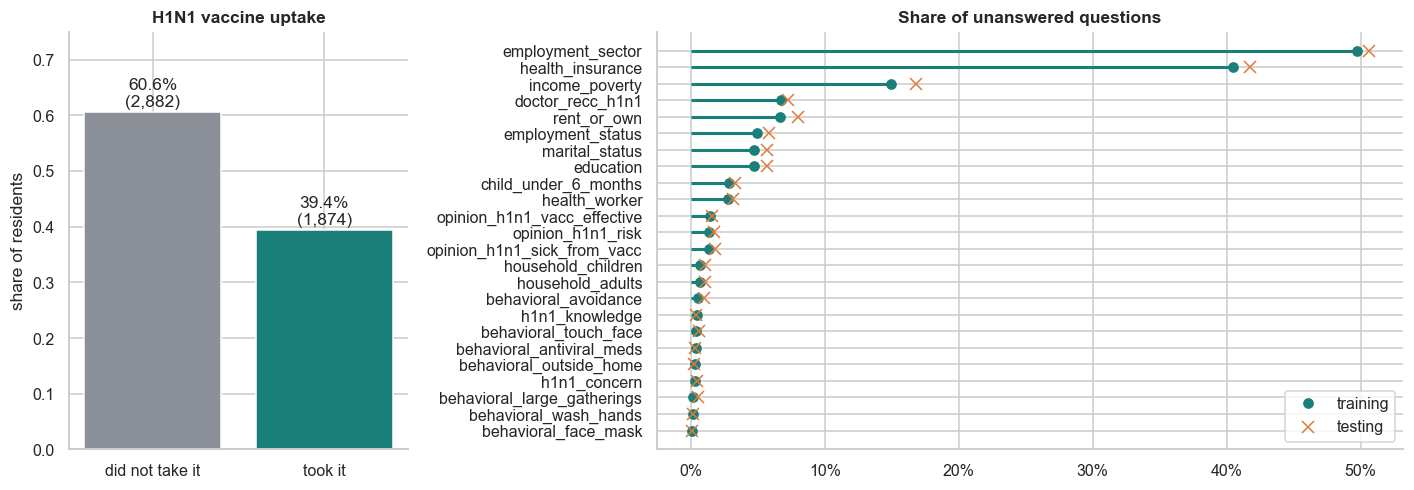

uptake in training: 0.394


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 2.2]})

# left: share who took the H1N1 vaccine
share = train[TARGET].value_counts(normalize=True).sort_index()
ax[0].bar(["did not take it", "took it"], share.values, color=[GREY, TEAL])
for i, v in enumerate(share.values):
    ax[0].text(i, v + 0.01, f"{v:.1%}\n({int(v * len(train)):,})", ha="center")
ax[0].set_ylim(0, 0.75); ax[0].set_ylabel("share of residents"); ax[0].set_title("H1N1 vaccine uptake")

# right: missing share per question, training against testing
miss = pd.DataFrame({"train": train[RAW].isna().mean(), "test": test[RAW].isna().mean()})
miss = miss[miss.max(axis=1) > 0].sort_values("train")
ypos = np.arange(len(miss))
ax[1].hlines(ypos, 0, miss["train"], color=TEAL, lw=2)
ax[1].plot(miss["train"], ypos, "o", color=TEAL, label="training")
ax[1].plot(miss["test"], ypos, "x", color=ORANGE, ms=8, label="testing")
ax[1].set_yticks(ypos); ax[1].set_yticklabels(miss.index)
ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax[1].set_title("Share of unanswered questions"); ax[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

print(f"uptake in training: {train[TARGET].mean():.3f}")

About four in ten residents took the vaccine, so the two groups are uneven but neither is rare. Folds are stratified so that each one keeps this share. The missing pattern is almost identical in the two files, which means whatever we do about gaps in training will meet the same gaps in testing.

### Q2.2 Is a gap just a gap, or does it say something?
For every question with at least 1% missing we compare the uptake of people who answered with the uptake of people who did not. The bars are 95% Wilson intervals. We also count how many questions each resident skipped.

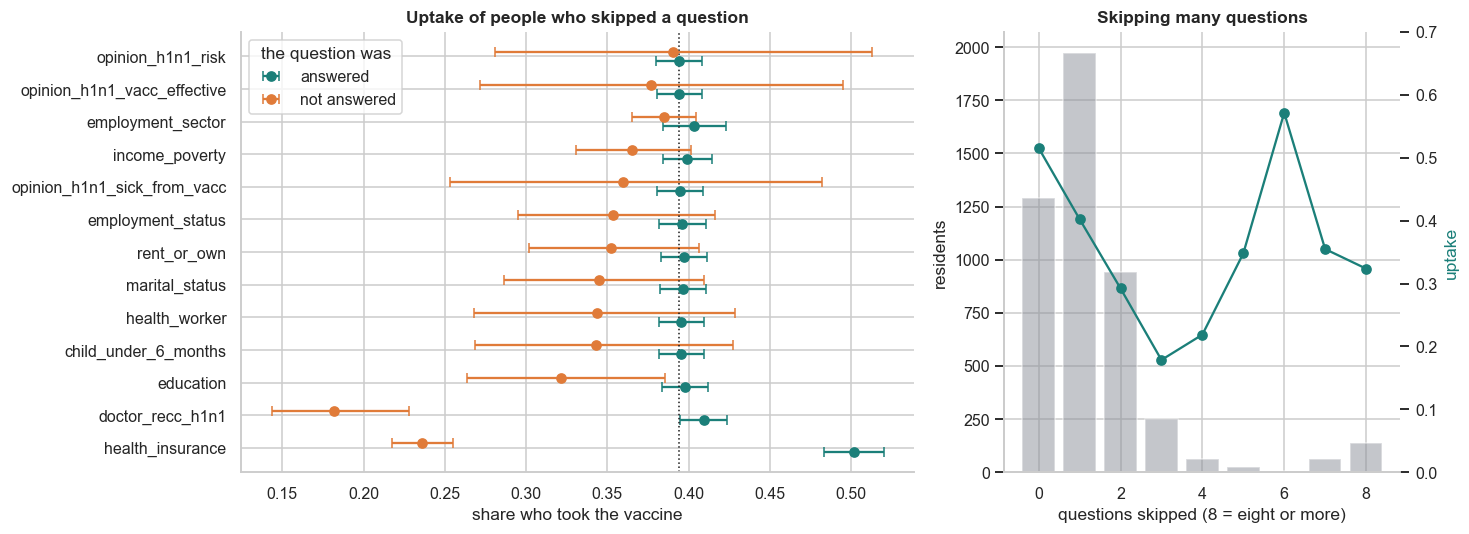

In [ ]:
def wilson(k, n, z=1.96):
    """95% Wilson interval for a proportion (works for small groups, unlike mean +/- 2 se)."""
    if n == 0:
        return np.nan, np.nan
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return centre - half, centre + half

gap_cols = [c for c in RAW if train[c].isna().mean() >= 0.01]
rows = []
for c in gap_cols:
    for label, mask in (("answered", train[c].notna()), ("not answered", train[c].isna())):
        k, n = int(y[mask].sum()), int(mask.sum())
        lo, hi = wilson(k, n)
        rows.append({"question": c, "group": label, "uptake": k / n, "lo": lo, "hi": hi, "n": n})
gap = pd.DataFrame(rows)

fig, ax = plt.subplots(1, 2, figsize=(13.5, 5), gridspec_kw={"width_ratios": [1.7, 1]})
order = (gap.pivot(index="question", columns="group", values="uptake")
            .assign(d=lambda t: t["not answered"] - t["answered"]).sort_values("d").index)
for j, (label, colour) in enumerate((("answered", TEAL), ("not answered", ORANGE))):
    g = gap[gap.group == label].set_index("question").loc[order]
    pos = np.arange(len(order)) + (j - 0.5) * 0.28
    ax[0].errorbar(g["uptake"], pos, xerr=[g["uptake"] - g["lo"], g["hi"] - g["uptake"]],
                   fmt="o", color=colour, capsize=3, label=label)
ax[0].axvline(y.mean(), color="k", ls=":", lw=1)
ax[0].set_yticks(np.arange(len(order))); ax[0].set_yticklabels(order)
ax[0].set_xlabel("share who took the vaccine"); ax[0].legend(title="the question was")
ax[0].set_title("Uptake of people who skipped a question")

# right: number of skipped questions per resident
n_skipped = train[RAW].isna().sum(axis=1).clip(upper=8)
by = pd.DataFrame({"skipped": n_skipped, "took": y}).groupby("skipped")["took"].agg(["mean", "size"])
ax[1].bar(by.index, by["size"], color=GREY, alpha=0.5)
ax[1].set_xlabel("questions skipped (8 = eight or more)"); ax[1].set_ylabel("residents")
twin = ax[1].twinx(); twin.plot(by.index, by["mean"], "o-", color=TEAL); twin.grid(False)
twin.set_ylabel("uptake", color=TEAL); twin.set_ylim(0, 0.7)
ax[1].set_title("Skipping many questions")
plt.tight_layout(); plt.show()

Missing answers are not random. People who did not say whether a doctor recommended the vaccine, or did not report health insurance, take the vaccine clearly less often than those who answered, and uptake falls steadily from residents who answered everything to those who skipped three questions (beyond that the groups are small). So we must not hide gaps by filling them with the most common answer. In Q4 we test recipes that keep "not answered" as information against recipes that hide it.

### Q2.3 Opinions and knowledge
Five questions are answered on a scale. Each pair of bars shows how the answers are spread among people who refused (top) and people who took the vaccine (bottom).

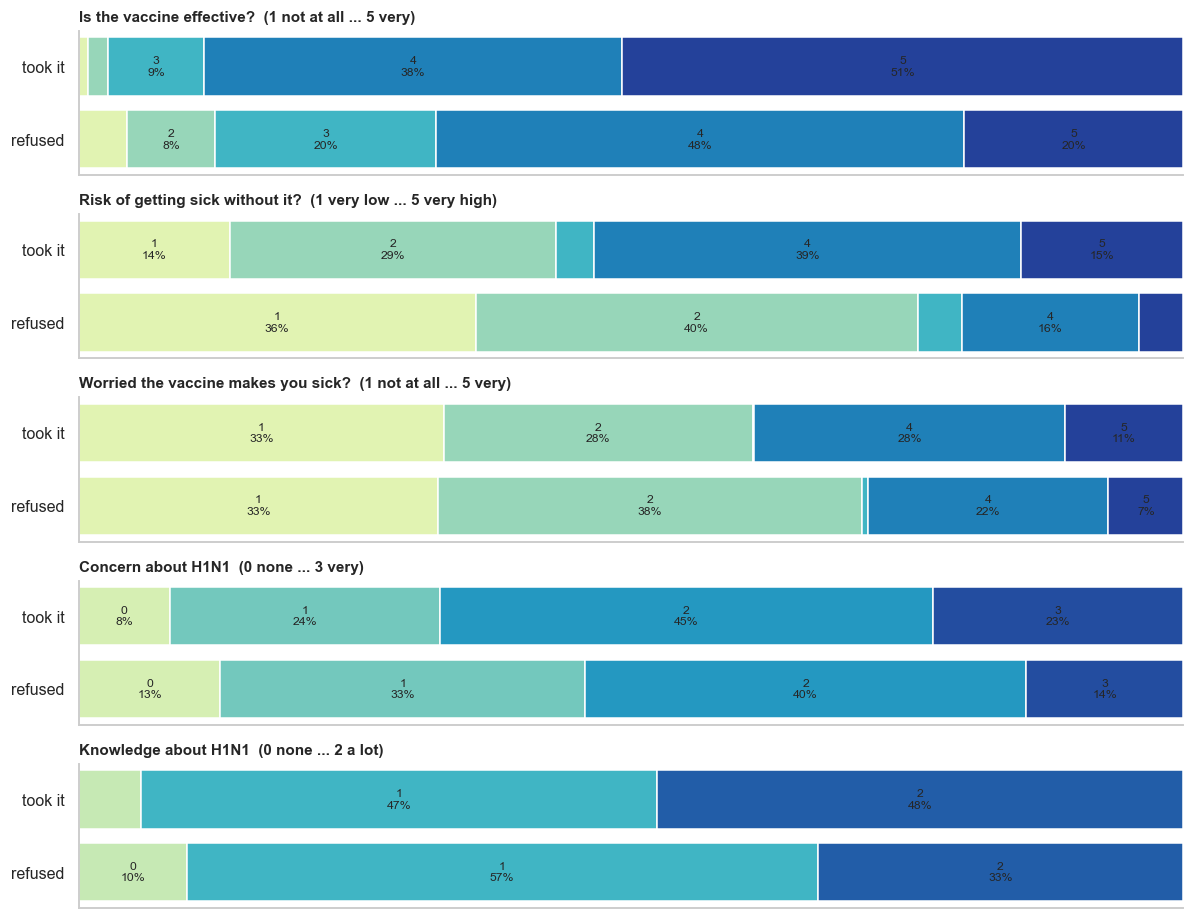

In [ ]:
SCALES = {
    "opinion_h1n1_vacc_effective": "Is the vaccine effective?  (1 not at all ... 5 very)",
    "opinion_h1n1_risk": "Risk of getting sick without it?  (1 very low ... 5 very high)",
    "opinion_h1n1_sick_from_vacc": "Worried the vaccine makes you sick?  (1 not at all ... 5 very)",
    "h1n1_concern": "Concern about H1N1  (0 none ... 3 very)",
    "h1n1_knowledge": "Knowledge about H1N1  (0 none ... 2 a lot)",
}
fig, axes = plt.subplots(len(SCALES), 1, figsize=(11, 8.5))
for ax, (col, title) in zip(axes, SCALES.items()):
    levels = sorted(train[col].dropna().unique())
    colours = sns.color_palette("YlGnBu", len(levels))
    for row, grp in enumerate((0, 1)):
        dist = train.loc[y == grp, col].value_counts(normalize=True).reindex(levels).fillna(0)
        left = 0
        for lv, colr in zip(levels, colours):
            ax.barh(row, dist[lv], left=left, color=colr, edgecolor="white")
            if dist[lv] > 0.06:
                ax.text(left + dist[lv] / 2, row, f"{int(lv)}\n{dist[lv]:.0%}", ha="center", va="center", fontsize=8)
            left += dist[lv]
    ax.set_yticks([0, 1]); ax.set_yticklabels(["refused", "took it"]); ax.set_xlim(0, 1)
    ax.set_xticks([]); ax.set_title(title, loc="left", fontsize=10); ax.grid(False)
plt.tight_layout(); plt.show()

The clearest separation is in the first two questions: people who took the vaccine mostly rate it as effective (4 or 5) and rate their own risk higher. Worry about side effects and general concern separate the groups much less. Answer `3` means "don't know", so these scales are not perfectly ordered, which is one reason to try tree models that can split a scale anywhere.

### Q2.4 Uptake for every answer of every question
One small panel per question, so that no column is left unexamined. Dots are uptake with a 95% interval, the dotted line is the overall uptake, and `n/a` is "not answered". `employment_sector` has 21 answers and gets its own plot.

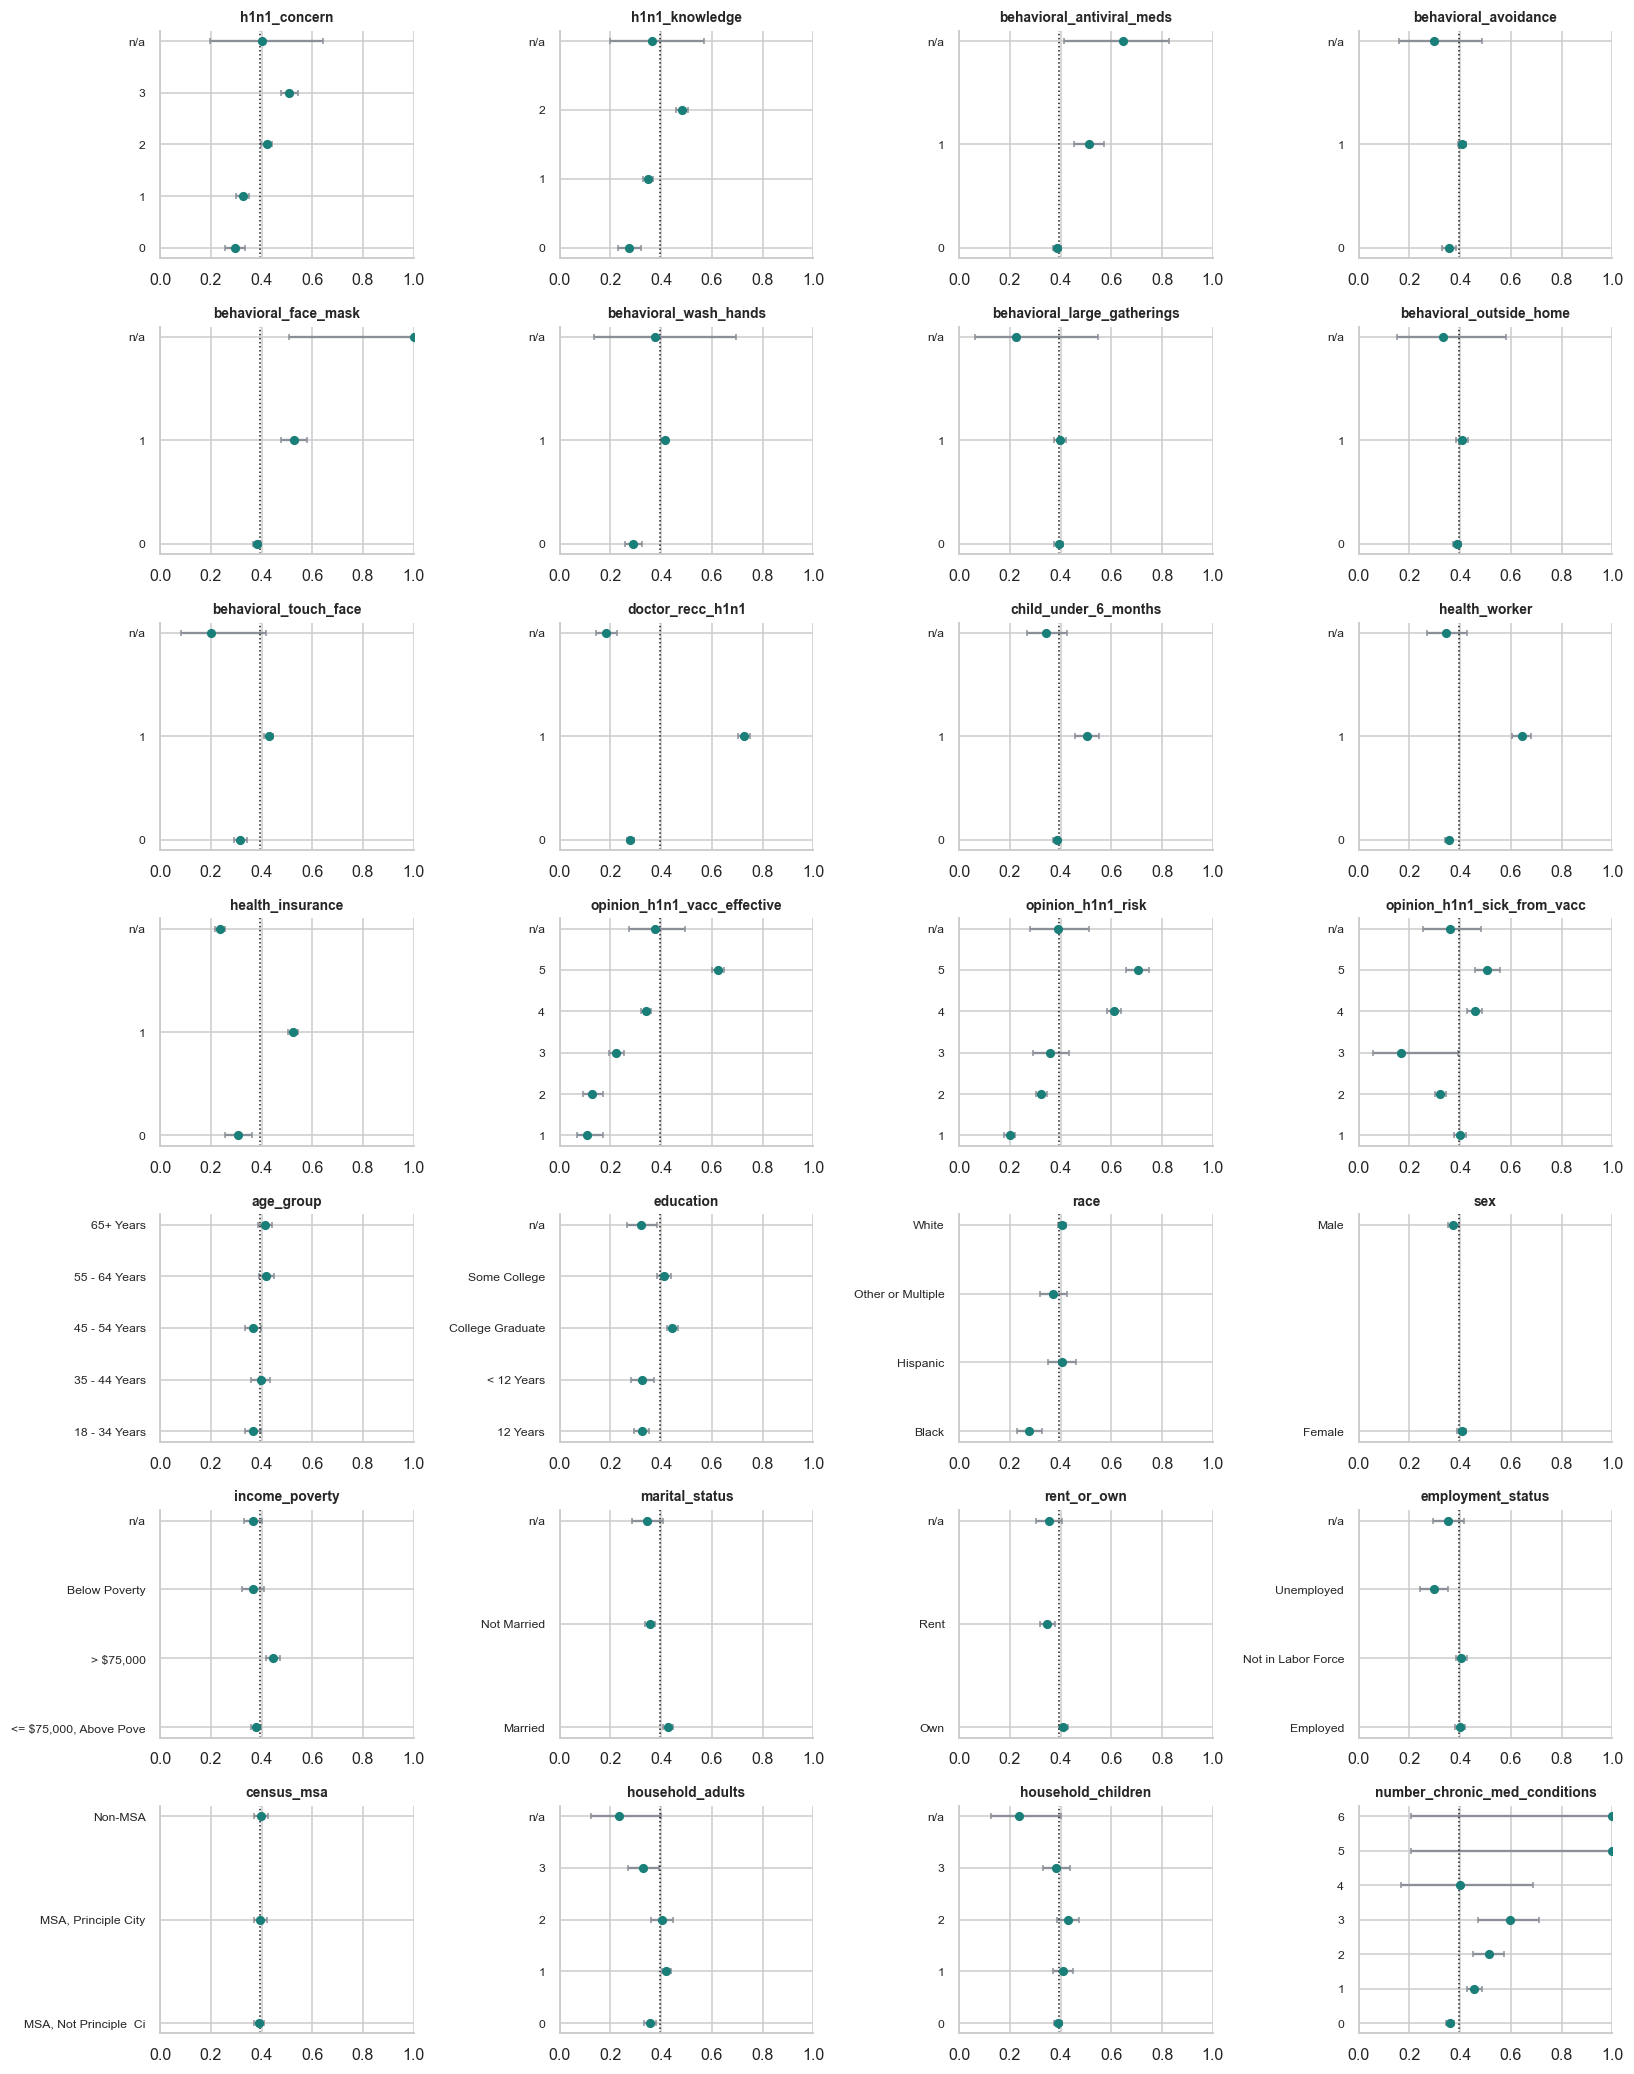

In [ ]:
def uptake_table(col):
    """Uptake, interval and group size for each answer of one question (missing = 'n/a')."""
    s = train[col].copy()
    s = s.map(lambda v: "n/a" if pd.isna(v) else (str(int(v)) if isinstance(v, (int, float)) else str(v)))
    out = []
    for level, idx in s.groupby(s).groups.items():
        k, n = int(train.loc[idx, TARGET].sum()), len(idx)
        lo, hi = wilson(k, n)
        out.append({"answer": level, "uptake": k / n, "lo": lo, "hi": hi, "n": n})
    return pd.DataFrame(out)

panel_cols = [c for c in RAW if c != "employment_sector"]
fig, axes = plt.subplots(7, 4, figsize=(15, 19))
for ax, col in zip(axes.ravel(), panel_cols):
    t = uptake_table(col)
    pos = np.arange(len(t))
    ax.errorbar(t["uptake"], pos, xerr=[t["uptake"] - t["lo"], t["hi"] - t["uptake"]],
                fmt="o", color=TEAL, ecolor=GREY, capsize=2, ms=5)
    ax.axvline(y.mean(), color="k", ls=":", lw=1)
    ax.set_yticks(pos); ax.set_yticklabels([a[:22] for a in t["answer"]], fontsize=8)
    ax.set_xlim(0, 1); ax.set_title(col, fontsize=9)
plt.tight_layout(); plt.show()

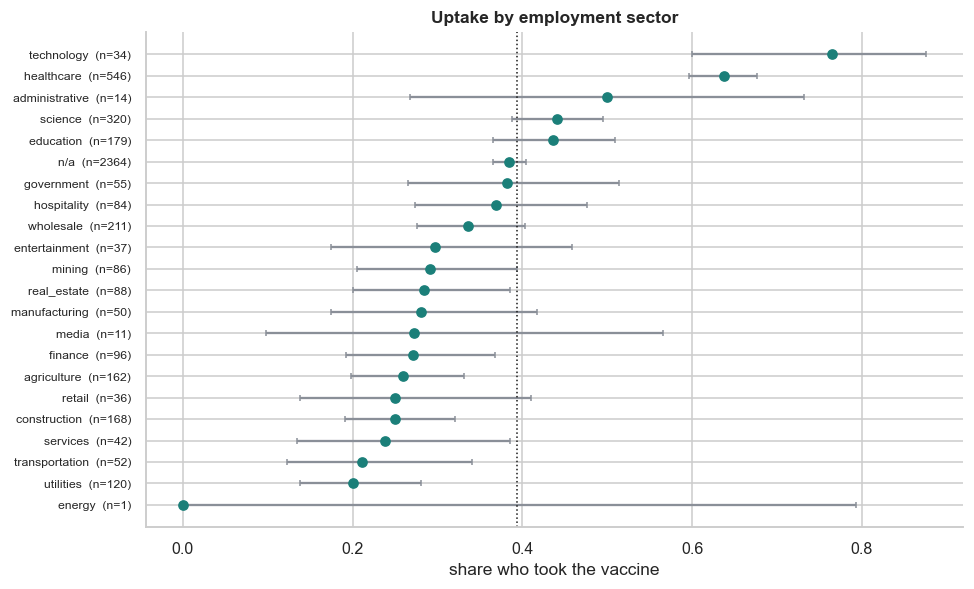

In [ ]:
t = uptake_table("employment_sector").sort_values("uptake")
fig, ax = plt.subplots(figsize=(9, 5.5))
pos = np.arange(len(t))
ax.errorbar(t["uptake"], pos, xerr=[t["uptake"] - t["lo"], t["hi"] - t["uptake"]], fmt="o",
            color=TEAL, ecolor=GREY, capsize=2)
ax.axvline(y.mean(), color="k", ls=":", lw=1)
ax.set_yticks(pos); ax.set_yticklabels([f"{a}  (n={n})" for a, n in zip(t["answer"], t["n"])], fontsize=8)
ax.set_xlabel("share who took the vaccine"); ax.set_title("Uptake by employment sector")
plt.tight_layout(); plt.show()

What stands out:

* **A doctor's recommendation** is the single strongest answer: uptake is far above average with it and well below without it.
* **Health workers** and people in the `healthcare` sector take the vaccine much more often than anyone else. Several sectors have fewer than 40 people and very wide intervals, so rare sectors are grouped together in the one-hot recipes instead of being trusted one by one.
* **Chronic conditions** raise uptake step by step, and so does having health insurance.
* Age, sex, race, housing and region move uptake only a little. Age still matters a lot for the *cost*, because it sets the hospital risk (Q3).

### Q2.5 Do the strong signals add up or interact?
If the lift from a doctor's recommendation is the same whatever the person believes, a straight-line model captures it. If it depends on the belief, we need an interaction feature or a tree model.

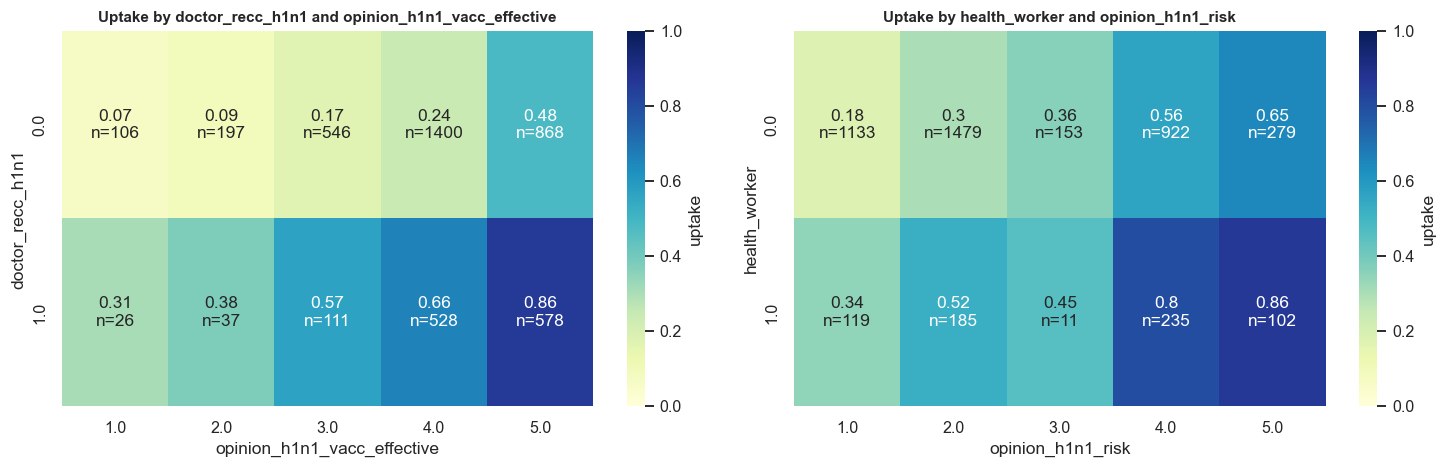

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.4))
pairs = [("doctor_recc_h1n1", "opinion_h1n1_vacc_effective"), ("health_worker", "opinion_h1n1_risk")]
for a, (r, c) in zip(ax, pairs):
    rate = train.pivot_table(index=r, columns=c, values=TARGET, aggfunc="mean")
    count = train.pivot_table(index=r, columns=c, values=TARGET, aggfunc="size")
    labels = rate.round(2).astype(str) + "\nn=" + count.astype(int).astype(str)
    sns.heatmap(rate, annot=labels, fmt="", cmap="YlGnBu", vmin=0, vmax=1, ax=a, cbar_kws={"label": "uptake"})
    a.set_title(f"Uptake by {r} and {c}", fontsize=10)
plt.tight_layout(); plt.show()

A doctor's recommendation lifts uptake at every belief level, but not by the same amount: the lift is largest for people in the middle and upper part of the scale. Without a recommendation, uptake only approaches one half for people who rate the vaccine as very effective. The effect is not purely additive, so we add a combined feature (`doctor_and_effective`) for the linear models and expect tree models to find this on their own.

### Q2.6 Ranking all 29 questions by how much they tell us
**Information value** (borrowed from credit scoring) gives one number per question: it compares how the takers and the refusers are spread over the answers, with "not answered" counted as an answer. A common rule of thumb is: under 0.02 useless, 0.02 to 0.1 weak, 0.1 to 0.3 medium, above 0.3 strong.

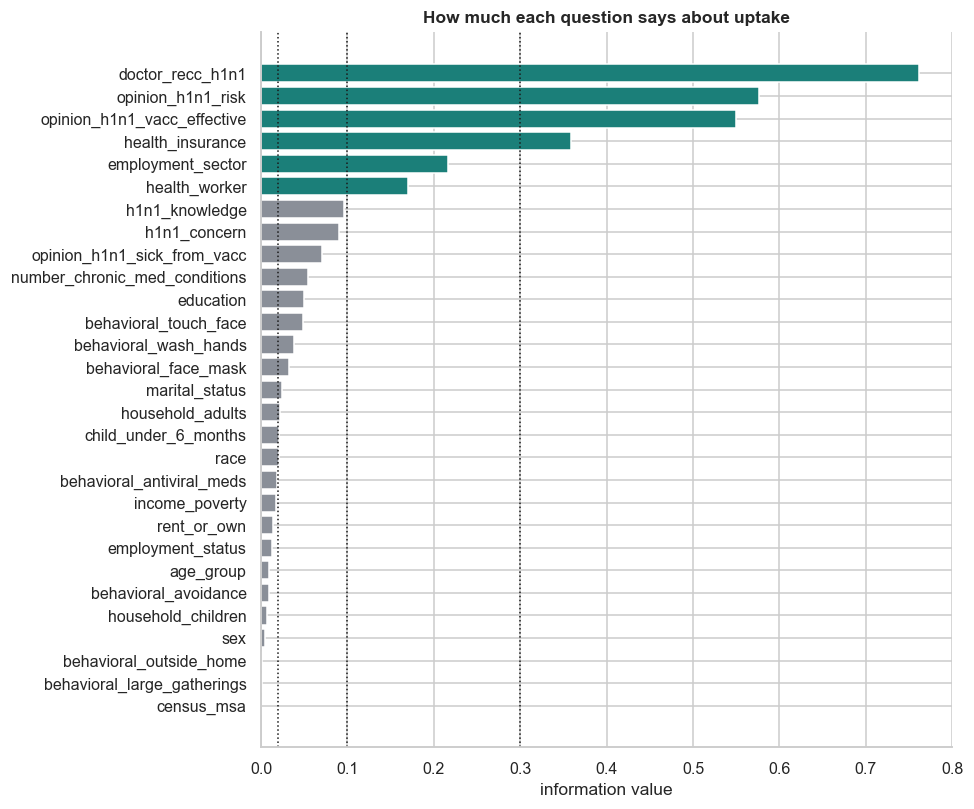

doctor_recc_h1n1               0.762
opinion_h1n1_risk              0.577
opinion_h1n1_vacc_effective    0.550
health_insurance               0.359
employment_sector              0.217
health_worker                  0.170
h1n1_knowledge                 0.096
h1n1_concern                   0.090


In [ ]:
def information_value(col, frame=train, target=y):
    """Sum over answers of (share of takers - share of refusers) * log ratio, missing kept as an answer."""
    s = frame[col].astype(object).where(frame[col].notna(), "n/a")
    tab = pd.crosstab(s, target)
    took = (tab[1] + 0.5) / (tab[1].sum() + 0.5 * len(tab))      # +0.5 avoids log(0) in tiny groups
    refused = (tab[0] + 0.5) / (tab[0].sum() + 0.5 * len(tab))
    return float(((took - refused) * np.log(took / refused)).sum())

iv = pd.Series({c: information_value(c) for c in RAW}).sort_values()
fig, ax = plt.subplots(figsize=(9, 7.5))
ax.barh(iv.index, iv.values, color=[TEAL if v >= 0.1 else GREY for v in iv.values])
for cut in (0.02, 0.1, 0.3):
    ax.axvline(cut, color="k", ls=":", lw=1)
ax.set_xlabel("information value"); ax.set_title("How much each question says about uptake")
plt.tight_layout(); plt.show()
print(iv.sort_values(ascending=False).head(8).round(3).to_string())

A handful of questions carry most of the signal: the doctor's recommendation, the two opinion scales, health insurance, employment sector and health-worker status. Most demographic questions sit in the weak band. No question is dropped: weak signals are cheap to keep, the regularised models shrink them, and Q4 checks whether a compressed version of the data (PCA) does any better.

### Q2.7 Which questions repeat each other?
Questions that move together carry overlapping information. The tree groups numeric questions by Spearman correlation (missing pairs skipped); the heatmap is ordered the same way.

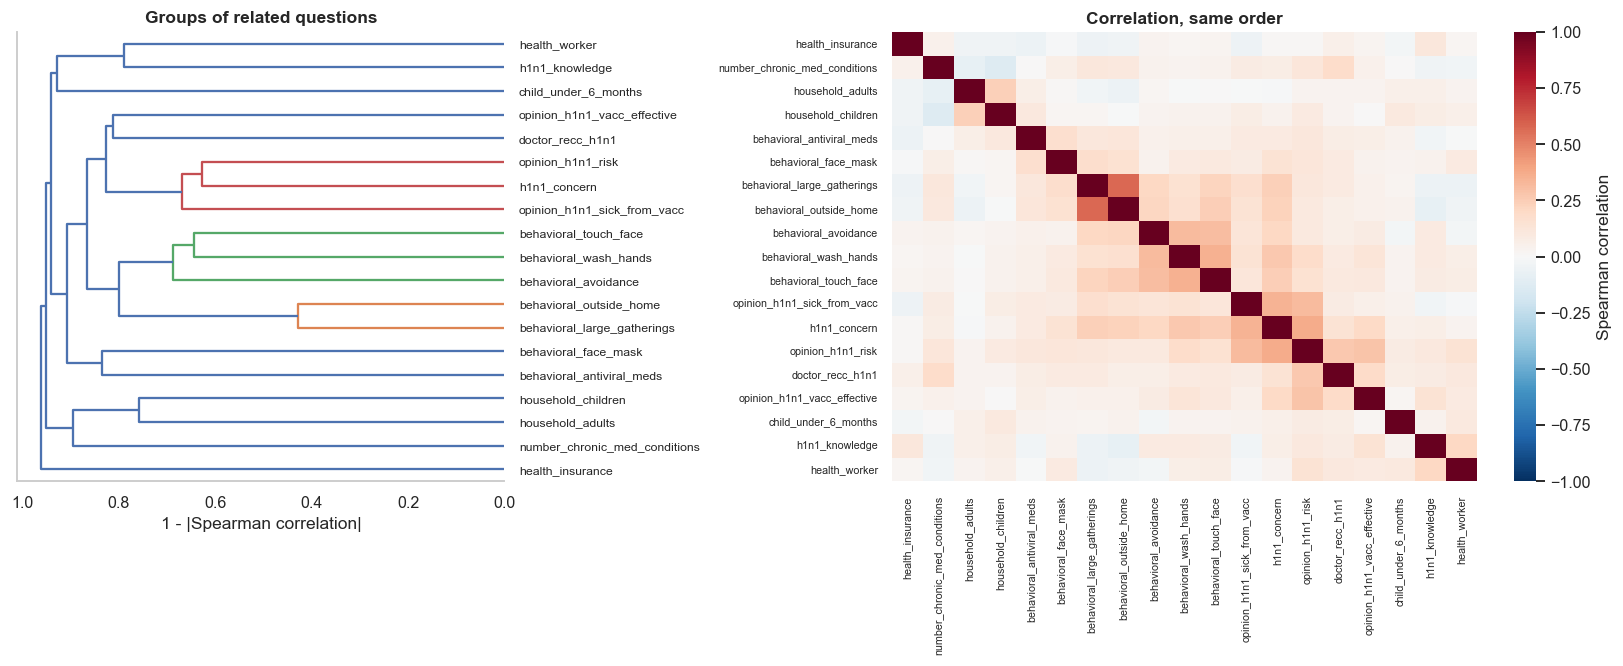

strongest pairs:
behavioral_large_gatherings  behavioral_outside_home        0.57
h1n1_concern                 opinion_h1n1_risk              0.37
behavioral_wash_hands        behavioral_touch_face          0.36
h1n1_concern                 opinion_h1n1_sick_from_vacc    0.34
behavioral_avoidance         behavioral_wash_hands          0.32
opinion_h1n1_risk            opinion_h1n1_sick_from_vacc    0.32


In [ ]:
corr = train[NUM].corr(method="spearman")
link = hierarchy.linkage(1 - corr.abs().values[np.triu_indices(len(corr), 1)], method="average")
order = hierarchy.leaves_list(link)
fig, ax = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw={"width_ratios": [1, 1.5]})
hierarchy.dendrogram(link, labels=corr.index.tolist(), orientation="left", ax=ax[0], color_threshold=0.7,
                     leaf_font_size=8)
ax[0].set_xlabel("1 - |Spearman correlation|"); ax[0].set_title("Groups of related questions"); ax[0].grid(False)
ordered = corr.iloc[order, order]
sns.heatmap(ordered, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax[1], xticklabels=True, yticklabels=True,
            cbar_kws={"label": "Spearman correlation"})
ax[1].tick_params(labelsize=7); ax[1].set_title("Correlation, same order")
plt.tight_layout(); plt.show()

strong = (corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().sort_values(key=abs, ascending=False).head(6))
print("strongest pairs:"); print(strong.round(2).to_string())

The protective behaviours form one loose family (people who avoid gatherings also reduce outside contact), and concern goes with them. None of the correlations is close to 1, so there are no duplicate columns to remove. Because the behaviours overlap, we add a single count of them (`n_precautions`) as a compact summary.

### Q2.8 Can the residents be separated in two dimensions?
A principal component analysis of the fully encoded data shows how much of the variation a few directions hold, and whether takers and refusers form separate clouds.

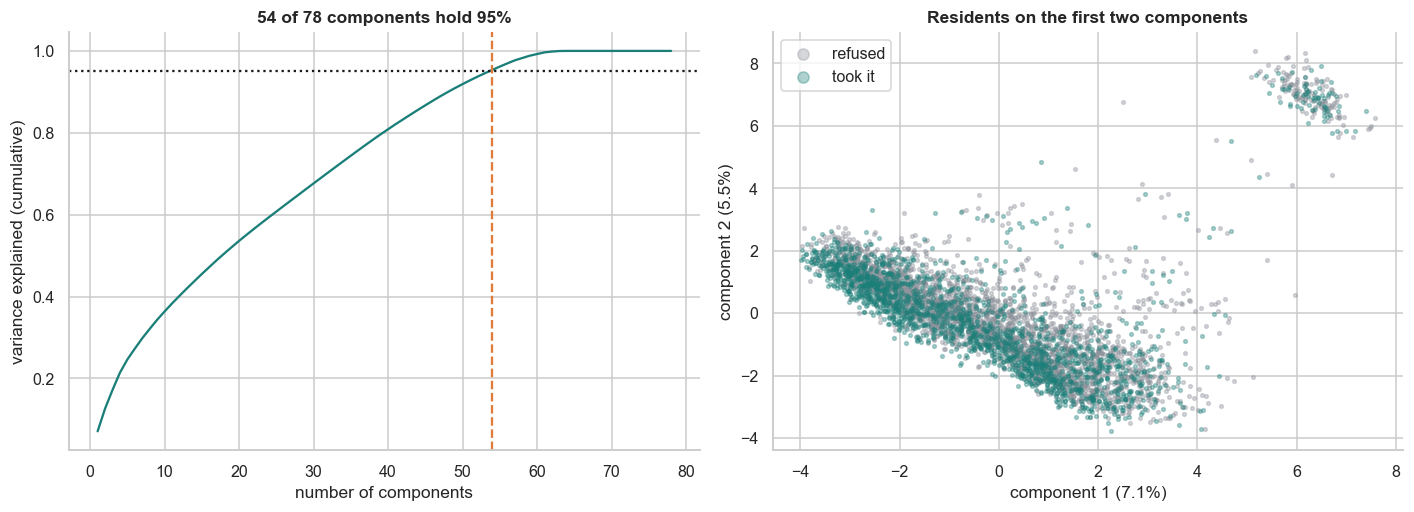

In [ ]:
# quick encoding just for this picture: medians for gaps, one-hot for text, then standardise
encoded = pd.get_dummies(train[RAW].fillna(train[NUM].median()), columns=CAT, dummy_na=True, dtype=float)
encoded = (encoded - encoded.mean()) / encoded.std().replace(0, 1)
pca = PCA(random_state=SEED).fit(encoded)
scores = pca.transform(encoded)[:, :2]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
cum = np.cumsum(pca.explained_variance_ratio_)
ax[0].plot(np.arange(1, len(cum) + 1), cum, color=TEAL)
n95 = int(np.searchsorted(cum, 0.95) + 1)
ax[0].axhline(0.95, color="k", ls=":"); ax[0].axvline(n95, color=ORANGE, ls="--")
ax[0].set_xlabel("number of components"); ax[0].set_ylabel("variance explained (cumulative)")
ax[0].set_title(f"{n95} of {encoded.shape[1]} components hold 95%")
for grp, colour, lab in ((0, GREY, "refused"), (1, TEAL, "took it")):
    m = y == grp
    ax[1].scatter(scores[m, 0], scores[m, 1], s=6, alpha=0.35, color=colour, label=lab)
ax[1].set_xlabel(f"component 1 ({pca.explained_variance_ratio_[0]:.1%})")
ax[1].set_ylabel(f"component 2 ({pca.explained_variance_ratio_[1]:.1%})")
ax[1].legend(markerscale=3); ax[1].set_title("Residents on the first two components")
plt.tight_layout(); plt.show()

The variation is spread thinly over many directions (the first two components hold only a small share), and the two groups overlap heavily in this view. The small separate cloud is the group of residents who skipped many questions at once (Q2.2), not a group of takers or refusers. So there is no easy low-dimensional split, and compressing the data is unlikely to help. We still test a PCA recipe in Q4 to confirm that with numbers instead of assuming it.

### Q2.9 Is the test file the same kind of town?
Cross-validated costs only carry over to the hidden test set if both files come from the same population. The **population stability index** compares the answer shares of each question in the two files. Values under 0.1 are normally read as "no shift".

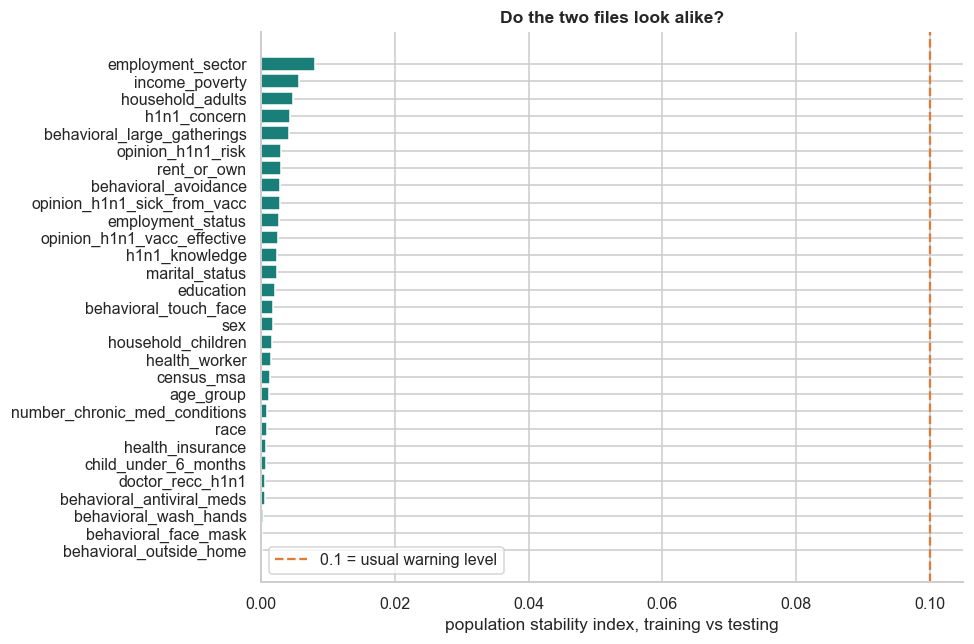

largest index: 0.0080 (employment_sector)


In [ ]:
def stability_index(col):
    """PSI between training and testing answer shares (missing kept as an answer)."""
    a = train[col].astype(object).where(train[col].notna(), "n/a").value_counts(normalize=True)
    b = test[col].astype(object).where(test[col].notna(), "n/a").value_counts(normalize=True)
    a, b = a.align(b, fill_value=0)
    a, b = a + 1e-4, b + 1e-4
    return float(((a - b) * np.log(a / b)).sum())

psi = pd.Series({c: stability_index(c) for c in RAW}).sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(psi.index, psi.values, color=TEAL)
ax.axvline(0.1, color=ORANGE, ls="--", label="0.1 = usual warning level")
ax.set_xlabel("population stability index, training vs testing"); ax.legend()
ax.set_title("Do the two files look alike?")
plt.tight_layout(); plt.show()
print(f"largest index: {psi.max():.4f} ({psi.idxmax()})")

Every question is far below the warning level, so the test residents look like the training residents and cross-validation on the training file is a fair guide to the hidden score.

### Q2.10 What the exploration decided

| What we saw | Where | What we did about it |
|---|---|---|
| About 39% took the vaccine | Q2.1 | stratified folds; no resampling, because we need honest probabilities, not balanced classes |
| Two questions are 40 to 50% unanswered, and skipping a question goes with lower uptake | Q2.1, Q2.2 | keep "not answered" as its own answer / flag; add `n_unanswered`; compare against plain filling in Q4 |
| Scales include a "don't know" middle value, signals interact | Q2.3, Q2.5 | try tree models next to linear ones; add `doctor_and_effective` |
| A few questions hold most of the signal, none is a duplicate | Q2.6, Q2.7 | keep all 29; regularise; add `n_precautions` |
| Health worker and healthcare sector overlap | Q2.4 | add `health_job` (either of the two) |
| Rare sectors have very wide intervals | Q2.4 | group answers with fewer than 25 people in the one-hot recipes |
| No low-dimensional separation | Q2.8 | PCA is tested, not assumed |
| Training and testing files match | Q2.9 | trust cross-validation for the ranking |
| Age and chronic conditions barely change uptake but drive hospital risk | Q2.4, Q3 | they enter the cost through the risk model and the personal cut-off |

## Q3. What exactly is the bill?
### Q3.1 The rules, turned into a table
From the dataset sheet and the target-metric sheet:

* everyone in the town catches H1N1 (100% infection);
* a posted vaccine costs **$500**, whether or not the resident uses it;
* a resident who **wants** a vaccine but is **not** sent one is paid **$500 in cash** and stays unvaccinated;
* a hospital stay costs **$25,000**; the chance of needing one depends on the person and is lower if they are vaccinated.

`h1n1_vaccine = 1` means the resident takes a vaccine when offered. Writing `r_u` for a resident's hospital risk unvaccinated and `r_v` for the risk vaccinated:

| | resident wants it (`y = 1`) | resident does not (`y = 0`) |
|---|---|---|
| **we post a vaccine (`s = 1`)** | `500 + r_v x 25,000` (vaccinated) | `500 + r_u x 25,000` (dose wasted) |
| **we do not (`s = 0`)** | `500 + r_u x 25,000` (cash paid, unprotected) | `r_u x 25,000` |

The town's bill is the sum of these over all residents. The hospital part is an expected cost, because whether one person ends up in hospital is chance.

Two things follow directly from the table. Someone who wants the vaccine costs the town $500 either way, so posting to them can only **save** money (the drop in hospital risk). Someone who does not want it costs an extra $500 if we post. So the whole problem is: post only where the expected hospital saving outweighs the risk of wasting a dose.

In [ ]:
def town_bill(wants, sent, r_u, r_v, per_resident=True, V=VACCINE_COST, H=HOSPITAL_COST):
    """Expected money spent by the town.

    wants : 1 if the resident takes a vaccine when offered (the target), else 0
    sent  : 1 if we post a vaccine, else 0
    r_u, r_v : hospital risk of each resident without / with the vaccine
    """
    wants, sent = np.asarray(wants).astype(int), np.asarray(sent).astype(int)
    paid_500 = (sent == 1) | (wants == 1)                 # a dose or the cash, never both
    protected = (sent == 1) & (wants == 1)                # only a used dose protects
    cost = V * paid_500 + H * np.where(protected, r_v, r_u)
    return float(cost.mean() if per_resident else cost.sum())

# hand check on four made-up residents, one per cell of the table (risk 2% without, 1% with)
ru_demo, rv_demo = np.full(4, 0.02), np.full(4, 0.01)
by_hand = [500 + 0.01 * 25000,     # sent, wants      -> 750
           500 + 0.02 * 25000,     # sent, refuses    -> 1000
           500 + 0.02 * 25000,     # not sent, wants  -> 1000
           0.02 * 25000]           # not sent, refuses -> 500
got = town_bill([1, 0, 1, 0], [1, 1, 0, 0], ru_demo, rv_demo, per_resident=False)
assert np.isclose(got, sum(by_hand)), (got, sum(by_hand))
print("hand check passed: total for the four cells =", got)

hand check passed: total for the four cells = 3250.0


### Q3.2 From a probability to a decision
A model gives `q`, the probability that a resident takes the vaccine. Using the table:

* expected cost if we post: `500 + r_u x H - q x (r_u - r_v) x H`
* expected cost if we do not: `q x 500 + r_u x H`

Posting is cheaper when `500 x (1 - q) < q x (r_u - r_v) x H`, which rearranges to

**post a vaccine when `q > 500 / (500 + (r_u - r_v) x 25,000)`.**

This cut-off is different for every resident. The larger the hospital saving `(r_u - r_v) x 25,000`, the less sure we need to be. A single cut-off such as 0.5 ignores this. Q6.5 measures how much that costs.

In [ ]:
def personal_cutoff(r_u, r_v, V=VACCINE_COST, H=HOSPITAL_COST):
    """Smallest acceptance probability at which posting a vaccine is the cheaper choice."""
    return V / (V + (np.asarray(r_u) - np.asarray(r_v)) * H)

# check the algebra numerically: at the cut-off both choices must cost the same
q_star = personal_cutoff(0.02, 0.01)
post = 500 + 0.02 * 25000 - q_star * (0.02 - 0.01) * 25000
dont = q_star * 500 + 0.02 * 25000
assert np.isclose(post, dont)
print(f"example: risk 2% -> 1%, cut-off = {q_star:.3f}; expected cost either way = ${post:,.2f}")

example: risk 2% -> 1%, cut-off = 0.667; expected cost either way = $833.33


### Q3.3 Hospital risk: what several AIs say
The metric sheet tells us to estimate the hospital probabilities with generative AI and to ask more than one. The same question was put to three models separately on 11 November 2026, without web access:

> *A US town survey of adults (18+), 2009 H1N1 pandemic. Assume every resident is infected. Give (1) P(hospitalised | infected, unvaccinated, no chronic conditions) for ages 18-34, 35-44, 45-54, 55-64, 65+; (2) effectiveness of the 2009 H1N1 vaccine against hospitalisation; (3) a multiplier per additional chronic condition; (4) any other survey factor that should change the risk. State caveats and sources.*

| | 18-34 | 35-44 | 45-54 | 55-64 | 65+ | vaccine effect | per condition |
|---|---|---|---|---|---|---|---|
| AI 1 (Claude Sonnet) | 0.0030 | 0.0040 | 0.0060 | 0.0080 | 0.0100 | 0.60 | x3.0 |
| AI 2 (Claude Haiku) | 0.0025 | 0.0035 | 0.0045 | 0.0060 | 0.0030 | 0.70 | x2.0 |
| AI 3 (Claude Opus) | 0.0020 | 0.0030 | 0.0040 | 0.0050 | 0.0080 | 0.65 | x2.0 |

What they agreed on: the starting point is the CDC burden estimate for 2009-10 (about 61 million cases and 274,000 hospital stays in the US, roughly 0.45% of cases), scaled down for people with no chronic condition; healthcare-worker status and contact with a baby change *exposure*, which no longer matters once everyone is infected, so those get no multiplier; pregnancy and obesity matter but are not in our survey. Sources they named: Shrestha et al. 2011, Reed et al. 2009, Presanis et al. 2009, Jain et al. 2009, Griffin et al. 2011.

Where they disagreed: the **65+ group** (AI 2 put it below the middle-aged groups, because in 2009 older adults had some prior immunity; the other two say that immunity lowered the chance of infection, not the risk once infected) and the **per-condition multiplier** (2 to 3). AI 3 also warned that multiplying once per condition overstates the risk for people with three or more conditions and suggested capping the combined effect at about x8.

All three said the numbers are recalled from memory and uncertain by a factor of about two. So we use the **average of the three**, apply the x8 cap, and stress-test the result in Q6.6, including a run with each AI's own numbers. *Teammates can add rows (for example from ChatGPT or Gemini) to `AI_ANSWERS` below and re-run.*

In [ ]:
AGE_GROUPS = ["18 - 34 Years", "35 - 44 Years", "45 - 54 Years", "55 - 64 Years", "65+ Years"]

# one row per AI: risk by age group (infected, unvaccinated, no chronic condition), vaccine effect, multiplier
AI_ANSWERS = pd.DataFrame(
    [[0.0030, 0.0040, 0.0060, 0.0080, 0.0100, 0.60, 3.0],
     [0.0025, 0.0035, 0.0045, 0.0060, 0.0030, 0.70, 2.0],
     [0.0020, 0.0030, 0.0040, 0.0050, 0.0080, 0.65, 2.0]],
    index=["AI 1 (Claude Sonnet)", "AI 2 (Claude Haiku)", "AI 3 (Claude Opus)"],
    columns=AGE_GROUPS + ["vaccine_effect", "per_condition"])

def assumptions_from(row):
    """Pack one row of answers into the dictionary the risk model uses."""
    return {"age_risk": row[AGE_GROUPS].to_dict(), "vaccine_effect": float(row["vaccine_effect"]),
            "per_condition": float(row["per_condition"])}

BASE = assumptions_from(AI_ANSWERS.mean())            # the average of the AIs is our working assumption
CONDITION_CAP = 8.0                                   # combined effect of several conditions (AI 3's advice)

def hospital_risk(frame, assume=BASE, scale=1.0):
    """Hospital risk of each resident if infected: (unvaccinated, vaccinated).

    risk = age-group baseline x per_condition ** number of chronic conditions (capped), then
    reduced by the vaccine effect for a vaccinated resident. `scale` is used by the stress test.
    """
    base = frame["age_group"].map(assume["age_risk"]).to_numpy(float)
    n_conditions = frame["number_chronic_med_conditions"].to_numpy(float)
    r_u = np.clip(scale * base * np.minimum(assume["per_condition"] ** n_conditions, CONDITION_CAP), 0, 1)
    return r_u, r_u * (1 - assume["vaccine_effect"])

RU, RV = hospital_risk(train)                         # risks of the training residents
CUT = personal_cutoff(RU, RV)                         # and their personal cut-offs

pd.concat([AI_ANSWERS, AI_ANSWERS.mean().rename("used (average)").to_frame().T]).round(4)

,18 - 34 Years,35 - 44 Years,45 - 54 Years,55 - 64 Years,65+ Years,vaccine_effect,per_condition
AI 1 (Claude Sonnet),0.0030,0.0040,0.0060,0.0080,0.010,0.60,3.0000
AI 2 (Claude Haiku),0.0025,0.0035,0.0045,0.0060,0.003,0.70,2.0000
AI 3 (Claude Opus),0.0020,0.0030,0.0040,0.0050,0.008,0.65,2.0000
used (average),0.0025,0.0035,0.0048,0.0063,0.007,0.65,2.3333


### Q3.4 What the cut-off looks like for different residents
The left table is the hospital saving from one **accepted** dose, `(r_u - r_v) x $25,000`. The right table is the resulting cut-off: how sure we must be that the resident accepts before posting is worth it.

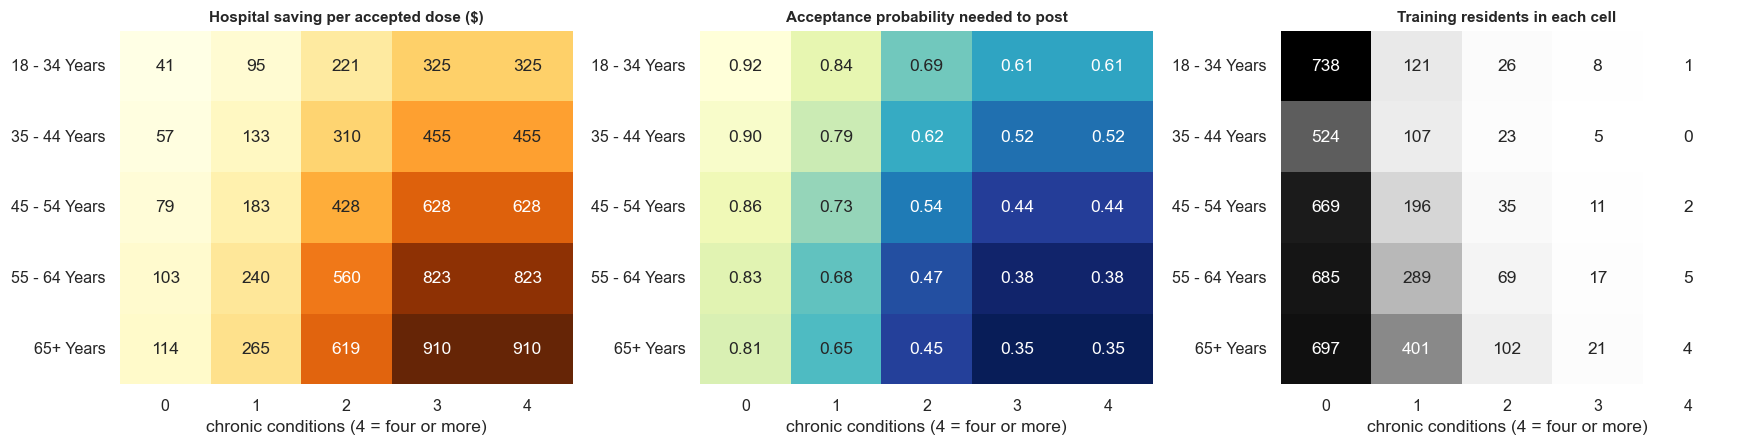

vaccine cost $500 against a typical saving of $103 per accepted dose (median resident)
min    0.355
25%    0.732
50%    0.829
75%    0.898
max    0.925


In [ ]:
grid = pd.DataFrame([(a, n) for a in AGE_GROUPS for n in range(5)], columns=["age_group", "number_chronic_med_conditions"])
g_ru, g_rv = hospital_risk(grid)
grid["saving"] = (g_ru - g_rv) * HOSPITAL_COST
grid["cutoff"] = personal_cutoff(g_ru, g_rv)
grid["residents"] = [int(((train.age_group == a) & (train.number_chronic_med_conditions.clip(upper=4) == n)).sum())
                     for a, n in zip(grid.age_group, grid.number_chronic_med_conditions)]

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for a, col, fmt, cmap, title in ((ax[0], "saving", ".0f", "YlOrBr", "Hospital saving per accepted dose ($)"),
                                 (ax[1], "cutoff", ".2f", "YlGnBu_r", "Acceptance probability needed to post"),
                                 (ax[2], "residents", "d", "Greys", "Training residents in each cell")):
    piv = grid.pivot(index="age_group", columns="number_chronic_med_conditions", values=col)
    sns.heatmap(piv, annot=True, fmt=fmt, cmap=cmap, ax=a, cbar=False)
    a.set_xlabel("chronic conditions (4 = four or more)"); a.set_ylabel(""); a.set_title(title, fontsize=10)
plt.tight_layout(); plt.show()

print(f"vaccine cost ${VACCINE_COST} against a typical saving of ${np.median((RU - RV) * HOSPITAL_COST):.0f} per accepted dose (median resident)")
print(pd.Series(CUT).describe()[["min", "25%", "50%", "75%", "max"]].round(3).to_string())

This picture explains the whole challenge. For a healthy adult, one accepted dose saves the town only a few tens of dollars in expected hospital cost, against $500 lost if the dose is refused. The model must therefore be very sure (well above 0.8) before a vaccine is posted to them. For residents with two or more chronic conditions the saving is several hundred dollars and the cut-off falls to between about 0.35 and 0.7. Most residents are in the left two columns, so we expect to post to a minority, and we expect the difference between good and poor models to be small in dollars per resident. That makes the measurement of random variation (Q6) especially important.

### Q3.5 Reference policies with no model
Any model has to beat the simple rules. "Perfect knowledge" posts exactly to the people who want a vaccine; no model can do better.

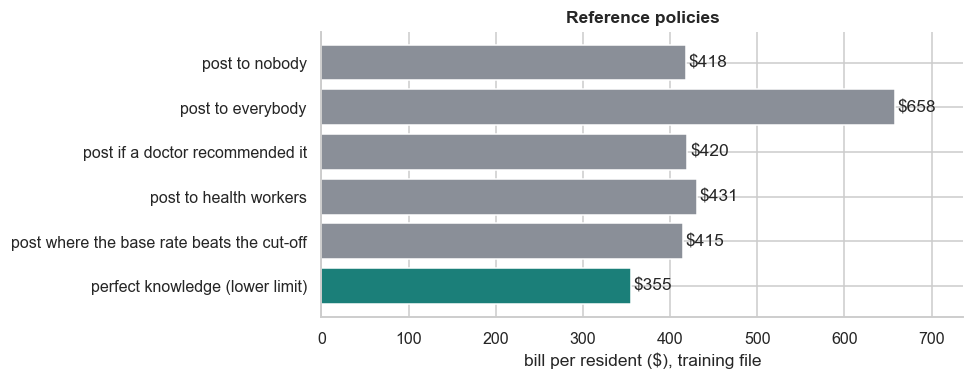

room between 'post to nobody' and perfect knowledge: $63.43 per resident


In [ ]:
def simple_policies(wants, frame, r_u, r_v):
    """Bill per resident for rules that need no model."""
    doctor = (frame["doctor_recc_h1n1"] == 1).to_numpy()
    worker = (frame["health_worker"] == 1).to_numpy()
    return pd.Series({
        "post to nobody": town_bill(wants, np.zeros_like(wants), r_u, r_v),
        "post to everybody": town_bill(wants, np.ones_like(wants), r_u, r_v),
        "post if a doctor recommended it": town_bill(wants, doctor, r_u, r_v),
        "post to health workers": town_bill(wants, worker, r_u, r_v),
        "post where the base rate beats the cut-off": town_bill(wants, wants.mean() > personal_cutoff(r_u, r_v), r_u, r_v),
        "perfect knowledge (lower limit)": town_bill(wants, wants, r_u, r_v),
    })

reference = simple_policies(y, train, RU, RV)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(reference.index[::-1], reference.values[::-1],
        color=[TEAL if "perfect" in k else GREY for k in reference.index[::-1]])
for i, v in enumerate(reference.values[::-1]):
    ax.text(v + 3, i, f"${v:,.0f}", va="center")
ax.set_xlabel("bill per resident ($), training file"); ax.set_xlim(0, reference.max() * 1.12)
ax.set_title("Reference policies")
plt.tight_layout(); plt.show()
ROOM = reference["post to nobody"] - reference["perfect knowledge (lower limit)"]
print(f"room between 'post to nobody' and perfect knowledge: ${ROOM:.2f} per resident")

Posting to everybody is by far the most expensive choice, because six in ten doses would be wasted. Posting to nobody is a strong baseline: the town then pays the cash and the hospital bills and nothing else. The gap between "post to nobody" and perfect knowledge is all the money a model can possibly save, and it is small compared with the bill itself. A model earns its place by capturing part of that gap without wasting doses.

## Q4. How should the data be prepared?
### Q4.1 Extra features
Six features suggested by the exploration. They are computed inside the pipeline from one row at a time, so they cannot leak information between folds.

In [ ]:
ENGINEERED = ["n_precautions", "n_unanswered", "worry_gap", "belief_score", "doctor_and_effective", "health_job"]

def add_features(frame):
    """Add the six hand-made features. Uses only the row itself, so it is safe inside cross-validation."""
    d = frame.copy()
    d["n_precautions"] = d[BEHAVIOURS].sum(axis=1)                               # how many of 7 behaviours (Q2.7)
    d["n_unanswered"] = frame[RAW].isna().sum(axis=1)                             # skipped questions (Q2.2)
    d["worry_gap"] = d["opinion_h1n1_risk"] - d["opinion_h1n1_sick_from_vacc"]    # fear of flu minus fear of vaccine
    d["belief_score"] = d["opinion_h1n1_vacc_effective"] + d["opinion_h1n1_risk"] # overall belief in the vaccine
    d["doctor_and_effective"] = d["doctor_recc_h1n1"] * d["opinion_h1n1_vacc_effective"]   # interaction (Q2.5)
    d["health_job"] = ((d["health_worker"] == 1) | (d["employment_sector"] == "healthcare")).astype(float)
    return d

add_features(train[RAW]).loc[:, ENGINEERED].describe().T[["mean", "min", "max"]].round(2)

,mean,min,max
n_precautions,3.11,0.0,7.0
n_unanswered,1.47,0.0,15.0
worry_gap,0.10,-4.0,4.0
belief_score,6.48,2.0,10.0
doctor_and_effective,1.24,0.0,5.0
health_job,0.16,0.0,1.0


### Q4.2 Six recipes
| Recipe | Gaps in numbers | Gaps in text | Encoding | Extras |
|---|---|---|---|---|
| `fill` | median | most common answer | one-hot, scaled | none (the plain textbook recipe) |
| `flag` | median + "was missing" flag | own answer "no answer" | one-hot (rare answers grouped), scaled | none |
| `knn` | value of the 15 most similar residents + flag | own answer | as `flag` | none |
| `flag+feat` | as `flag` | as `flag` | as `flag` | six engineered features |
| `flag+feat+pca` | as `flag` | as `flag` | as `flag`, then PCA keeping 95% of the variance | six engineered features |
| `tree` | left missing (the model handles it) | left missing | ordered integer codes, no scaling | six engineered features |

The first five feed a logistic regression (which needs scaled, complete numbers). The `tree` recipe is for tree models, which can split on "missing" directly and do not need scaling.

In [ ]:
# natural order for the three text answers that are really scales; the rest are sorted alphabetically
ORDERED = {"age_group": AGE_GROUPS,
           "education": ["< 12 Years", "12 Years", "Some College", "College Graduate"],
           "income_poverty": ["Below Poverty", "<= $75,000, Above Poverty", "> $75,000"]}
CAT_LEVELS = [ORDERED.get(c, sorted(train[c].dropna().unique())) for c in CAT]

def recipe(kind):
    """Return the list of pipeline steps for one pre-processing recipe."""
    engineered = "feat" in kind or kind == "tree"
    numeric_cols = NUM + (ENGINEERED if engineered else [])
    onehot = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=25, sparse_output=False)

    if kind == "fill":
        numeric = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
        text = make_pipeline(SimpleImputer(strategy="most_frequent"),
                             OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    elif kind == "knn":
        numeric = make_pipeline(StandardScaler(), KNNImputer(n_neighbors=15, add_indicator=True))
        text = make_pipeline(SimpleImputer(strategy="constant", fill_value="no answer"), onehot)
    elif kind == "tree":
        numeric = "passthrough"                                             # gaps stay as NaN
        text = OrdinalEncoder(categories=CAT_LEVELS, handle_unknown="use_encoded_value",
                              unknown_value=-1, encoded_missing_value=np.nan)
    else:                                                                    # flag, flag+feat, flag+feat+pca
        numeric = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler())
        text = make_pipeline(SimpleImputer(strategy="constant", fill_value="no answer"), onehot)

    steps = [("features", FunctionTransformer(add_features))] if engineered else []
    steps.append(("encode", ColumnTransformer([("num", numeric, numeric_cols), ("text", text, CAT)],
                                              verbose_feature_names_out=False)))
    if kind.endswith("pca"):
        steps.append(("pca", PCA(n_components=0.95, random_state=SEED)))
    return steps

def build(kind, model):
    """A full pipeline: recipe + model. The last step is always called 'model'."""
    return Pipeline(recipe(kind) + [("model", model)])

for kind in ("fill", "flag", "knn", "flag+feat", "flag+feat+pca", "tree"):
    width = Pipeline(recipe(kind)).fit_transform(X, y).shape[1]
    print(f"{kind:14s} -> {width:3d} columns")

fill           ->  68 columns
flag           ->  90 columns


knn            ->  90 columns
flag+feat      ->  99 columns
flag+feat+pca  ->  42 columns
tree           ->  35 columns


### Q4.3 The shared test bench
Every recipe and every model in this notebook is judged the same way.

* **5-fold stratified cross-validation, repeated 4 times with different shuffles = 20 folds.** In each fold the pipeline is fitted on 80% of the residents and predicts `q` for the other 20%, which it has never seen. All pre-processing is inside the pipeline, so medians, encoders and PCA are learnt from the training part only.
* The predicted `q` is turned into post / don't post with each resident's personal cut-off, and the fold's bill per resident is computed with `town_bill`.
* 20 fold bills per candidate give a **mean** (how good) and a **standard deviation** (how much it moves by chance).
* The folds are identical for every candidate, so candidates can be compared fold by fold (Q6.2).
* Log loss, AUC and Brier score are reported alongside, but never used for ranking.

In [ ]:
N_SPLITS, N_REPEATS = 5, 4
splitter = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
FOLDS = [(i // N_SPLITS, tr, va) for i, (tr, va) in enumerate(splitter.split(X, y))]     # (repeat, train idx, test idx)

def _fit_predict(estimator, X_fit, y_fit, X_new, weights=None):
    """Fit on one training part and return P(takes the vaccine) for the held-out part."""
    if weights is None:
        estimator.fit(X_fit, y_fit)
    else:
        estimator.fit(X_fit, y_fit, model__sample_weight=weights)
    return estimator.predict_proba(X_new)[:, 1]

def out_of_fold(make, weights=None):
    """Probabilities for every resident from models that never saw them: one row per repeat."""
    preds = Parallel(n_jobs=N_JOBS)(
        delayed(_fit_predict)(make(), X.iloc[tr], y[tr], X.iloc[va], None if weights is None else weights[tr])
        for _, tr, va in FOLDS)
    Q = np.zeros((N_REPEATS, len(y)))
    for (rep, _, va), p in zip(FOLDS, preds):
        Q[rep, va] = p
    return Q

def fold_bills(sent, r_u=RU, r_v=RV):
    """Bill per resident in each of the 20 held-out folds, for a (repeats x residents) decision array."""
    return np.array([town_bill(y[va], sent[rep, va], r_u[va], r_v[va]) for rep, _, va in FOLDS])

def probability_quality(Q):
    """Standard probability metrics, averaged over the repeats (reported, not used for ranking)."""
    return {"log loss": np.mean([log_loss(y, np.clip(q, 1e-6, 1 - 1e-6)) for q in Q]),
            "AUC": np.mean([roc_auc_score(y, q) for q in Q]),
            "Brier": np.mean([brier_score_loss(y, q) for q in Q])}

def paired(bills_a, bills_b):
    """Compare two candidates on the same folds.

    Returns the mean difference (a - b), the Nadeau-Bengio corrected p-value (the ordinary t-test is
    too confident because cross-validation folds share training data) and how many folds a won.
    """
    d = np.asarray(bills_a) - np.asarray(bills_b)
    if np.allclose(d, 0):
        return 0.0, 1.0, 0
    k = len(d)
    t = d.mean() / np.sqrt((1 / k + 1 / (N_SPLITS - 1)) * d.var(ddof=1))
    return float(d.mean()), float(2 * stats.t.sf(abs(t), k - 1)), int((d < 0).sum())

print(f"{len(FOLDS)} folds; each trains on about {len(FOLDS[0][1]):,} residents and is tested on about {len(FOLDS[0][2]):,}")

20 folds; each trains on about 3,804 residents and is tested on about 952


### Q4.4 Which recipe is cheapest?
Same model (a ridge-type logistic regression), same folds, only the recipe changes. The `tree` recipe is compared separately on a boosted-tree model against the one-hot alternative.

In [ ]:
def logit():
    return LogisticRegression(C=0.3, max_iter=3000)

def boosted():
    return XGBClassifier(n_estimators=250, learning_rate=0.05, max_depth=3, subsample=0.8,
                         colsample_bytree=0.8, n_jobs=1, random_state=SEED, verbosity=0)

trials = {("logistic", k): (lambda k=k: build(k, logit())) for k in ("fill", "flag", "knn", "flag+feat", "flag+feat+pca")}
trials[("boosted trees", "flag+feat")] = lambda: build("flag+feat", boosted())
trials[("boosted trees", "tree")] = lambda: build("tree", boosted())

t0 = time.time()
recipe_Q = {key: out_of_fold(make) for key, make in trials.items()}
recipe_bills = {key: fold_bills(Q > CUT) for key, Q in recipe_Q.items()}

rows = []
for (model, kind), bills in recipe_bills.items():
    baseline = recipe_bills[(model, "fill" if model == "logistic" else "flag+feat")]
    diff, p, wins = paired(bills, baseline)
    rows.append({"model": model, "recipe": kind, "bill $/resident": bills.mean(), "std": bills.std(),
                 "vs first recipe $": diff, "folds cheaper (of 20)": wins, "p (corrected)": p,
                 **probability_quality(recipe_Q[(model, kind)])})
recipe_table = pd.DataFrame(rows).set_index(["model", "recipe"])
print(f"done in {time.time() - t0:.0f}s")
recipe_table.round(4)

done in 6s


bill $/resident     std  vs first recipe $  \
model         recipe                                                      
logistic      fill                  397.8063  5.2590             0.0000   
              flag                  394.3979  6.3407            -3.4084   
              knn                   394.3489  6.2039            -3.4574   
              flag+feat             394.0822  6.2512            -3.7241   
              flag+feat+pca         394.5268  6.6513            -3.2795   
boosted trees flag+feat             392.9416  5.9852             0.0000   
              tree                  393.3604  6.3564             0.4189   

                             folds cheaper (of 20)  p (corrected)  log loss  \
model         recipe                                                          
logistic      fill                               0         1.0000    0.4989   
              flag                              18         0.0112    0.4655   
              knn                               19         0.0085    0.4636   
              flag+feat                         18         0.0057    0.4656   
              flag+feat+pca                     17         0.0387    0.4706   
boosted trees flag+feat                          0         1.0000    0.4563   
              tree                               6         0.5358    0.4556   

                                AUC   Brier  
model         recipe                         
logistic      fill           0.8230  0.1628  
              flag           0.8491  0.1503  
              knn            0.8505  0.1498  
              flag+feat      0.8493  0.1502  
              flag+feat+pca  0.8447  0.1520  
boosted trees flag+feat      0.8540  0.1470  
              tree           0.8546  0.1467

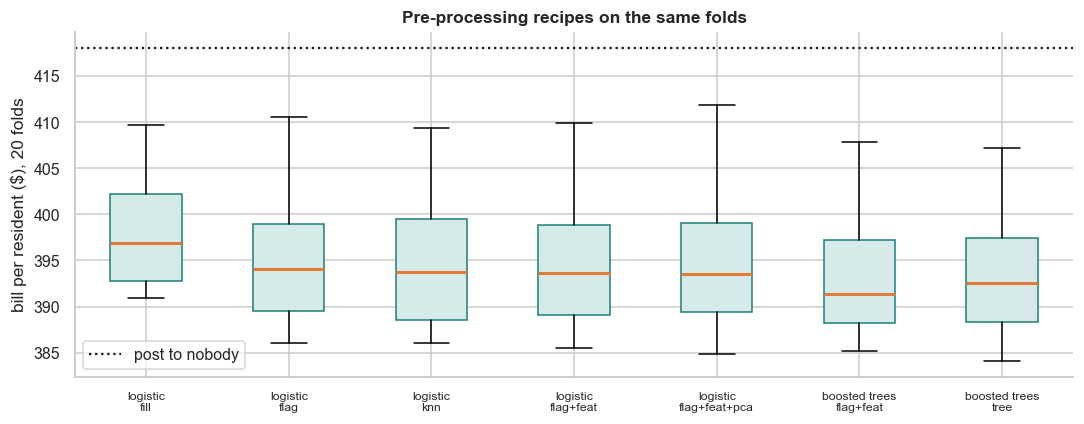

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
labels = [f"{m}\n{k}" for m, k in recipe_bills]
ax.boxplot(list(recipe_bills.values()), labels=labels, patch_artist=True,
           boxprops=dict(facecolor="#d6ebe9", color=TEAL), medianprops=dict(color=ORANGE, lw=2))
ax.axhline(reference["post to nobody"], color="k", ls=":", label="post to nobody")
ax.set_ylabel("bill per resident ($), 20 folds"); ax.set_title("Pre-processing recipes on the same folds")
ax.tick_params(axis="x", labelsize=8); ax.legend()
plt.tight_layout(); plt.show()

**What the table says.**

* Hiding the gaps is the one clear mistake. The plain `fill` recipe costs about $397.8 per resident; keeping "not answered" as information (`flag`) brings it down by about $3.4, cheaper in 18 of the 20 folds (corrected p about 0.01). This confirms what Q2.2 suggested.
* How the gaps are filled matters much less than whether they are flagged. The slower `knn` recipe lands within a few cents of `flag`.
* The engineered features add a further small step (`flag+feat` is the cheapest logistic recipe, about $3.7 below `fill`), although the gain over `flag` alone is well inside the noise.
* PCA does not help: with 42 components instead of 99 columns the bill and the log loss are both slightly worse, as Q2.8 predicted. We do not use it, and we keep the original columns, which are also easier to explain.
* For boosted trees the two encodings are indistinguishable (a $0.4 gap, p about 0.5). We use the `tree` recipe for tree models because it is the simpler one: 35 columns, no imputation at all, and the model decides what a gap means.

**Decision:** `flag+feat` for the linear models and the neural network, `tree` for the tree models.

## Q5. Which model predicts acceptance best?
### Q5.1 Seven families, out of the box
Each family makes a different assumption about how the answers relate to uptake:

| Candidate | Idea | Recipe |
|---|---|---|
| Naive Bayes | every answer votes independently; the simplest probabilistic model | all answers one-hot |
| Logistic regression | weighted sum of the answers, straight-line effects | `flag+feat` |
| Elastic-net logistic | same, but can switch weak answers off completely | `flag+feat` |
| Random forest | many deep trees on random subsets, averaged | `tree` |
| XGBoost | shallow trees added one at a time, each fixing the previous errors | `tree` |
| CatBoost | boosting that handles text answers natively with ordered target statistics | text kept as text |
| Neural network | one hidden layer, can bend the straight-line effects | `flag+feat` |

All of them output a probability, which is what the cut-off rule needs.

In [ ]:
def as_categories(frame):
    """Naive Bayes input: every answer (including 'no answer') becomes a category label."""
    return frame.astype(object).where(frame.notna(), "no answer").astype(str)

def catboost_frame(frame):
    """CatBoost input: engineered features added, text gaps labelled, numeric gaps left for the model."""
    d = add_features(frame)
    d[CAT] = d[CAT].fillna("no answer")
    return d

class CatBoostModel(ClassifierMixin, BaseEstimator):
    """Thin scikit-learn wrapper around CatBoost.

    CatBoost 1.2 does not implement the estimator tags that scikit-learn 1.6+ asks for, so it fails
    inside a Pipeline. This wrapper only passes fit / predict_proba through.
    """
    def __init__(self, iterations=500, learning_rate=0.05, depth=6, l2_leaf_reg=3.0):
        self.iterations, self.learning_rate, self.depth, self.l2_leaf_reg = iterations, learning_rate, depth, l2_leaf_reg

    def fit(self, X, y, sample_weight=None):
        self.booster_ = CatBoostClassifier(iterations=self.iterations, learning_rate=self.learning_rate,
                                           depth=self.depth, l2_leaf_reg=self.l2_leaf_reg, cat_features=CAT,
                                           thread_count=1, random_seed=SEED, verbose=0, allow_writing_files=False)
        self.booster_.fit(X, y, sample_weight=sample_weight)
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        return self.booster_.predict_proba(X)

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] > 0.5).astype(int)

def make_naive_bayes(alpha=1.0):
    return Pipeline([("labels", FunctionTransformer(as_categories)),
                     ("onehot", OneHotEncoder(handle_unknown="ignore")),
                     ("model", BernoulliNB(alpha=alpha))])

def make_logistic(C=1.0):
    return build("flag+feat", LogisticRegression(C=C, max_iter=3000))

def make_elastic(C=0.1, l1_ratio=0.5):
    return build("flag+feat", LogisticRegression(penalty="elasticnet", solver="saga", C=C, l1_ratio=l1_ratio,
                                                 max_iter=5000, random_state=SEED))

def make_forest(**kw):
    params = dict(n_estimators=400, min_samples_leaf=1, max_features="sqrt", n_jobs=1, random_state=SEED)
    params.update(kw)
    return build("tree", RandomForestClassifier(**params))

def make_xgb(**kw):
    params = dict(n_estimators=300, learning_rate=0.1, max_depth=6, n_jobs=1, random_state=SEED, verbosity=0)
    params.update(kw)
    return build("tree", XGBClassifier(**params))

def make_catboost(**kw):
    return Pipeline([("features", FunctionTransformer(catboost_frame)), ("model", CatBoostModel(**kw))])

def make_network(**kw):
    params = dict(hidden_layer_sizes=(64,), alpha=1e-4, max_iter=500, early_stopping=True, random_state=SEED)
    params.update(kw)
    return build("flag+feat", MLPClassifier(**params))

# every candidate lives in SPECS: how to build it and how its output becomes a decision
SPECS, PROBS, BILLS = {}, {}, {}

def register(name, make=None, kind="probability", members=None):
    """Add a candidate, get its out-of-fold probabilities and its 20 fold bills."""
    SPECS[name] = {"make": make, "kind": kind, "members": members}
    if kind == "blend":                                   # average of members fitted on the same folds
        PROBS[name] = np.mean([PROBS[m] for m in members], axis=0)
    elif kind == "weighted":                              # trained with dollar weights (Q5.5)
        PROBS[name] = out_of_fold(make, weights=dollar_weights(y, RU, RV))
    else:
        PROBS[name] = out_of_fold(make)
    BILLS[name] = fold_bills(decisions(name, PROBS[name]))
    return BILLS[name]

def decisions(name, Q, cut=None):
    """Turn probabilities into post / don't post. Dollar-weighted models are cut at 0.5 by construction."""
    if SPECS[name]["kind"] == "weighted":
        return Q > 0.5
    return Q > (CUT if cut is None else cut)

def summary(names):
    """Bill, spread and probability quality for a list of candidates."""
    rows = []
    for n in names:
        b = BILLS[n]
        rows.append({"candidate": n, "bill $/resident": b.mean(), "std": b.std(), "best fold": b.min(),
                     "worst fold": b.max(), "posted %": 100 * decisions(n, PROBS[n]).mean(),
                     **(probability_quality(PROBS[n]) if SPECS[n]["kind"] != "weighted" else {})})
    return pd.DataFrame(rows).set_index("candidate")

t0 = time.time()
STARTERS = {"Naive Bayes": make_naive_bayes, "Logistic": make_logistic, "Elastic net": make_elastic,
            "Random forest": make_forest, "XGBoost": make_xgb, "CatBoost": make_catboost,
            "Neural network": make_network}
for name, make in STARTERS.items():
    register(name, make)
print(f"done in {time.time() - t0:.0f}s   |   post to nobody = ${reference['post to nobody']:.2f}, "
      f"perfect knowledge = ${reference['perfect knowledge (lower limit)']:.2f}")
summary(STARTERS).round(4)

done in 23s   |   post to nobody = $418.09, perfect knowledge = $354.66


,bill $/resident,std,best fold,worst fold,posted %,log loss,AUC,Brier
candidate,,,,,,,,
Naive Bayes,406.8773,6.0381,396.8806,419.2697,28.8635,0.6778,0.8272,0.1823
Logistic,394.2619,6.1648,385.2219,409.8322,16.6159,0.4673,0.8488,0.1506
Elastic net,393.8928,6.2237,384.9329,410.5826,15.6592,0.4644,0.8495,0.1501
Random forest,394.4192,5.6794,386.3819,407.6533,14.5080,0.4714,0.8445,0.1520
XGBoost,396.5820,5.5683,388.0637,409.5449,22.2298,0.5311,0.8364,0.1626
CatBoost,393.6759,5.9501,384.3599,407.3162,16.9733,0.4574,0.8535,0.1473
Neural network,395.4314,5.7962,387.0498,408.2702,16.5265,0.4708,0.8455,0.1520


Every family beats "post to nobody" ($418.09), but not equally:

* **CatBoost, the elastic net and plain logistic regression** are the cheapest out of the box (about $393.7 to $394.3) and they post to roughly 16% of residents.
* **XGBoost with default-style settings** has by far the worst log loss of the tree models (0.53) and posts to 22%: deep trees with a high learning rate memorise the training folds and become over-confident, so too many residents cross their cut-off and doses are wasted.
* **Naive Bayes** is worst for the same reason, more strongly: it treats correlated answers as independent votes, its probabilities pile up near 0 and 1 (log loss 0.68), and it posts to 29% of residents.

Already here the bill follows the *quality of the probabilities*, not the model's complexity. That is what the next three sections work on: tuning (Q5.2, Q5.3) and calibration (Q5.4).

### Q5.2 Tuning the settings
The searches optimise **log loss**, not the bill. The cut-off rule only works if `q` is a trustworthy probability, and log loss rewards exactly that; it is also much smoother than the bill, which jumps whenever one resident crosses a cut-off. The tuned model is then scored in dollars on the 20 folds like everything else. Searches use their own 5-fold split of the training data.

#### Logistic regression: how much regularisation, and which kind?
`C` is the inverse strength of the penalty; `l1_ratio = 0` is ridge (shrinks all weights), `1` is lasso (sets weak weights to zero).

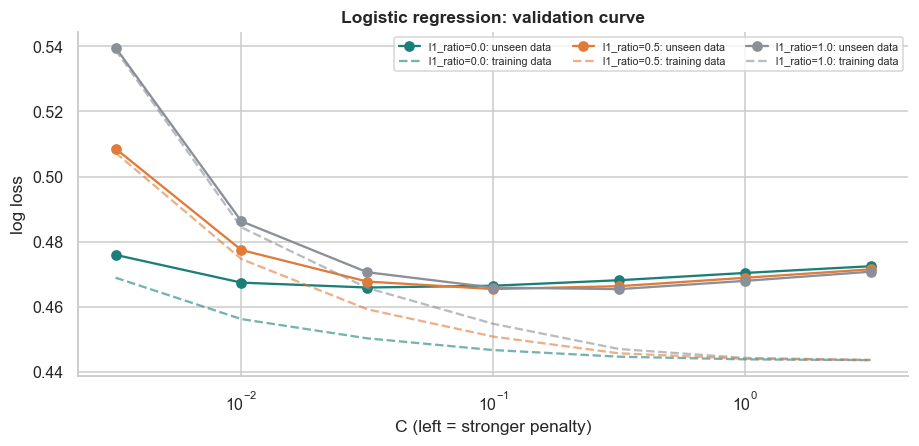

best: {'C': np.float64(0.31622776601683794), 'l1_ratio': 1.0}, log loss 0.4655  (28s)


In [ ]:
inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + 1)     # used by every search below

t0 = time.time()
grid_logit = GridSearchCV(make_elastic(), {"model__C": np.logspace(-2.5, 0.5, 7), "model__l1_ratio": [0.0, 0.5, 1.0]},
                          scoring="neg_log_loss", cv=inner, n_jobs=N_JOBS, return_train_score=True).fit(X, y)
res = pd.DataFrame(grid_logit.cv_results_)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
for ratio, colour in zip([0.0, 0.5, 1.0], [TEAL, ORANGE, GREY]):
    part = res[res["param_model__l1_ratio"] == ratio].sort_values("param_model__C")
    Cs = part["param_model__C"].astype(float)
    ax.plot(Cs, -part["mean_test_score"], "o-", color=colour, label=f"l1_ratio={ratio}: unseen data")
    ax.plot(Cs, -part["mean_train_score"], "--", color=colour, alpha=0.6, label=f"l1_ratio={ratio}: training data")
ax.set_xscale("log"); ax.set_xlabel("C (left = stronger penalty)"); ax.set_ylabel("log loss")
ax.set_title("Logistic regression: validation curve"); ax.legend(fontsize=7, ncol=3)
plt.tight_layout(); plt.show()
BEST_LOGIT = {k.replace("model__", ""): v for k, v in grid_logit.best_params_.items()}
print(f"best: {BEST_LOGIT}, log loss {-grid_logit.best_score_:.4f}  ({time.time() - t0:.0f}s)")

The dashed lines (training data) keep improving as the penalty is relaxed, while the solid lines (unseen data) flatten and then turn upwards: that gap is over-fitting. The best setting sits where the unseen-data curve is lowest.

#### Tree models and the neural network: random search
Random search tries a fixed number of random combinations, which covers a wide space faster than a full grid.

In [ ]:
from scipy.stats import loguniform, randint, uniform

def random_search(make, space, n_iter):
    """Random search on log loss over the given space; returns the fitted search object."""
    return RandomizedSearchCV(make(), space, n_iter=n_iter, scoring="neg_log_loss", cv=inner, n_jobs=N_JOBS,
                              random_state=SEED, return_train_score=True).fit(X, y)

t0 = time.time()
search_xgb = random_search(make_xgb, {
    "model__n_estimators": randint(150, 700), "model__learning_rate": loguniform(0.01, 0.2),
    "model__max_depth": randint(2, 7), "model__min_child_weight": randint(1, 12),
    "model__subsample": uniform(0.6, 0.4), "model__colsample_bytree": uniform(0.4, 0.6),
    "model__reg_lambda": loguniform(0.1, 20), "model__gamma": uniform(0, 2)}, n_iter=50)
search_forest = random_search(make_forest, {
    "model__min_samples_leaf": randint(1, 25), "model__max_features": uniform(0.15, 0.5),
    "model__max_depth": [None, 8, 12, 16], "model__n_estimators": [400, 700]}, n_iter=20)
search_network = random_search(make_network, {
    "model__hidden_layer_sizes": [(16,), (32,), (64,), (32, 16)], "model__alpha": loguniform(1e-4, 3),
    "model__learning_rate_init": loguniform(5e-4, 1e-2)}, n_iter=20)
search_bayes = GridSearchCV(make_naive_bayes(), {"model__alpha": [0.1, 0.5, 1, 3, 10, 30]},
                            scoring="neg_log_loss", cv=inner, n_jobs=N_JOBS).fit(X, y)

strip = lambda d: {k.replace("model__", ""): (round(v, 4) if isinstance(v, float) else v) for k, v in d.items()}
BEST_XGB, BEST_FOREST = strip(search_xgb.best_params_), strip(search_forest.best_params_)
BEST_NETWORK, BEST_BAYES = strip(search_network.best_params_), strip(search_bayes.best_params_)
for label, best, s in (("XGBoost", BEST_XGB, search_xgb), ("Random forest", BEST_FOREST, search_forest),
                       ("Neural network", BEST_NETWORK, search_network), ("Naive Bayes", BEST_BAYES, search_bayes)):
    print(f"{label:15s} log loss {-s.best_score_:.4f}  {best}")
print(f"({time.time() - t0:.0f}s)")

XGBoost         log loss 0.4567  {'colsample_bytree': np.float64(0.4301), 'gamma': np.float64(1.901), 'learning_rate': np.float64(0.0199), 'max_depth': 4, 'min_child_weight': 1, 'n_estimators': 447, 'reg_lambda': np.float64(8.4673), 'subsample': np.float64(0.7088)}
Random forest   log loss 0.4643  {'max_depth': 16, 'max_features': np.float64(0.2074), 'min_samples_leaf': 8, 'n_estimators': 700}
Neural network  log loss 0.4627  {'alpha': np.float64(1.9068), 'hidden_layer_sizes': (32,), 'learning_rate_init': np.float64(0.0014)}
Naive Bayes     log loss 0.6377  {'alpha': 30}
(44s)


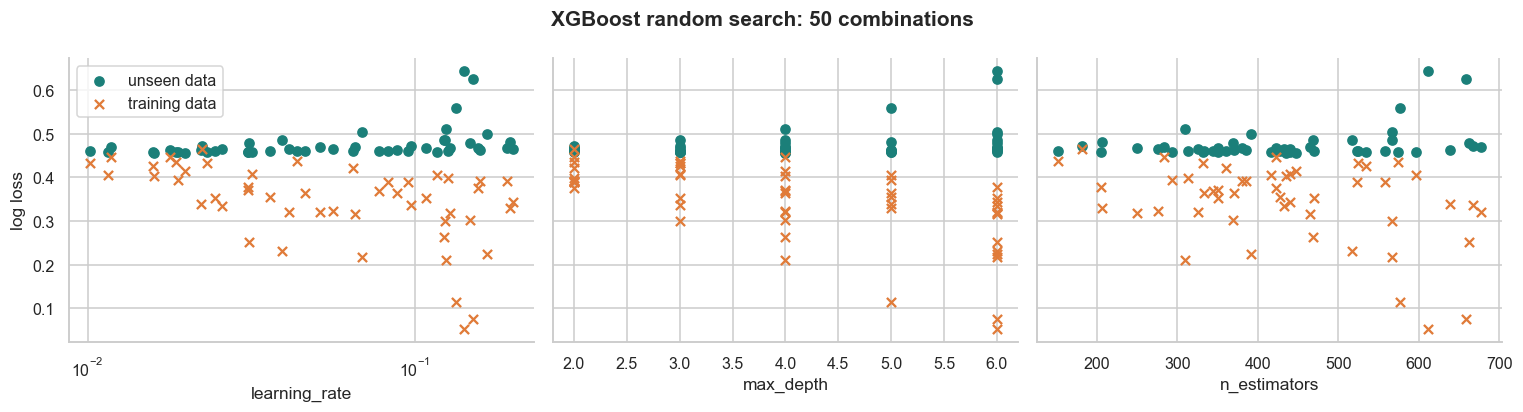

In [ ]:
# what the XGBoost search found: each dot is one tried combination
r = pd.DataFrame(search_xgb.cv_results_)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for a, (param, logx) in zip(ax, (("learning_rate", True), ("max_depth", False), ("n_estimators", False))):
    xv = r[f"param_model__{param}"].astype(float)
    a.scatter(xv, -r["mean_test_score"], color=TEAL, label="unseen data")
    a.scatter(xv, -r["mean_train_score"], color=ORANGE, marker="x", label="training data")
    if logx:
        a.set_xscale("log")
    a.set_xlabel(param)
ax[0].set_ylabel("log loss"); ax[0].legend()
fig.suptitle("XGBoost random search: 50 combinations", fontweight="bold")
plt.tight_layout(); plt.show()

Deep trees and high learning rates drive the training loss far down (orange crosses) while the loss on unseen data (teal dots) gets worse: with fewer than 5,000 residents, simple slow-learning trees generalise best.

CatBoost is slower to fit than the others, so instead of a random search it gets a small hand-picked grid, run with the same inner folds and the same score.

In [ ]:
def inner_log_loss(make):
    """Mean log loss over the inner folds for one configuration (same folds as the searches above)."""
    parts = Parallel(n_jobs=N_JOBS)(delayed(_fit_predict)(make(), X.iloc[tr], y[tr], X.iloc[va])
                                    for tr, va in inner.split(X, y))
    return float(np.mean([log_loss(y[va], np.clip(p, 1e-6, 1 - 1e-6))
                          for (tr, va), p in zip(inner.split(X, y), parts)]))

t0 = time.time()
cat_grid = [dict(depth=d, learning_rate=lr, iterations=it, l2_leaf_reg=reg)
            for d, lr, it, reg in [(4, 0.03, 600, 3), (4, 0.03, 600, 10), (4, 0.06, 400, 3), (6, 0.03, 500, 3),
                                   (6, 0.03, 500, 10), (3, 0.05, 700, 3), (5, 0.02, 900, 6), (2, 0.08, 700, 3)]]
cat_scores = [inner_log_loss(lambda p=p: make_catboost(**p)) for p in cat_grid]
BEST_CAT = cat_grid[int(np.argmin(cat_scores))]
print(pd.DataFrame(cat_grid).assign(log_loss=np.round(cat_scores, 4)).sort_values("log_loss").to_string(index=False))
print(f"best: {BEST_CAT}  ({time.time() - t0:.0f}s)")

 depth  learning_rate  iterations  l2_leaf_reg  log_loss
     3           0.05         700            3    0.4536
     4           0.03         600            3    0.4541
     4           0.06         400            3    0.4542
     6           0.03         500            3    0.4545
     5           0.02         900            6    0.4547
     6           0.03         500           10    0.4553
     4           0.03         600           10    0.4561
     2           0.08         700            3    0.4567
best: {'depth': 3, 'learning_rate': 0.05, 'iterations': 700, 'l2_leaf_reg': 3}  (37s)


### Q5.3 Did tuning pay off, in dollars?
Each tuned model goes through the same 20 folds. A negative difference means tuning made the town's bill smaller.

In [ ]:
t0 = time.time()
TUNED = {"Naive Bayes (tuned)": lambda: make_naive_bayes(**BEST_BAYES),
         "Elastic net (tuned)": lambda: make_elastic(**BEST_LOGIT),
         "Random forest (tuned)": lambda: make_forest(**BEST_FOREST),
         "XGBoost (tuned)": lambda: make_xgb(**BEST_XGB),
         "CatBoost (tuned)": lambda: make_catboost(**BEST_CAT),
         "Neural network (tuned)": lambda: make_network(**BEST_NETWORK)}
for name, make in TUNED.items():
    register(name, make)

rows = []
for name in TUNED:
    before = name.replace(" (tuned)", "")
    diff, p, wins = paired(BILLS[name], BILLS[before])
    rows.append({"family": before, "bill before": BILLS[before].mean(), "bill after": BILLS[name].mean(),
                 "change $": diff, "folds cheaper (of 20)": wins, "p (corrected)": p,
                 "log loss before": probability_quality(PROBS[before])["log loss"],
                 "log loss after": probability_quality(PROBS[name])["log loss"]})
tuning_table = pd.DataFrame(rows).set_index("family")
print(f"done in {time.time() - t0:.0f}s")
tuning_table.round(4)

done in 30s


,bill before,bill after,change $,folds cheaper (of 20),p (corrected),log loss before,log loss after
family,,,,,,,
Naive Bayes,406.8773,404.7006,-2.1767,19,0.0166,0.6778,0.6395
Elastic net,393.8928,393.9969,0.1041,8,0.8114,0.4644,0.4637
Random forest,394.4192,394.6616,0.2425,10,0.7356,0.4714,0.4635
XGBoost,396.5820,393.5529,-3.0291,19,0.0178,0.5311,0.4556
CatBoost,393.6759,393.5982,-0.0778,9,0.9245,0.4574,0.4558
Neural network,395.4314,394.6886,-0.7428,13,0.4191,0.4708,0.4675


Tuning paid off where the starting settings were over-fitting, and nowhere else:

* **XGBoost** improves by about $3.0 per resident, cheaper in 19 of 20 folds (corrected p about 0.02). The search moved it to shallow trees (depth 4), a learning rate of 0.02 and strong regularisation, and the log loss fell from 0.53 to 0.456.
* **Naive Bayes** improves by about $2.2 with much stronger smoothing, but stays far behind.
* **Elastic net, random forest and CatBoost** do not change in any meaningful way (all within about $0.25, p above 0.7). Their starting settings were already close to the best ones. The random forest is a useful warning: its log loss improved (0.471 to 0.464) and its bill did not.
* **Neural network**: about $0.7 cheaper, not significant.

So tuning is worth doing and worth checking in dollars: a better log loss does not automatically buy a smaller bill.

*A note on honesty:* the settings were chosen on the same training file that the 20 folds are drawn from, so the tuned bills are very slightly optimistic. The searches used log loss and different fold splits, which keeps that effect small, and it applies to every tuned family alike.

### Q5.4 Can the probabilities be trusted where it matters?
Most residents are only posted a vaccine if `q` is above roughly 0.8, so what matters is whether a predicted 0.85 really means 85%. The reliability plot compares predicted and observed uptake in ten equal-sized groups; the table gives the average gap (expected calibration error) overall and for the confident predictions only.

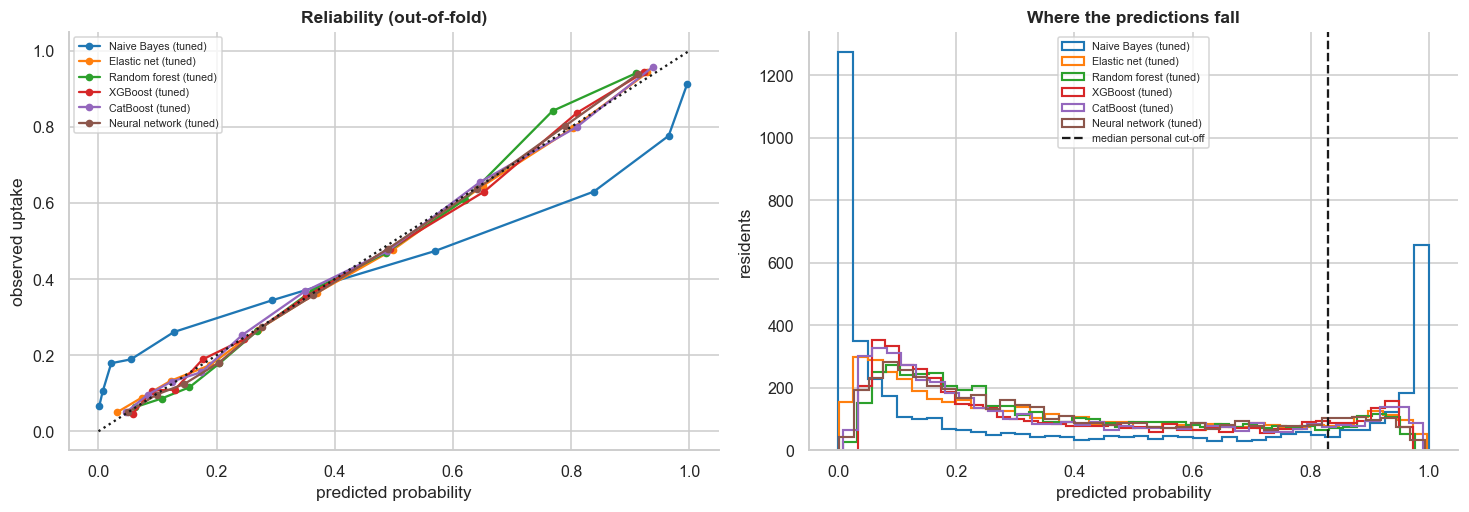

,calibration error,over-confidence above 0.7,share of predictions above 0.7
Naive Bayes (tuned),0.1215,0.1607,0.3078
Elastic net (tuned),0.0127,-0.0061,0.2196
Random forest (tuned),0.0211,-0.0473,0.1952
XGBoost (tuned),0.0154,-0.0227,0.2207
CatBoost (tuned),0.0114,-0.0125,0.2145
Neural network (tuned),0.0144,-0.0229,0.2034


In [ ]:
def calibration_error(q, truth=y, bins=10):
    """Average |observed - predicted| over equal-sized groups of predictions."""
    edges = np.quantile(q, np.linspace(0, 1, bins + 1))
    which = np.clip(np.searchsorted(edges, q, side="right") - 1, 0, bins - 1)
    return float(sum(abs(truth[which == b].mean() - q[which == b].mean()) * (which == b).mean()
                     for b in range(bins) if (which == b).any()))

def top_end_gap(q, truth=y, above=0.7):
    """Predicted minus observed uptake among confident predictions (positive = over-confident)."""
    m = q > above
    return float(q[m].mean() - truth[m].mean()) if m.sum() > 30 else np.nan

check = ["Naive Bayes (tuned)", "Elastic net (tuned)", "Random forest (tuned)", "XGBoost (tuned)",
         "CatBoost (tuned)", "Neural network (tuned)"]
fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.8))
for name, colour in zip(check, sns.color_palette("tab10", len(check))):
    q = PROBS[name][0]                                    # first repeat: one honest prediction per resident
    obs, pred = calibration_curve(y, q, n_bins=10, strategy="quantile")
    ax[0].plot(pred, obs, "o-", color=colour, label=name, ms=4)
    ax[1].hist(q, bins=40, histtype="step", color=colour, lw=1.4, label=name)
ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set_xlabel("predicted probability"); ax[0].set_ylabel("observed uptake")
ax[0].set_title("Reliability (out-of-fold)"); ax[0].legend(fontsize=7)
ax[1].axvline(np.median(CUT), color="k", ls="--", label="median personal cut-off")
ax[1].set_xlabel("predicted probability"); ax[1].set_ylabel("residents"); ax[1].set_title("Where the predictions fall")
ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

pd.DataFrame({n: {"calibration error": np.mean([calibration_error(q) for q in PROBS[n]]),
                  "over-confidence above 0.7": np.nanmean([top_end_gap(q) for q in PROBS[n]]),
                  "share of predictions above 0.7": np.mean(PROBS[n] > 0.7)} for n in check}).T.round(4)

Five of the six tuned models sit close to the diagonal (average gap between 0.01 and 0.02). Two details matter for the bill:

* **Naive Bayes** is badly over-confident: among its predictions above 0.7, the real uptake is about 16 points lower than it claims, and almost a third of its predictions are above 0.7. That is exactly the region where vaccines get posted.
* **The random forest errs the other way**: its confident predictions are about 5 points *too low*, so some residents who should cross their cut-off do not. It posts to fewer residents than any other model (13.9%).

The right-hand plot shows why the top end matters: the median personal cut-off is about 0.83, so most decisions are made in the right tail of these curves, where only about a fifth of the predictions fall.

To test whether repairing the probabilities saves money, two models are wrapped in a calibrator. Inside each training fold the calibrator is itself fitted by 5-fold cross-validation, so it never sees the residents it is scored on. Sigmoid (Platt) scaling fits a smooth S-curve; isotonic fits a free step function and needs more data.

In [ ]:
t0 = time.time()
def calibrated(make, method):
    """Wrap a pipeline so that its probabilities are re-mapped by a calibrator learnt on held-out folds."""
    return lambda: Pipeline([("model", CalibratedClassifierCV(make(), method=method, cv=5))])

register("Naive Bayes (tuned) + isotonic", calibrated(TUNED["Naive Bayes (tuned)"], "isotonic"))
register("Random forest (tuned) + sigmoid", calibrated(TUNED["Random forest (tuned)"], "sigmoid"))
register("XGBoost (tuned) + isotonic", calibrated(TUNED["XGBoost (tuned)"], "isotonic"))
CALIBRATED = ["Naive Bayes (tuned) + isotonic", "Random forest (tuned) + sigmoid", "XGBoost (tuned) + isotonic"]
rows = []
for name in CALIBRATED:
    before = name.split(" + ")[0]
    diff, p, wins = paired(BILLS[name], BILLS[before])
    rows.append({"candidate": name, "bill before": BILLS[before].mean(), "bill after": BILLS[name].mean(),
                 "change $": diff, "folds cheaper (of 20)": wins, "p (corrected)": p,
                 "calibration error before": np.mean([calibration_error(q) for q in PROBS[before]]),
                 "calibration error after": np.mean([calibration_error(q) for q in PROBS[name]])})
print(f"done in {time.time() - t0:.0f}s")
pd.DataFrame(rows).set_index("candidate").round(4)

done in 41s


,bill before,bill after,change $,folds cheaper (of 20),p (corrected),calibration error before,calibration error after
candidate,,,,,,,
Naive Bayes (tuned) + isotonic,404.7006,397.6652,-7.0353,20,0.0001,0.1215,0.0142
Random forest (tuned) + sigmoid,394.6616,394.4766,-0.1850,13,0.8031,0.0211,0.0269
XGBoost (tuned) + isotonic,393.5529,393.2282,-0.3248,13,0.6629,0.0154,0.0103


* **Naive Bayes** gains about $7.0 per resident from isotonic calibration, cheaper in all 20 folds. Its calibration error drops from 0.12 to 0.014. The ranking of residents is unchanged (same AUC), only the probabilities were repaired, and that alone is worth more than any tuning step in this notebook.
* **XGBoost** gains about $0.3 (13 of 20 folds, not significant). It was already well calibrated; isotonic reduces its error from 0.015 to 0.010.
* **Random forest** with sigmoid scaling: about $0.2 cheaper, not significant, and its measured calibration error does not improve. A single S-curve cannot fix a model that is only off in the upper tail.

Calibration is essential for a model with poor probabilities and a small, uncertain polish for a model that already has good ones.

### Q5.5 Teaching the model about money directly
So far the model learns "who accepts" and the money enters only afterwards, through the cut-off. An alternative is to tell the model during training how much each mistake costs:

* a resident who **refuses** costs $500 if we wrongly post, so they get weight 500;
* a resident who **accepts** costs their own hospital saving `(r_u - r_v) x 25,000` if we wrongly skip them, so they get that weight.

A model trained with these weights and cut at 0.5 makes, in theory, the same decisions as the personal cut-off applied to an ordinary model. In practice it spends its effort on the residents where the money is, which can help or hurt. We try it on the two strongest tuned families.

In [ ]:
def dollar_weights(wants, r_u, r_v):
    """Training weight of each resident = dollars lost if we get this resident wrong (mean scaled to 1)."""
    w = np.where(np.asarray(wants) == 1, (r_u - r_v) * HOSPITAL_COST, VACCINE_COST)
    return w / w.mean()

t0 = time.time()
register("XGBoost (tuned, dollar-weighted)", TUNED["XGBoost (tuned)"], kind="weighted")
register("Elastic net (tuned, dollar-weighted)", TUNED["Elastic net (tuned)"], kind="weighted")
WEIGHTED = ["XGBoost (tuned, dollar-weighted)", "Elastic net (tuned, dollar-weighted)"]
rows = []
for name in WEIGHTED:
    before = name.replace(", dollar-weighted", "")
    diff, p, wins = paired(BILLS[name], BILLS[before])
    rows.append({"candidate": name, "bill (cut-off rule)": BILLS[before].mean(), "bill (dollar-weighted)": BILLS[name].mean(),
                 "change $": diff, "folds cheaper (of 20)": wins, "p (corrected)": p,
                 "posted % (cut-off rule)": 100 * decisions(before, PROBS[before]).mean(),
                 "posted % (dollar-weighted)": 100 * decisions(name, PROBS[name]).mean()})
print(f"done in {time.time() - t0:.0f}s")
pd.DataFrame(rows).set_index("candidate").round(4)

done in 16s


,bill (cut-off rule),bill (dollar-weighted),change $,folds cheaper (of 20),p (corrected),posted % (cut-off rule),posted % (dollar-weighted)
candidate,,,,,,,
"XGBoost (tuned, dollar-weighted)",393.5529,393.5367,-0.0163,9,0.9789,15.7643,16.3005
"Elastic net (tuned, dollar-weighted)",393.9969,393.5407,-0.4562,11,0.6207,16.0114,16.4319


The dollar-weighted models end up within a few cents of their ordinary versions (XGBoost about $0.02 cheaper, elastic net about $0.46 cheaper, neither close to significant), and they post to a slightly larger share of residents. This agrees with the theory in Q3.2: both routes aim at the same decision. It is a useful cross-check that the personal cut-off is derived correctly, because a completely different way of using the costs gives the same bill.

One practical difference: a dollar-weighted model has the risk assumptions baked in at training time, so if the assumptions change it must be retrained, while an ordinary model only needs new cut-offs. Q6.6 shows what that means.

### Q5.6 Blending
Different families make different mistakes, so averaging their probabilities usually gives a steadier `q`. The members were fixed **before** looking at any blend score, one from each kind of model, and the average is unweighted, so nothing is tuned on the folds the blend is scored on.

* **Blend of three:** elastic net + XGBoost + CatBoost (one linear model, two different boosting methods).
* **Blend of five:** the same three + random forest + neural network.

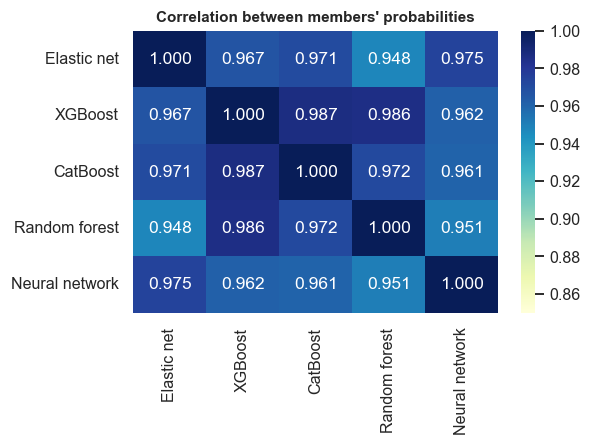

,bill $/resident,std,best fold,worst fold,posted %,log loss,AUC,Brier
candidate,,,,,,,,
Blend of three,393.4779,5.8909,383.2794,407.4725,15.5330,0.4540,0.8561,0.1463
Blend of five,393.2605,5.8128,383.4554,406.9192,14.9495,0.4548,0.8563,0.1466
Elastic net (tuned),393.9969,6.2033,384.6749,410.8111,16.0114,0.4637,0.8502,0.1498
XGBoost (tuned),393.5529,6.0208,384.9860,407.7214,15.7643,0.4556,0.8548,0.1468
CatBoost (tuned),393.5982,6.1686,383.1620,407.9691,16.0061,0.4558,0.8544,0.1470
Random forest (tuned),394.6616,5.7782,386.2431,407.9127,13.8720,0.4635,0.8512,0.1493
Neural network (tuned),394.6886,6.4102,385.7275,409.1041,14.7288,0.4675,0.8469,0.1517


In [ ]:
register("Blend of three", kind="blend", members=["Elastic net (tuned)", "XGBoost (tuned)", "CatBoost (tuned)"])
register("Blend of five", kind="blend", members=["Elastic net (tuned)", "XGBoost (tuned)", "CatBoost (tuned)",
                                                 "Random forest (tuned)", "Neural network (tuned)"])
BLENDS = ["Blend of three", "Blend of five"]

# how different are the members? correlation of their out-of-fold probabilities (first repeat)
members = SPECS["Blend of five"]["members"]
agreement = pd.DataFrame({m.replace(" (tuned)", ""): PROBS[m][0] for m in members}).corr()
fig, ax = plt.subplots(figsize=(5.6, 4.2))
sns.heatmap(agreement, annot=True, fmt=".3f", cmap="YlGnBu", vmin=0.85, vmax=1, ax=ax)
ax.set_title("Correlation between members' probabilities", fontsize=10)
plt.tight_layout(); plt.show()
summary(BLENDS + members).round(4)

The members' probabilities are very highly correlated (0.95 to 0.99), so there is limited room for a blend to add anything. Even so, both blends have a lower log loss than any single member (0.454 to 0.455 against 0.456 at best), a slightly lower bill than their best member, and the smallest fold-to-fold spread among the leading candidates. The gain is a few tens of cents per resident, which is small, but it comes without any tuning and makes the result less dependent on one model's quirks.

## Q6. How far can we trust the comparison?
### Q6.1 League table
All candidates, ordered by mean bill over the same 20 unseen folds. `saved vs nobody` is the money saved per resident compared with posting to nobody, and `share of possible saving` relates that to the saving a perfect model would achieve.

In [ ]:
league = summary(list(SPECS)).sort_values("bill $/resident")
nobody_folds = fold_bills(np.zeros((N_REPEATS, len(y)), bool))
perfect_folds = fold_bills(np.tile(y.astype(bool), (N_REPEATS, 1)))
league.insert(2, "saved vs nobody $", nobody_folds.mean() - league["bill $/resident"])
league.insert(3, "share of possible saving %", 100 * league["saved vs nobody $"] / (nobody_folds.mean() - perfect_folds.mean()))
LEADER = league.index[0]
print(f"post to nobody: ${nobody_folds.mean():.2f} +/- {nobody_folds.std():.2f}   |   perfect knowledge: ${perfect_folds.mean():.2f}")
league.round(3)

post to nobody: $418.09 +/- 4.53   |   perfect knowledge: $354.66


,bill $/resident,std,saved vs nobody $,share of possible saving %,best fold,worst fold,posted %,log loss,AUC,Brier
candidate,,,,,,,,,,
XGBoost (tuned) + isotonic,393.228,6.205,24.862,39.196,384.687,409.663,17.446,0.459,0.854,0.147
Blend of five,393.261,5.813,24.829,39.145,383.455,406.919,14.950,0.455,0.856,0.147
Blend of three,393.478,5.891,24.612,38.803,383.279,407.473,15.533,0.454,0.856,0.146
"XGBoost (tuned, dollar-weighted)",393.537,6.464,24.553,38.710,384.560,408.637,16.300,NaN,NaN,NaN
"Elastic net (tuned, dollar-weighted)",393.541,6.528,24.549,38.704,385.036,412.135,16.432,NaN,NaN,NaN
XGBoost (tuned),393.553,6.021,24.537,38.684,384.986,407.721,15.764,0.456,0.855,0.147
CatBoost (tuned),393.598,6.169,24.492,38.613,383.162,407.969,16.006,0.456,0.854,0.147
CatBoost,393.676,5.950,24.414,38.490,384.360,407.316,16.973,0.457,0.854,0.147
Elastic net,393.893,6.224,24.197,38.149,384.933,410.583,15.659,0.464,0.850,0.150


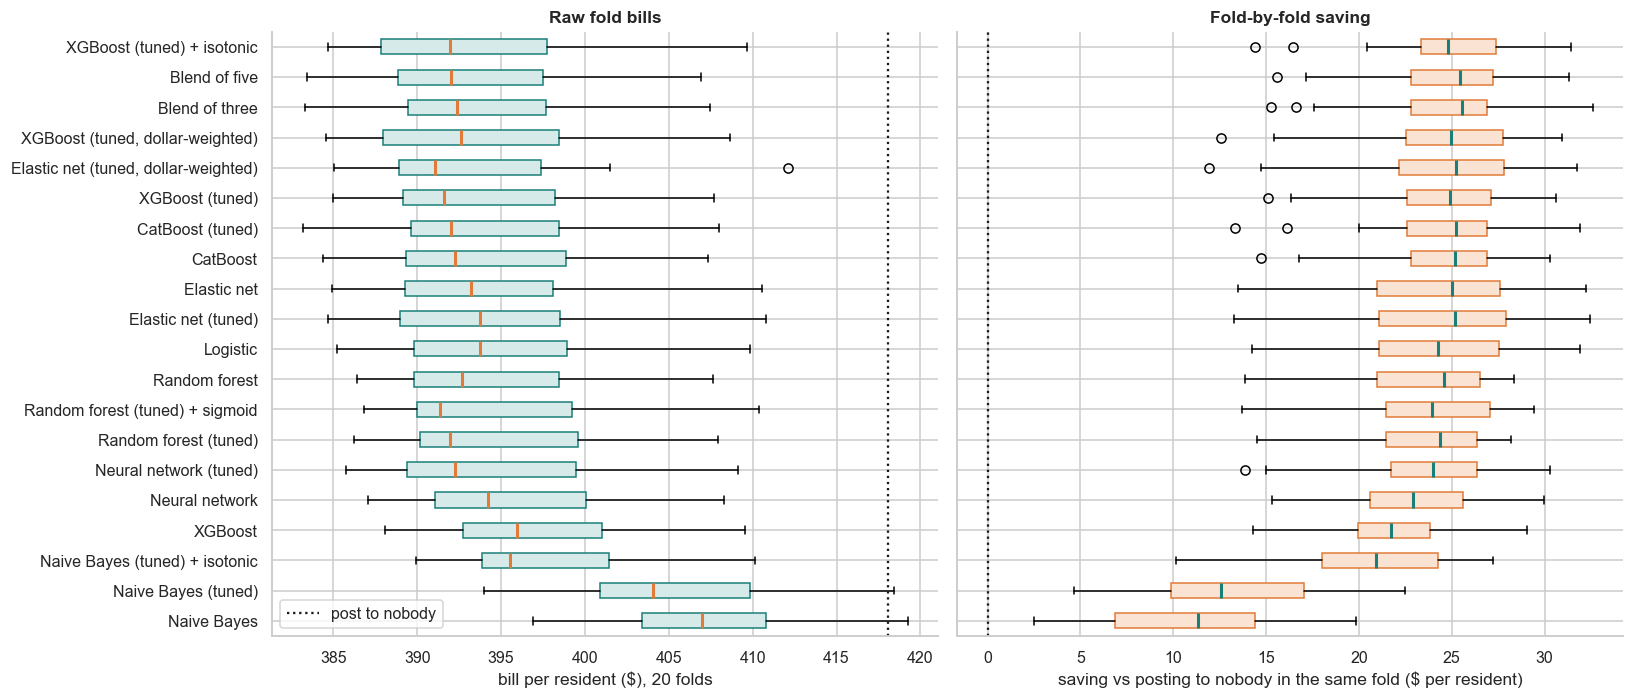

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6.5), sharey=True)
names = league.index.tolist()[::-1]
# left: raw fold bills. The spread is mostly "which residents landed in the fold".
ax[0].boxplot([BILLS[n] for n in names], vert=False, labels=names, patch_artist=True,
              boxprops=dict(facecolor="#d6ebe9", color=TEAL), medianprops=dict(color=ORANGE, lw=2))
ax[0].axvline(nobody_folds.mean(), color="k", ls=":", label="post to nobody")
ax[0].set_xlabel("bill per resident ($), 20 folds"); ax[0].set_title("Raw fold bills"); ax[0].legend()
# right: saving against "post to nobody" in the SAME fold, which removes the fold-to-fold noise
ax[1].boxplot([nobody_folds - BILLS[n] for n in names], vert=False, patch_artist=True,
              boxprops=dict(facecolor="#fbe3d3", color=ORANGE), medianprops=dict(color=TEAL, lw=2))
ax[1].axvline(0, color="k", ls=":")
ax[0].set_yticks(range(1, len(names) + 1)); ax[0].set_yticklabels(names)      # shared axis: restore the names
ax[1].set_xlabel("saving vs posting to nobody in the same fold ($ per resident)")
ax[1].set_title("Fold-by-fold saving")
plt.tight_layout(); plt.show()

* Posting to nobody costs $418.09 per resident; perfect knowledge would cost $354.66. The leading candidate, **XGBoost (tuned) + isotonic**, costs **$393.23**, a saving of about **$24.9 per resident**, or 39% of everything a perfect model could save. Over the 4,749 test residents that is roughly $118,000.
* The first eight candidates are within about $0.45 of each other. The gap from the leader to the default XGBoost is about $3.4 and to Naive Bayes about $13.6.
* The standard deviation of about $6 in the left panel looks large next to these gaps, but it is mostly not model noise: it is the luck of which residents fall in a fold (a fold with more elderly, sicker residents is expensive for every policy, including "post to nobody", whose own spread is $4.5). The right panel removes that by comparing each model with "post to nobody" **in the same fold**: every candidate saves money in every single fold.

Whether the small gaps between the leading candidates are real is the next question.

### Q6.2 Are the gaps between candidates real?
The fold bills move together (a fold with more elderly, sicker residents is expensive for every model), so comparing means and standard deviations side by side is misleading. Instead each candidate is compared with the leader **fold by fold**. The p-value uses the Nadeau-Bengio correction, because cross-validation folds share training data and the plain t-test would be too confident.

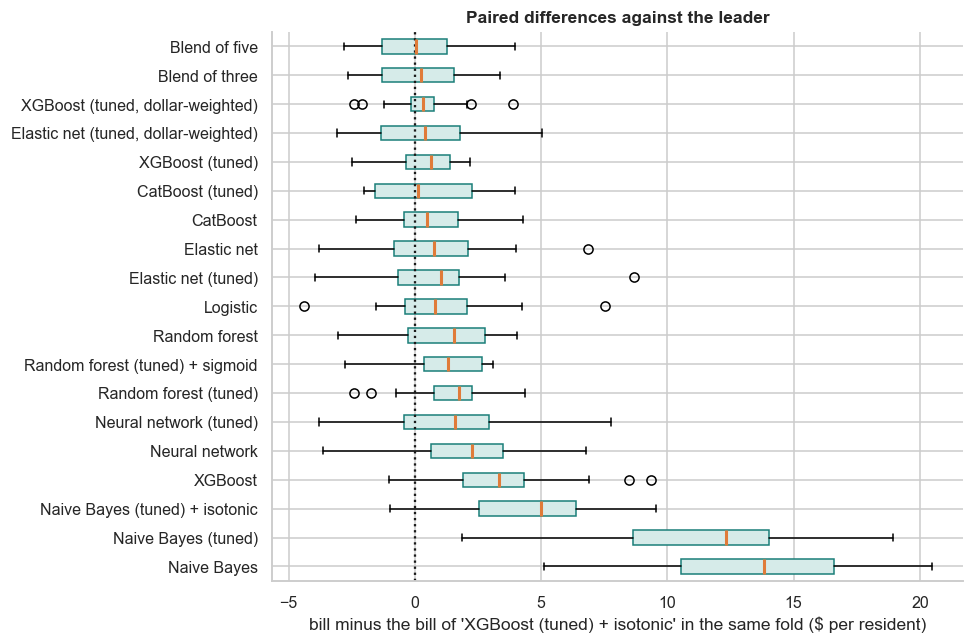

,costs more than the leader by $,folds where it beat the leader (of 20),p (corrected)
candidate,,,
Blend of five,0.0323,10,0.9748
Blend of three,0.2497,10,0.8039
"XGBoost (tuned, dollar-weighted)",0.3085,7,0.7022
"Elastic net (tuned, dollar-weighted)",0.3125,9,0.8066
XGBoost (tuned),0.3248,7,0.6629
CatBoost (tuned),0.3700,10,0.7444
CatBoost,0.4477,8,0.6081
Elastic net,0.6646,7,0.6482
Elastic net (tuned),0.7687,7,0.6176


In [ ]:
rows = []
for name in league.index[1:]:
    diff, p, wins = paired(BILLS[name], BILLS[LEADER])
    rows.append({"candidate": name, "costs more than the leader by $": diff,
                 "folds where it beat the leader (of 20)": wins, "p (corrected)": p})
versus = pd.DataFrame(rows).set_index("candidate")

fig, ax = plt.subplots(figsize=(9, 6))
d = [BILLS[n] - BILLS[LEADER] for n in versus.index[::-1]]
ax.boxplot(d, vert=False, labels=versus.index[::-1], patch_artist=True,
           boxprops=dict(facecolor="#d6ebe9", color=TEAL), medianprops=dict(color=ORANGE, lw=2))
ax.axvline(0, color="k", ls=":")
ax.set_xlabel(f"bill minus the bill of '{LEADER}' in the same fold ($ per resident)")
ax.set_title("Paired differences against the leader")
plt.tight_layout(); plt.show()
versus.round(4)

They are mostly not. Against the leader:

* the next seven candidates (both blends, both dollar-weighted models, tuned XGBoost and both CatBoost versions) cost between $0.03 and $0.45 more, each beats the leader in 7 to 10 of the 20 folds, and the corrected p-values are between 0.6 and 0.98. On this evidence they are **tied**;
* the differences only become convincing at the bottom of the table: default XGBoost (about $3.4 worse, p about 0.03) and the three Naive Bayes versions.

What this means for the submission: the choice of the leading *group* is well supported, the exact order *inside* that group is not. We still order the files by mean bill, because the brief asks for an order by the metric and the mean is the best single estimate we have, but we expect the hidden-test order of our five files to be partly a matter of chance, and we say so.

### Q6.3 Does the ranking by dollars agree with the usual metrics?
If log loss or AUC ranked the candidates the same way as the bill, the task-specific metric would not be needed. The plot puts each candidate's bill against its log loss and its AUC.

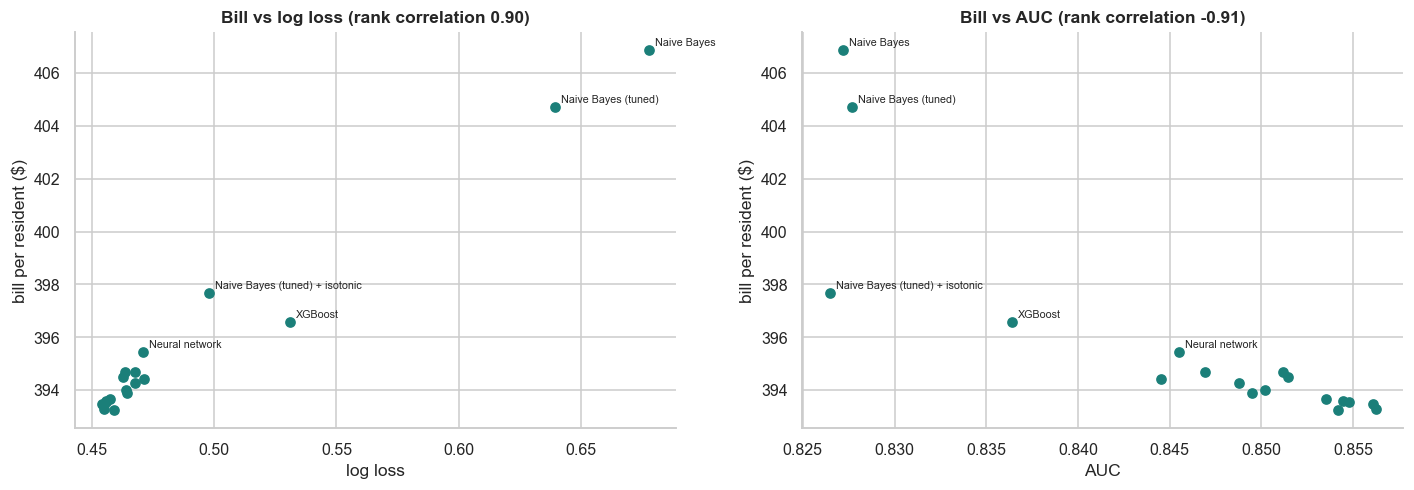

In [ ]:
plot_data = league.dropna(subset=["log loss"])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for a, metric in zip(ax, ("log loss", "AUC")):
    a.scatter(plot_data[metric], plot_data["bill $/resident"], color=TEAL)
    for name, row in plot_data.iterrows():
        if row["bill $/resident"] > plot_data["bill $/resident"].min() + 1.5:      # label only the points outside the tight leading group
            a.annotate(name, (row[metric], row["bill $/resident"]), fontsize=7, xytext=(4, 3), textcoords="offset points")
    rho = stats.spearmanr(plot_data[metric], plot_data["bill $/resident"])[0]
    a.set_xlabel(metric); a.set_ylabel("bill per resident ($)"); a.set_title(f"Bill vs {metric} (rank correlation {rho:.2f})")
plt.tight_layout(); plt.show()

Across all candidates the bill and the usual metrics broadly agree (rank correlation about 0.9 with log loss, about -0.9 with AUC): a model with poor probabilities is also expensive. But they are not interchangeable, and the exceptions are the instructive part:

* **AUC cannot see calibration.** Naive Bayes before and after isotonic calibration has the same AUC (0.83), yet the calibrated version is about $7 per resident cheaper. AUC only measures the ordering of residents, and the bill depends on the probability values themselves.
* **Accuracy points the wrong way.** Q6.4 and Q6.5 show that the usual 0.5 cut-off, which maximises accuracy-type scores, costs about $17 to $20 per resident more than the personal cut-off on the same probabilities.
* **Inside the leading group the order differs.** The blends have the best log loss and AUC, the calibrated XGBoost has the lowest bill.

Log loss is a sensible quantity to tune on (smooth, rewards honest probabilities), but the final judgement has to be made in dollars.

### Q6.4 Where does the leading candidate get it right and wrong?
The confusion matrix of the leader's out-of-fold decisions (all four repeats pooled), first as counts with the usual accuracy-type scores, then in dollars: what each cell costs compared with the best possible decision for those residents.

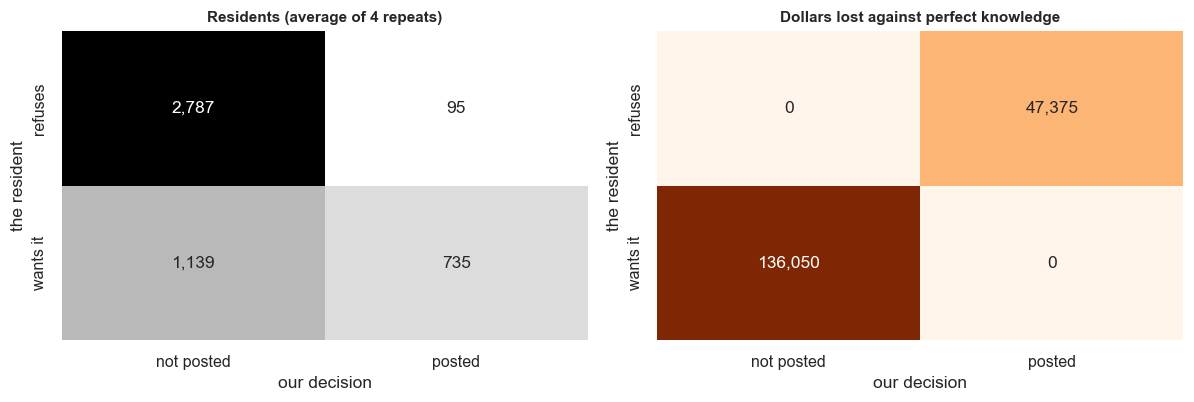

candidate: XGBoost (tuned) + isotonic
accuracy 0.741 | precision of posted doses 0.886 | share of takers reached 0.392 | F1 0.544
average loss per missed taker $119, per wasted dose $500


In [ ]:
sent = decisions(LEADER, PROBS[LEADER])                                   # (repeats x residents)
wants = np.tile(y, (N_REPEATS, 1))
counts = pd.DataFrame(confusion_matrix(wants.ravel(), sent.ravel()) / N_REPEATS,
                      index=["refuses", "wants it"], columns=["not posted", "posted"])

# money lost against perfect knowledge, per cell, averaged over the repeats
ru2, rv2 = np.tile(RU, (N_REPEATS, 1)), np.tile(RV, (N_REPEATS, 1))
wasted = VACCINE_COST * ((wants == 0) & sent)                              # dose posted to a refuser
missed = (ru2 - rv2) * HOSPITAL_COST * ((wants == 1) & ~sent)              # protection not given to a taker
loss = pd.DataFrame([[0, wasted.sum() / N_REPEATS], [missed.sum() / N_REPEATS, 0]],
                    index=counts.index, columns=counts.columns)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.heatmap(counts, annot=True, fmt=",.0f", cmap="Greys", cbar=False, ax=ax[0])
ax[0].set_title(f"Residents (average of {N_REPEATS} repeats)", fontsize=10)
sns.heatmap(loss, annot=True, fmt=",.0f", cmap="Oranges", cbar=False, ax=ax[1])
ax[1].set_title("Dollars lost against perfect knowledge", fontsize=10)
for a in ax:
    a.set_xlabel("our decision"); a.set_ylabel("the resident")
plt.tight_layout(); plt.show()

flat_w, flat_s = wants.ravel(), sent.ravel()
print(f"candidate: {LEADER}")
print(f"accuracy {accuracy_score(flat_w, flat_s):.3f} | precision of posted doses {flat_w[flat_s].mean():.3f} | "
      f"share of takers reached {flat_s[flat_w == 1].mean():.3f} | F1 {f1_score(flat_w, flat_s):.3f}")
print(f"average loss per missed taker ${missed.sum() / max(((wants == 1) & ~sent).sum(), 1):.0f}, "
      f"per wasted dose ${VACCINE_COST}")

The leader is deliberately "inaccurate". It posts a vaccine to only about 830 of the 4,756 residents and reaches just 39% of the people who want one, so its accuracy (0.74) and F1 (0.54) look modest. But 89% of the doses it posts are used.

The dollar matrix shows why this is the right behaviour. A wasted dose always costs $500. A missed taker costs on average only about $119, the hospital saving that was not realised (the $500 cash is paid either way). The model therefore accepts many cheap misses (about 1,140 residents, $136,000 in total) to avoid expensive wasted doses (about 95, $47,000). A model pushed towards higher recall would convert cheap errors into expensive ones.

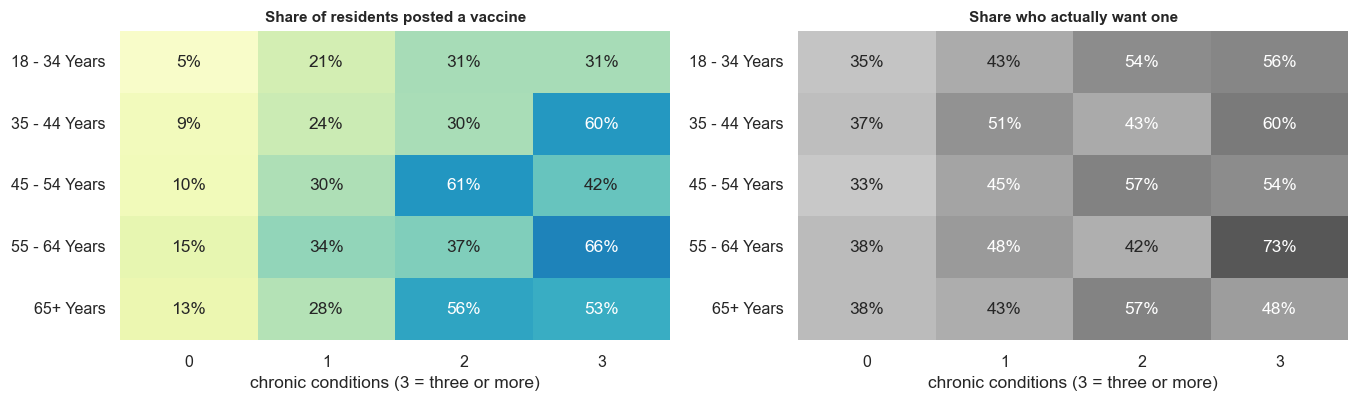

In [ ]:
# who gets a vaccine under the leader? share posted by age group and number of chronic conditions
posted_share = pd.DataFrame({"age_group": train["age_group"],
                             "chronic conditions": train["number_chronic_med_conditions"].clip(upper=3),
                             "posted": sent.mean(axis=0), "wants": y})
fig, ax = plt.subplots(1, 2, figsize=(12.5, 3.8))
sns.heatmap(posted_share.pivot_table(index="age_group", columns="chronic conditions", values="posted"),
            annot=True, fmt=".0%", cmap="YlGnBu", vmin=0, vmax=1, ax=ax[0], cbar=False)
ax[0].set_title("Share of residents posted a vaccine", fontsize=10)
sns.heatmap(posted_share.pivot_table(index="age_group", columns="chronic conditions", values="wants"),
            annot=True, fmt=".0%", cmap="Greys", vmin=0, vmax=1, ax=ax[1], cbar=False)
ax[1].set_title("Share who actually want one", fontsize=10)
for a in ax:
    a.set_xlabel("chronic conditions (3 = three or more)"); a.set_ylabel("")
plt.tight_layout(); plt.show()

The share of residents posted a vaccine rises steeply with the number of chronic conditions: 5 to 15% of residents with none, about 20 to 35% with one, and roughly 30 to 65% with two or more. The share who actually *want* a vaccine (right) rises far less, from about 35% to about 55%. So the policy is not simply "post to the people most likely to accept". It concentrates doses where an accepted dose prevents the most hospital cost, which is what the bill rewards. Young, healthy residents are almost never posted a vaccine, even though more than a third of them want one: for them the town pays the $500 in cash instead.

### Q6.5 How much is the personal cut-off worth?
The same out-of-fold probabilities are turned into decisions in three ways:

1. the usual **0.5** cut-off for everybody;
2. the **best single cut-off** for everybody, chosen on the other four folds and applied to the held-out fold (so it is not flattered);
3. the **personal cut-off** from Q3.2.

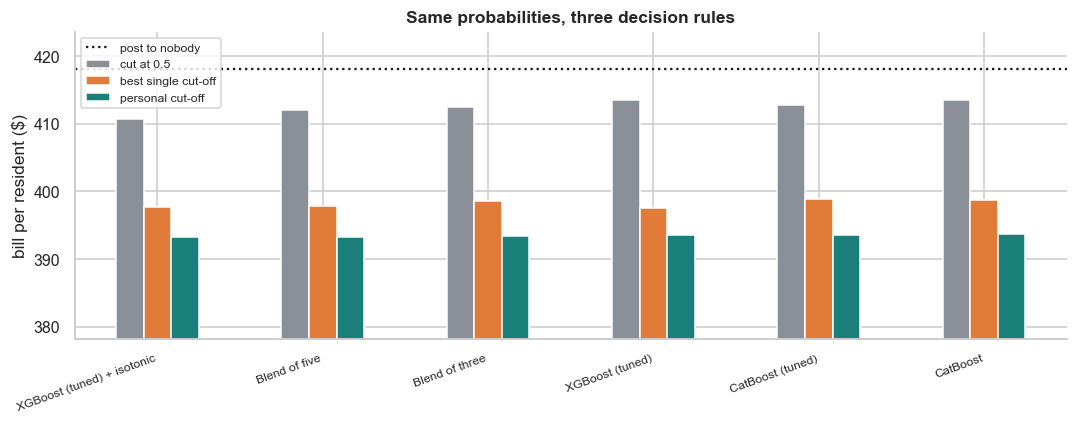

,cut at 0.5,best single cut-off,personal cut-off,personal vs 0.5 $,personal vs single $,folds personal beats single
candidate,,,,,,
XGBoost (tuned) + isotonic,410.746,397.676,393.228,-17.518,-4.448,19
Blend of five,412.094,397.799,393.261,-18.833,-4.538,18
Blend of three,412.455,398.521,393.478,-18.977,-5.043,19
XGBoost (tuned),413.545,397.606,393.553,-19.992,-4.053,18
CatBoost (tuned),412.728,398.900,393.598,-19.130,-5.302,20
CatBoost,413.584,398.685,393.676,-19.909,-5.009,20


In [ ]:
def best_single_cutoff_bills(Q):
    """One cut-off for everybody, picked on the other folds of the same repeat, scored on the held-out fold."""
    candidates = np.linspace(0.3, 0.99, 70)
    out = []
    for rep, tr, va in FOLDS:
        costs = [town_bill(y[tr], Q[rep, tr] > c, RU[tr], RV[tr]) for c in candidates]
        c_best = candidates[int(np.argmin(costs))]
        out.append(town_bill(y[va], Q[rep, va] > c_best, RU[va], RV[va]))
    return np.array(out)

probability_models = [n for n in league.index if SPECS[n]["kind"] != "weighted"][:6]
rows = []
for name in probability_models:
    Q = PROBS[name]
    half, single, personal = fold_bills(Q > 0.5), best_single_cutoff_bills(Q), BILLS[name]
    rows.append({"candidate": name, "cut at 0.5": half.mean(), "best single cut-off": single.mean(),
                 "personal cut-off": personal.mean(), "personal vs 0.5 $": (personal - half).mean(),
                 "personal vs single $": (personal - single).mean(),
                 "folds personal beats single": int((personal < single).sum())})
rule_table = pd.DataFrame(rows).set_index("candidate")

fig, ax = plt.subplots(figsize=(10, 4))
rule_table[["cut at 0.5", "best single cut-off", "personal cut-off"]].plot(kind="bar", ax=ax, color=[GREY, ORANGE, TEAL])
ax.axhline(nobody_folds.mean(), color="k", ls=":", label="post to nobody")
ax.set_ylim(rule_table["personal cut-off"].min() - 15, rule_table["cut at 0.5"].max() + 10)
ax.set_ylabel("bill per resident ($)"); ax.set_xlabel(""); ax.legend(fontsize=8)
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right", fontsize=8)
ax.set_title("Same probabilities, three decision rules")
plt.tight_layout(); plt.show()
rule_table.round(3)

For every leading candidate the picture is the same:

* cutting at **0.5** costs about $411 to $414 per resident. That is only a little better than posting to nobody, because a cut-off of 0.5 posts to many residents for whom a wasted dose costs far more than a used one saves;
* the **best single cut-off** (chosen honestly on other folds) brings the bill to about $398 to $399;
* the **personal cut-off** brings it to about $393 to $394: a further $4 to $5 per resident, cheaper in 18 to 20 of the 20 folds.

So of the roughly $25 saved against posting to nobody, about $20 is reached by moving a single cut-off to where the costs say it should be, and the last $4 to $5 by making it personal (age and chronic conditions). The decision rule is worth far more than the choice between the leading models (a few tens of cents). This is the main finding of the project.

### Q6.6 Stress test: what if the AI risk numbers are wrong?
The hospital risks are estimates. Every candidate's stored out-of-fold probabilities are re-scored under 30 alternative sets of assumptions: the overall risk level at half, the same and double; the vaccine effect at 0.45, 0.65 and 0.85; the per-condition multiplier at 1.75, 2.33 and 3; plus each of the three AIs' own answers. Under each scenario the cut-offs are recomputed, so the decisions change too. (The two dollar-weighted models were trained under the base assumptions, so their decisions stay fixed and only their bill is re-priced.)

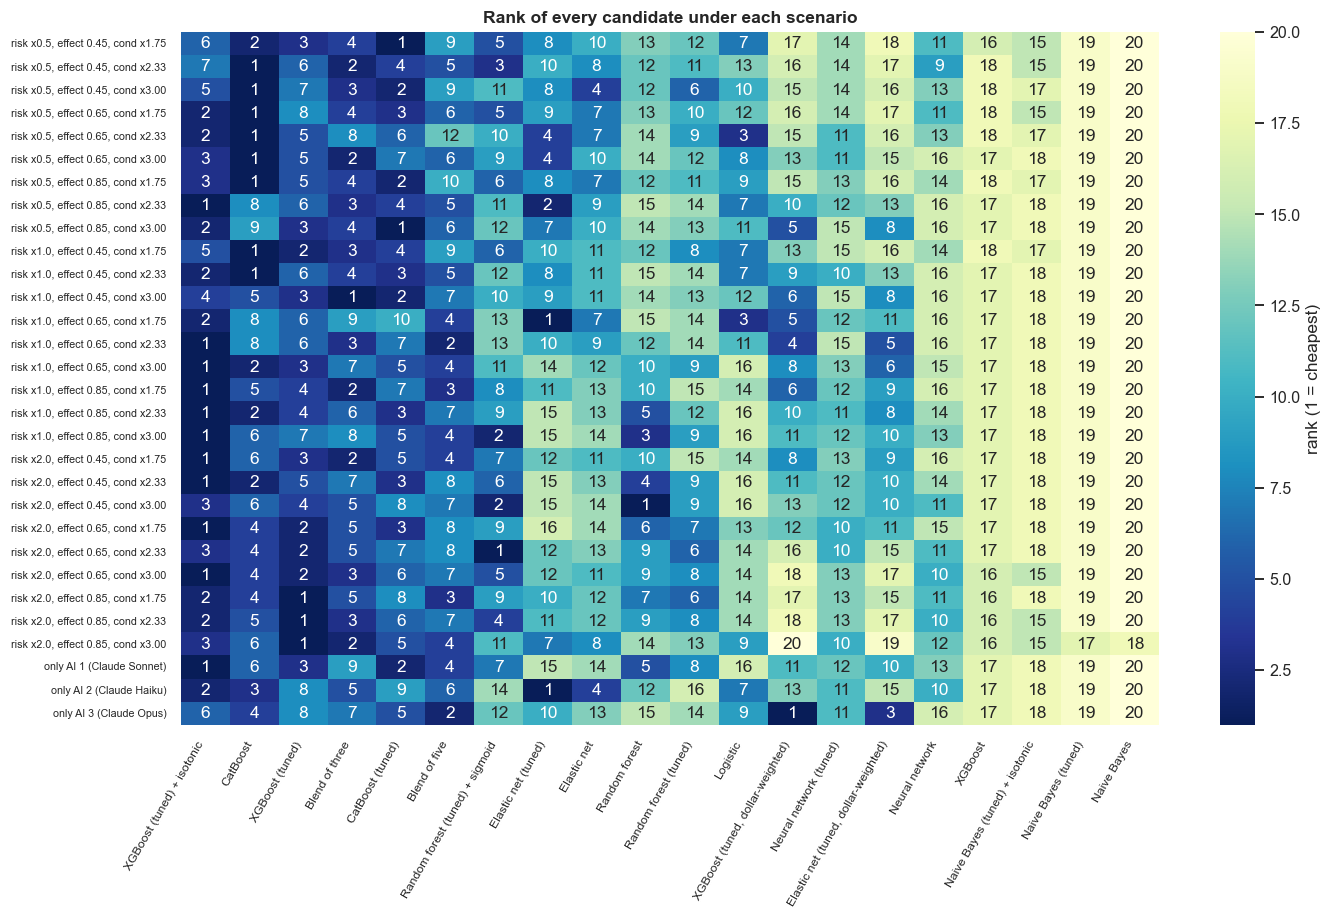

,base-case rank,mean rank over scenarios,worst rank,times in the top 5,times beaten by 'post to nobody'
XGBoost (tuned) + isotonic,1.0,2.50,7.0,27,0
Blend of five,2.0,6.03,12.0,13,0
Blend of three,3.0,4.50,9.0,22,0
"XGBoost (tuned, dollar-weighted)",4.0,11.73,20.0,4,1
"Elastic net (tuned, dollar-weighted)",5.0,12.43,19.0,2,1
XGBoost (tuned),6.0,4.30,8.0,20,0
CatBoost (tuned),7.0,4.77,10.0,19,0
CatBoost,8.0,3.90,9.0,21,0
Elastic net,9.0,10.40,14.0,2,0
Elastic net (tuned),10.0,9.63,16.0,5,0


In [ ]:
scenarios = {}
for scale in (0.5, 1.0, 2.0):
    for effect in (0.45, 0.65, 0.85):
        for mult in (1.75, BASE["per_condition"], 3.0):
            scenarios[f"risk x{scale}, effect {effect}, cond x{mult:.2f}"] = (
                {"age_risk": BASE["age_risk"], "vaccine_effect": effect, "per_condition": mult}, scale)
for ai, row in AI_ANSWERS.iterrows():
    scenarios[f"only {ai}"] = (assumptions_from(row), 1.0)

stress = {}
for label, (assume, scale) in scenarios.items():
    ru_s, rv_s = hospital_risk(train, assume, scale)
    cut_s = personal_cutoff(ru_s, rv_s)
    stress[label] = {n: fold_bills(decisions(n, PROBS[n], cut_s), ru_s, rv_s).mean() for n in SPECS}
    stress[label]["post to nobody"] = fold_bills(np.zeros((N_REPEATS, len(y)), bool), ru_s, rv_s).mean()
stress = pd.DataFrame(stress).T                                            # scenarios x candidates

ranks = stress[list(SPECS)].rank(axis=1)                                   # 1 = cheapest in that scenario
order = ranks.mean().sort_values().index
fig, ax = plt.subplots(figsize=(13, 8.5))
sns.heatmap(ranks[order], annot=True, fmt=".0f", cmap="YlGnBu_r", cbar_kws={"label": "rank (1 = cheapest)"}, ax=ax)
ax.set_title("Rank of every candidate under each scenario")
ax.tick_params(axis="x", labelsize=8, rotation=60); ax.tick_params(axis="y", labelsize=7)
plt.setp(ax.get_xticklabels(), ha="right")
plt.tight_layout(); plt.show()

robust = pd.DataFrame({"base-case rank": league["bill $/resident"].rank(),
                       "mean rank over scenarios": ranks.mean(), "worst rank": ranks.max(),
                       "times in the top 5": (ranks <= 5).sum(),
                       "times beaten by 'post to nobody'": (stress[list(SPECS)].gt(stress["post to nobody"], axis=0)).sum()})
robust.sort_values("base-case rank").round(2)

* **The leader is also the most robust candidate**: its average rank over the 30 scenarios is 2.5, it is never worse than 7th, and it is in the top five in 27 scenarios. Tuned XGBoost, both CatBoost versions and the blend of three follow with average ranks between about 4 and 5.
* **The ordinary probability models never lose to "post to nobody"** in any scenario, because their cut-offs adapt to the assumptions. Only the over-confident ones (default XGBoost once, uncalibrated Naive Bayes several times) do, in the low-risk scenarios where a wasted dose is hardest to justify.
* **The two dollar-weighted models are the least robust of our leading group** (average rank about 12, and each loses to "post to nobody" in one scenario). This is by construction: their decisions were trained for the base assumptions and cannot adapt. In the base case they are tied with the others, which is why they are files 4 and 5 and not higher.
* Running the test with **each AI's own numbers** changes the order inside the leading group but not its membership.

What the stress test cannot tell us is which scenario the markers will use. If the true hospital risks are much higher than our AI average, every one of our files posts too few vaccines; if lower, too many. That risk is shared by all five files and is the largest uncertainty in the project (Q9.1).

### Q6.7 Would more data help?
The learning curve of the leading single model: log loss on training data and on unseen data as the training set grows.

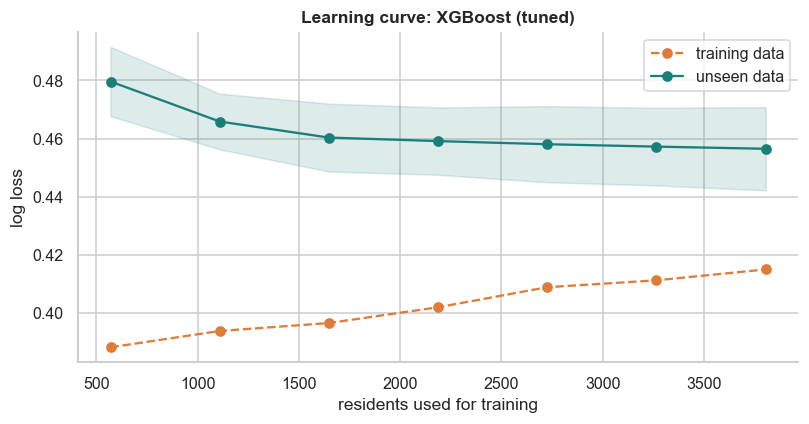

In [ ]:
curve_name = next(n for n in league.index if SPECS[n]["kind"] == "probability" and "+" not in n)
sizes, train_scores, valid_scores = learning_curve(SPECS[curve_name]["make"](), X, y, cv=inner, scoring="neg_log_loss",
                                                   train_sizes=np.linspace(0.15, 1.0, 7), n_jobs=N_JOBS)
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(sizes, -train_scores.mean(axis=1), "o--", color=ORANGE, label="training data")
ax.plot(sizes, -valid_scores.mean(axis=1), "o-", color=TEAL, label="unseen data")
ax.fill_between(sizes, -valid_scores.mean(axis=1) - valid_scores.std(axis=1),
                -valid_scores.mean(axis=1) + valid_scores.std(axis=1), color=TEAL, alpha=0.15)
ax.set_xlabel("residents used for training"); ax.set_ylabel("log loss"); ax.legend()
ax.set_title(f"Learning curve: {curve_name}")
plt.tight_layout(); plt.show()

The unseen-data curve falls quickly up to about 1,500 to 2,000 residents and is nearly flat afterwards, while a gap to the training curve remains. More residents of the same kind would improve the model only slightly. The limit is the information in the survey answers (people with identical answers still decide differently), not the amount of data or the size of the model. This is consistent with seven very different model families ending within about $1 of each other.

## Q7. What do we hand in?
### Q7.1 Choosing and ordering the five
The brief asks for five results that are **all different**, ordered best to worst by the task metric. The rule we follow:

1. Take the candidates in league-table order (mean bill over the 20 unseen folds, Q6.1). This is the order of the files.
2. Refit each chosen candidate on the **whole** training file and predict the test residents.
3. Skip a candidate if its test decisions are identical to a file already chosen, so that the five files really differ.

The stress test (Q6.6) and the paired comparison (Q6.2) are used to judge how firm this order is, not to change it.

In [ ]:
def fit_candidate(name, X_fit, y_fit):
    """Fit a candidate on the given residents. A blend returns the list of its fitted members."""
    spec = SPECS[name]
    if spec["kind"] == "blend":
        return [fit_candidate(m, X_fit, y_fit) for m in spec["members"]]
    model = spec["make"]()
    if spec["kind"] == "weighted":
        r_u, r_v = hospital_risk(X_fit)
        model.fit(X_fit, y_fit, model__sample_weight=dollar_weights(y_fit, r_u, r_v))
    else:
        model.fit(X_fit, y_fit)
    return model

def candidate_probability(name, fitted, X_new):
    """Model output for new residents (average of the members for a blend)."""
    if SPECS[name]["kind"] == "blend":
        return np.mean([candidate_probability(m, f, X_new) for m, f in zip(SPECS[name]["members"], fitted)], axis=0)
    return fitted.predict_proba(X_new)[:, 1]

def candidate_decision(name, fitted, X_new):
    """Post (1) or not (0) for new residents, using their own cut-offs."""
    q = candidate_probability(name, fitted, X_new)
    if SPECS[name]["kind"] == "weighted":
        return (q > 0.5).astype(int)
    r_u, r_v = hospital_risk(X_new)
    return (q > personal_cutoff(r_u, r_v)).astype(int)

t0 = time.time()
X_test = test[RAW]
FINAL, FITTED, TEST_SENT = [], {}, {}
for name in league.index:                                 # league order = best first
    fitted = fit_candidate(name, X, y)
    sent_test = candidate_decision(name, fitted, X_test)
    if any(np.array_equal(sent_test, TEST_SENT[other]) for other in FINAL):
        print(f"skipped (same test decisions as an earlier file): {name}")
        continue
    FINAL.append(name); FITTED[name] = fitted; TEST_SENT[name] = sent_test
    if len(FINAL) == 5:
        break
print(f"refitted on all {len(y):,} training residents in {time.time() - t0:.0f}s")
for i, name in enumerate(FINAL, 1):
    print(f"  {i}. {name}")

refitted on all 4,756 training residents in 17s
  1. XGBoost (tuned) + isotonic
  2. Blend of five
  3. Blend of three
  4. XGBoost (tuned, dollar-weighted)
  5. Elastic net (tuned, dollar-weighted)


### Q7.2 Writing and checking the files
The format is copied from `dataset_B_example_submission.csv`: columns `respondent_id` and `h1n1_vaccine`, the same ids in the same order, and the answer written as a decimal `0.0` / `1.0` like the example. File names follow the required pattern `challenge_submission_group_X_order_Y.csv`, and the files are written to the `submission/` folder so that the folder holds exactly what is uploaded to Canvas.

In [ ]:
SUBMISSION_DIR = "submission"                              # the five files for Canvas go in this folder
os.makedirs(SUBMISSION_DIR, exist_ok=True)

rows = []
for order, name in enumerate(FINAL, 1):
    out = example.copy()
    out[TARGET] = TEST_SENT[name].astype(example[TARGET].dtype)          # 0.0 / 1.0 like the example file
    name_csv = f"challenge_submission_group_{GROUP_ID}_order_{order}.csv"
    path = os.path.join(SUBMISSION_DIR, name_csv)
    out.to_csv(path, index=False)

    # read the file back and check it against the example
    back = pd.read_csv(path)
    assert list(back.columns) == list(example.columns), "column names differ from the example"
    assert back[ID].equals(example[ID]), "ids differ from the example"
    assert back[TARGET].dtype == example[TARGET].dtype and back[TARGET].isin([0, 1]).all(), "answers must be 0.0 / 1.0"
    assert len(back) == len(test) == 4749
    b = BILLS[name]
    rows.append({"order": order, "file": name_csv, "model": name, "cv bill $/resident": round(b.mean(), 3),
                 "cv std": round(b.std(), 3), "cv saving vs nobody $": round(nobody_folds.mean() - b.mean(), 3),
                 "posted in cv %": round(100 * decisions(name, PROBS[name]).mean(), 2),
                 "posted in test %": round(100 * back[TARGET].mean(), 2),
                 "vaccines posted in test": int(back[TARGET].sum())})
ranking = pd.DataFrame(rows)
ranking.to_csv("ranking.csv", index=False)

# the five files must all be different, and none may be a copy of the example file
for i in range(5):
    assert not np.array_equal(TEST_SENT[FINAL[i]], example[TARGET].to_numpy()), "a file equals the example"
    for j in range(i + 1, 5):
        assert not np.array_equal(TEST_SENT[FINAL[i]], TEST_SENT[FINAL[j]]), "two files are identical"
assert ranking["cv bill $/resident"].is_monotonic_increasing, "files are not ordered best to worst"
print("all checks passed: 5 files, example format, all different, ordered by cross-validated bill")
ranking

all checks passed: 5 files, example format, all different, ordered by cross-validated bill


,order,file,model,cv bill $/resident,cv std,cv saving vs nobody $,posted in cv %,posted in test %,vaccines posted in test
0,1,challenge_submission_group_I_order_1.csv,XGBoost (tuned) + isotonic,393.228,6.205,24.862,17.45,17.88,849
1,2,challenge_submission_group_I_order_2.csv,Blend of five,393.261,5.813,24.829,14.95,15.65,743
2,3,challenge_submission_group_I_order_3.csv,Blend of three,393.478,5.891,24.612,15.53,16.05,762
3,4,challenge_submission_group_I_order_4.csv,"XGBoost (tuned, dollar-weighted)",393.537,6.464,24.553,16.30,16.87,801
4,5,challenge_submission_group_I_order_5.csv,"Elastic net (tuned, dollar-weighted)",393.541,6.528,24.549,16.43,16.66,791


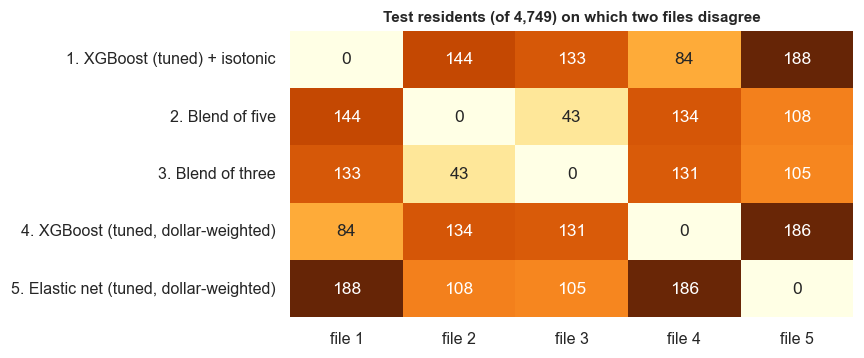

XGBoost (tuned) + isotonic             expects $ 391.14 per test resident by its own probabilities


Blend of five                          expects $ 394.64 per test resident by its own probabilities
Blend of three                         expects $ 394.11 per test resident by its own probabilities


In [ ]:
# how different are the five files? number of test residents on which two files disagree
differ = pd.DataFrame([[int((TEST_SENT[a] != TEST_SENT[b]).sum()) for b in FINAL] for a in FINAL],
                      index=[f"{i}. {n}" for i, n in enumerate(FINAL, 1)], columns=[f"file {i}" for i in range(1, 6)])
fig, ax = plt.subplots(figsize=(8, 3.4))
sns.heatmap(differ, annot=True, fmt="d", cmap="YlOrBr", cbar=False, ax=ax)
ax.set_title(f"Test residents (of {len(test):,}) on which two files disagree", fontsize=10)
plt.tight_layout(); plt.show()

# each model's own estimate of its test bill, for information only (it cannot be used to rank)
ru_t, rv_t = hospital_risk(X_test)
for name in FINAL:
    if SPECS[name]["kind"] != "weighted":
        q = candidate_probability(name, FITTED[name], X_test)
        s = TEST_SENT[name]
        own = (VACCINE_COST * np.where(s == 1, 1, q) + HOSPITAL_COST * (ru_t - s * q * (ru_t - rv_t))).mean()
        print(f"{name:38s} expects ${own:7.2f} per test resident by its own probabilities")

The five files post between 743 and 849 vaccines to the 4,749 test residents (about 16 to 18%, in line with the share posted in cross-validation, which is another sign that the test file behaves like the training file). They are genuinely different: any two files disagree on between 43 and 188 residents. Files 2 and 3 (the two blends) are the most alike, files 1 and 5 the least.

**Why this order.** Files are ordered by the mean bill over 20 unseen folds, the direct estimate of the task metric. File 1 is also the most robust candidate under the stress test (Q6.6). The paired test (Q6.2) says the five are statistically tied, so the order between them on the hidden set may differ from ours; what we are confident about is that all five beat the simple policies by about $24 to $25 per resident.

The five files are in the `submission/` folder, ready for Canvas. `ranking.csv` records, for each file, the model, its cross-validated bill, its spread and how many vaccines it posts.

## Q8. Why do the models decide the way they do?
*This part is the first version made during the hackathon. The brief allows explainability work and figure polishing to continue afterwards; no model is changed here.*

Four methods are used, and each is applied to **every one of the five submitted models**:

| Method | Question it answers | Works for |
|---|---|---|
| Q8.1 Permutation importance in dollars | how much more would the town pay if the model could no longer use this answer? | all five |
| Q8.2 Shapley values (SHAP) | how does each answer push one resident's prediction up or down? | all five (explainer chosen per model type) |
| Q8.3 Partial dependence | how does the predicted acceptance change as one answer changes? | all five |
| Q8.4 Surrogate decision tree | can the final post / don't post decision be written as a few simple rules? | all five |

To keep the explanations honest, the models are refitted on 75% of the training file and explained on the remaining 25%, which they have not seen.

In [ ]:
t0 = time.time()
fit_idx, hold_idx = train_test_split(np.arange(len(y)), test_size=0.25, stratify=y, random_state=SEED)
X_fit, y_fit, X_hold, y_hold = X.iloc[fit_idx], y[fit_idx], X.iloc[hold_idx], y[hold_idx]
ru_h, rv_h = RU[hold_idx], RV[hold_idx]
XAI_MODELS = {name: fit_candidate(name, X_fit, y_fit) for name in FINAL}
SHORT = {name: f"{i}. {name}" for i, name in enumerate(FINAL, 1)}

holdout = pd.Series({SHORT[n]: town_bill(y_hold, candidate_decision(n, XAI_MODELS[n], X_hold), ru_h, rv_h) for n in FINAL})
print(f"hold-out bills (post to nobody = ${town_bill(y_hold, np.zeros_like(y_hold), ru_h, rv_h):.2f}):")
print(holdout.round(2).to_string()); print(f"({time.time() - t0:.0f}s)")

hold-out bills (post to nobody = $421.90):
1. XGBoost (tuned) + isotonic              395.76
2. Blend of five                           396.77
3. Blend of three                          397.22
4. XGBoost (tuned, dollar-weighted)        396.37
5. Elastic net (tuned, dollar-weighted)    397.32
(16s)


### Q8.1 Permutation importance, measured in dollars
One answer at a time is shuffled between the hold-out residents, which breaks its link with everything else, and the bill is recomputed. The rise in the bill is what that answer is worth to the town. Each answer is shuffled 10 times. The residents' real age and conditions are still used for the cut-off and the bill; only what the model sees is shuffled.

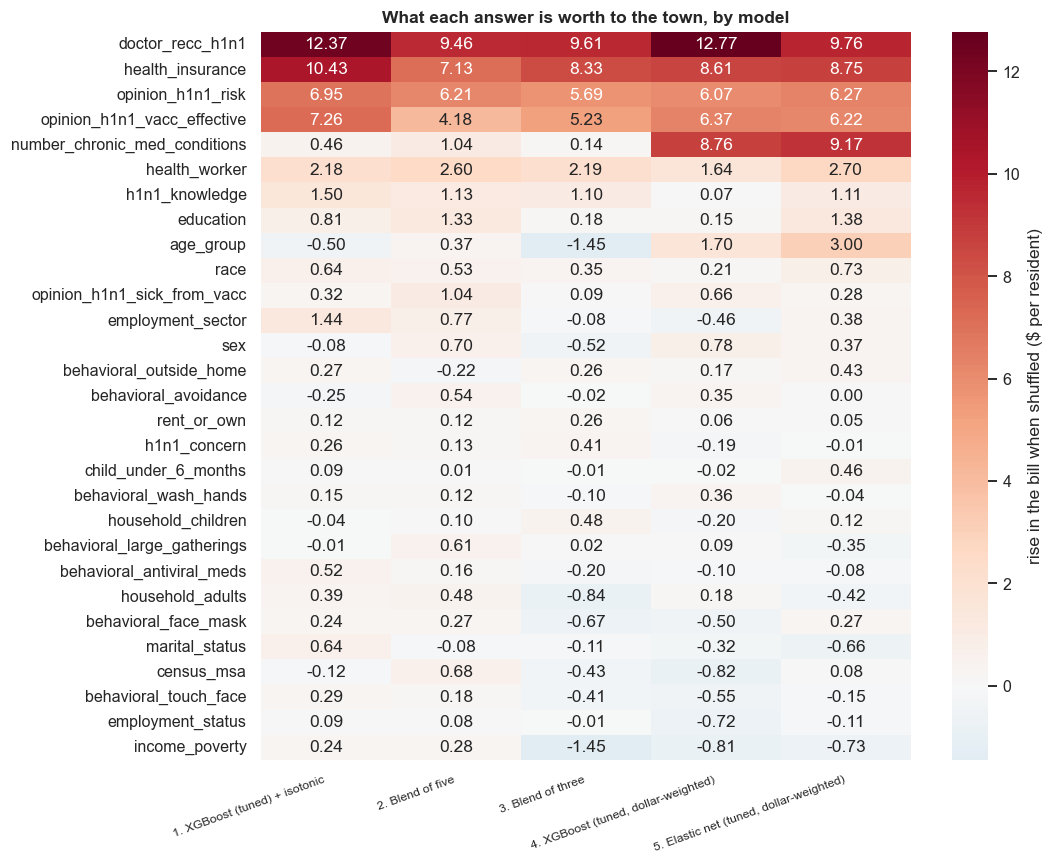

(27s)   agreement between models (Spearman rank correlation of the columns):
                                         1. XGBoost (tuned) + isotonic  2. Blend of five  3. Blend of three  4. XGBoost (tuned, dollar-weighted)  5. Elastic net (tuned, dollar-weighted)
1. XGBoost (tuned) + isotonic                                     1.00              0.57               0.59                                 0.38                                     0.47
2. Blend of five                                                  0.57              1.00               0.44                                 0.61                                     0.65
3. Blend of three                                                 0.59              0.44               1.00                                 0.49                                     0.62
4. XGBoost (tuned, dollar-weighted)                               0.38              0.61               0.49                                 1.00                                   

In [ ]:
def dollar_importance(name, fitted, n_repeats=10):
    """Mean rise in the hold-out bill ($ per resident) when one survey answer is shuffled."""
    rng = np.random.default_rng(SEED)
    base = town_bill(y_hold, candidate_decision(name, fitted, X_hold), ru_h, rv_h)
    cut_h = personal_cutoff(ru_h, rv_h)
    weighted = SPECS[name]["kind"] == "weighted"
    out = {}
    for col in RAW:
        rises = []
        for _ in range(n_repeats):
            shuffled = X_hold.copy()
            shuffled[col] = rng.permutation(shuffled[col].to_numpy())
            q = candidate_probability(name, fitted, shuffled)
            rises.append(town_bill(y_hold, q > (0.5 if weighted else cut_h), ru_h, rv_h) - base)
        out[col] = np.mean(rises)
    return pd.Series(out)

t0 = time.time()
importance = pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(dollar_importance)(n, XAI_MODELS[n]) for n in FINAL),
                          index=[SHORT[n] for n in FINAL]).T
importance = importance.loc[importance.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(importance, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax,
            cbar_kws={"label": "rise in the bill when shuffled ($ per resident)"})
ax.set_title("What each answer is worth to the town, by model"); ax.tick_params(axis="x", labelsize=8, rotation=20)
plt.setp(ax.get_xticklabels(), ha="right")
plt.tight_layout(); plt.show()
print(f"({time.time() - t0:.0f}s)   agreement between models (Spearman rank correlation of the columns):")
print(importance.corr(method="spearman").round(2).to_string())

* **All five models rely on the same four answers.** Losing the doctor's recommendation would cost the town about $9 to $13 per resident, health insurance about $7 to $10, the opinion about personal risk about $6 to $7 and the opinion about vaccine effectiveness about $4 to $7. Health-worker status follows at about $2. For comparison, the whole saving of the policy is about $25 per resident, so each of these answers carries a large part of it.
* **Everything else is at noise level.** Most of the remaining values are between -$1 and +$1 and change sign from model to model. A negative value does not mean an answer is harmful; it means its effect is too small to measure on about 1,200 hold-out residents. This is also why the rank correlations between models are only moderate (about 0.4 to 0.7): the ranks of twenty near-zero answers are essentially random.
* **One real difference between the model types:** `number_chronic_med_conditions` is worth about $9 to the two dollar-weighted models and almost nothing to the other three. This is not a disagreement about who accepts a vaccine. The ordinary models use chronic conditions *outside* the model, in the cut-off; the dollar-weighted models had to learn the money side inside the model, and chronic conditions are what sets the money. `age_group` shows the same pattern more weakly.

A caution on the method: shuffling one answer breaks its link with related answers (for example the doctor's recommendation and the combined feature built from it), so importance can be shared out differently between correlated answers than the model really uses them. That is one reason to look at a second method.

### Q8.2 Shapley values
SHAP splits one resident's prediction into a contribution from each answer, relative to the average prediction. How it is computed depends on the model:

| Model type | Explainer |
|---|---|
| XGBoost, random forest | `TreeExplainer` (exact for trees) |
| CatBoost | CatBoost's built-in SHAP values (exact) |
| Logistic regression / elastic net | `LinearExplainer` (exact for linear models) |
| Neural network | `PermutationExplainer` on the encoded inputs (model-agnostic, approximate) |
| Calibrated model | the calibrator holds five copies of the underlying model; their SHAP values are averaged. Isotonic calibration only re-maps the score without changing the order of residents, so this explains what drives the ranking |
| Blend | no single set of SHAP values, because a blend averages probabilities; we report the average of its members' importance profiles |

To compare models whose outputs are on different scales, each model's mean |SHAP| per question is turned into a **share of its total** (the shares of one model add up to 1). One-hot columns are added back together per original question. SHAP is computed for the first 300 hold-out residents to keep the model-agnostic explainer fast.

SHAP computed for all 5 submitted models on 300 hold-out residents (8s)


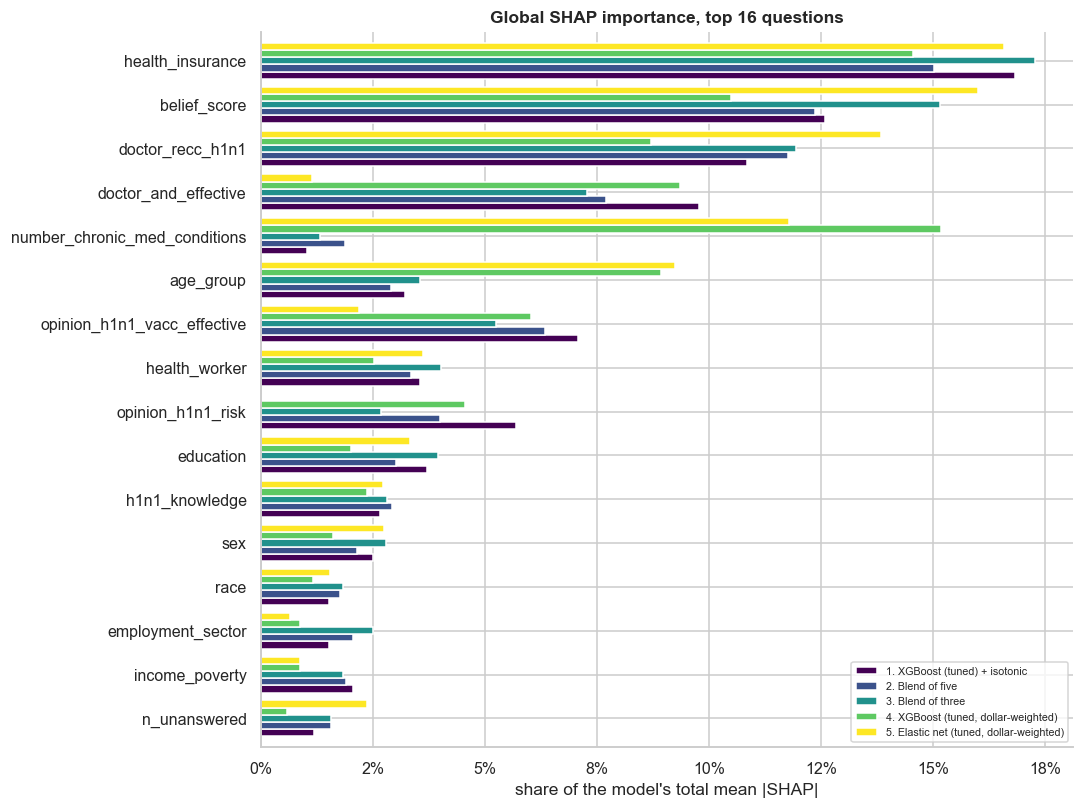

In [ ]:
EXPLAIN = X_hold.iloc[:300]                                # residents explained with SHAP
log_odds = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))

def source_question(column):
    """Map an encoded column name (e.g. 'race_White', 'missingindicator_health_insurance') to its question."""
    column = column.replace("missingindicator_", "")
    for q in sorted(RAW + ENGINEERED, key=len, reverse=True):
        if column == q or column.startswith(q + "_"):
            return q
    return column

def single_shap(pipeline, frame):
    """SHAP values (residents x questions) for one fitted pipeline; None if it has no 'encode' step."""
    model = pipeline.named_steps["model"]
    if isinstance(model, CalibratedClassifierCV):           # average over the five underlying pipelines
        parts = [single_shap(c.estimator, frame) for c in model.calibrated_classifiers_]
        return None if any(p is None for p in parts) else sum(parts) / len(parts)
    if isinstance(model, CatBoostModel):
        from catboost import Pool
        data = pipeline[:-1].transform(frame)
        values = model.booster_.get_feature_importance(Pool(data, cat_features=CAT), type="ShapValues")[:, :-1]
        return pd.DataFrame(values, columns=data.columns, index=frame.index)
    if "encode" not in pipeline.named_steps:
        return None
    encoded = np.asarray(pipeline[:-1].transform(frame))
    columns = pipeline.named_steps["encode"].get_feature_names_out()
    values = None
    if isinstance(model, LogisticRegression):
        values = shap.LinearExplainer(model, np.asarray(pipeline[:-1].transform(X_fit))).shap_values(encoded)
    elif isinstance(model, (XGBClassifier, RandomForestClassifier)):
        try:
            values = shap.TreeExplainer(model).shap_values(encoded)
            if isinstance(values, list):
                values = values[1]
            if np.ndim(values) == 3:                      # one layer per class: keep "takes the vaccine"
                values = values[:, :, 1]
        except Exception:                                 # e.g. missing values not supported for this tree type
            values = None
    if values is None:                                    # model-agnostic route (neural network and fall-back)
        background = np.asarray(pipeline[:-1].transform(X_fit.sample(60, random_state=SEED)))
        explainer = shap.PermutationExplainer(lambda z: log_odds(model.predict_proba(z)[:, 1]), background, seed=SEED)
        values = explainer(encoded, max_evals=2 * encoded.shape[1] + 1, silent=True).values
    per_column = pd.DataFrame(values, columns=columns, index=frame.index)
    return per_column.T.groupby(source_question).sum().T              # one-hot pieces back to one question

def shap_profile(name, fitted, frame):
    """(values or None, share of total mean |SHAP| per question). Blends: average of the members' shares."""
    if SPECS[name]["kind"] == "blend":
        shares = [shap_profile(m, f, frame)[1] for m, f in zip(SPECS[name]["members"], fitted)]
        return None, pd.concat(shares, axis=1).fillna(0).mean(axis=1)
    values = single_shap(fitted, frame)
    strength = values.abs().mean()
    return values, strength / strength.sum()

t0 = time.time()
SHAP_VALUES, SHAP_SHARE = {}, {}
for name in FINAL:
    SHAP_VALUES[name], SHAP_SHARE[name] = shap_profile(name, XAI_MODELS[name], EXPLAIN)
print(f"SHAP computed for all {len(FINAL)} submitted models on {len(EXPLAIN)} hold-out residents ({time.time() - t0:.0f}s)")

shap_share = pd.DataFrame({SHORT[n]: SHAP_SHARE[n] for n in FINAL}).fillna(0)
shap_share = shap_share.loc[shap_share.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(10, 7.5))
shap_share.head(16)[::-1].plot(kind="barh", ax=ax, width=0.82, colormap="viridis")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("share of the model's total mean |SHAP|"); ax.set_title("Global SHAP importance, top 16 questions")
ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

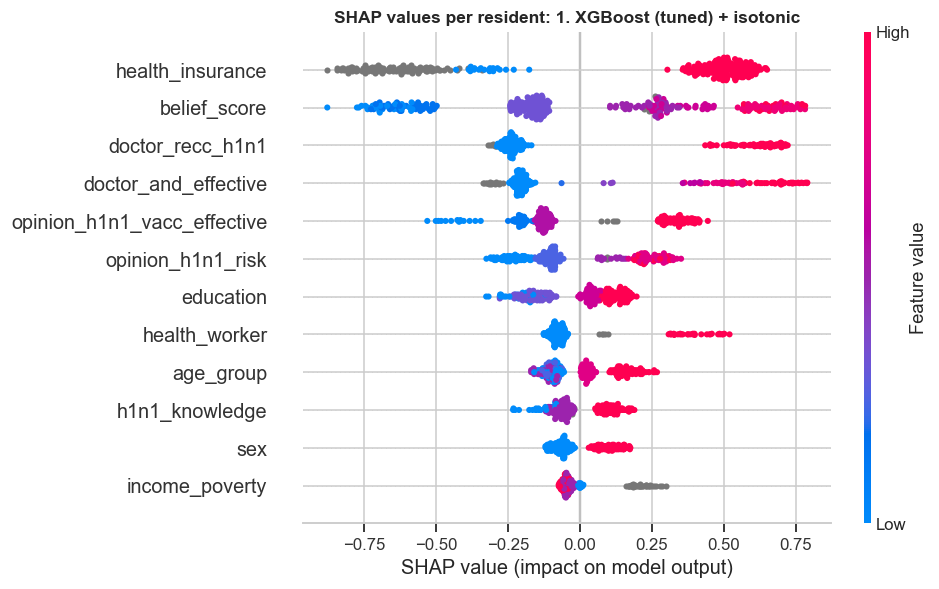

,rank correlation (29 questions),top six in common,SHAP top three,dollar top three
model,,,,
1. XGBoost (tuned) + isotonic,0.58,5,"health_insurance, belief_score, doctor_recc_h1n1","doctor_recc_h1n1, health_insurance, opinion_h1n1_vacc_effective"
2. Blend of five,0.78,6,"health_insurance, belief_score, doctor_recc_h1n1","doctor_recc_h1n1, health_insurance, opinion_h1n1_risk"
3. Blend of three,0.34,4,"health_insurance, belief_score, doctor_recc_h1n1","doctor_recc_h1n1, health_insurance, opinion_h1n1_risk"
"4. XGBoost (tuned, dollar-weighted)",0.57,6,"number_chronic_med_conditions, health_insurance, belief_score","doctor_recc_h1n1, number_chronic_med_conditions, health_insurance"
"5. Elastic net (tuned, dollar-weighted)",0.53,4,"health_insurance, belief_score, doctor_recc_h1n1","doctor_recc_h1n1, number_chronic_med_conditions, health_insurance"


In [ ]:
# direction of the effects for the best-ranked single model: one dot per explained resident
shap_name = next(n for n in FINAL if SHAP_VALUES[n] is not None)
values = SHAP_VALUES[shap_name]
top = values.abs().mean().sort_values(ascending=False).head(12).index.tolist()
shown = add_features(EXPLAIN)[top].copy()
for c in top:                                             # colour needs numbers: text answers -> ordered codes
    if shown[c].dtype == object:
        shown[c] = shown[c].map({v: i for i, v in enumerate(ORDERED.get(c, sorted(shown[c].dropna().unique())))})
shap.summary_plot(values[top].to_numpy(), shown, feature_names=top, show=False, plot_size=(9, 5.5))
plt.title(f"SHAP values per resident: {SHORT[shap_name]}", fontweight="bold")
plt.tight_layout(); plt.show()

# do SHAP and the dollar importance agree? rank correlation over the 29 questions, and overlap of the top six
rows = []
for name in FINAL:
    share = SHAP_SHARE[name].reindex(RAW).fillna(0)
    dollars = importance[SHORT[name]].reindex(RAW)
    rows.append({"model": SHORT[name], "rank correlation (29 questions)": stats.spearmanr(share, dollars)[0],
                 "top six in common": len(set(share.nlargest(6).index) & set(dollars.nlargest(6).index)),
                 "SHAP top three": ", ".join(SHAP_SHARE[name].nlargest(3).index),
                 "dollar top three": ", ".join(dollars.nlargest(3).index)})
pd.set_option("display.max_colwidth", 90)
pd.DataFrame(rows).set_index("model").round(2)

* **SHAP confirms the leading group of answers** for every model: health insurance, the belief score (our engineered sum of the two opinion scales), the doctor's recommendation and the doctor-and-effectiveness interaction. For the five models, four to six of the six most important questions are the same under SHAP and under dollar importance.
* **The engineered features earn their place.** `belief_score` and `doctor_and_effective` are among the top four SHAP features, which the permutation method cannot show because it shuffles the original questions.
* **Directions make sense** (per-resident plot): having health insurance, a doctor's recommendation, a high belief score and being a health worker all push the prediction up. The grey dots are residents who did not answer the health-insurance question: not answering pushes the prediction *down* even further than answering "no", the pattern first seen in Q2.2.
* **The two methods rank differently in the detail** (rank correlation over all 29 questions between about 0.3 and 0.8). They answer different questions: SHAP measures how much an answer moves the *predicted probability* of every resident, dollar importance measures how much it changes *decisions and money*, which only happens for residents near their cut-off. Health insurance is first under SHAP and second in dollars; the doctor's recommendation is the reverse.
* **The dollar-weighted models again stand apart**: chronic conditions and age take a large share of their SHAP total, for the reason given in Q8.1.

Limits: SHAP for the calibrated model explains its underlying score, not the calibrated probability; the blends are summarised by averaging their members' profiles; and the neural network inside the blend of five is explained with an approximate, sampling-based explainer.

### Q8.3 Partial dependence: how one answer moves the prediction
For each of the four answers with the largest dollar importance, every hold-out resident's answer is set to each possible value in turn and the average predicted acceptance is recorded. One line per submitted model, so that the models can be compared directly. This needs only predictions, so it works for all five. Solid lines are predicted acceptance probabilities; the dashed lines are the two dollar-weighted models, whose output is a money-weighted score that is cut at 0.5.

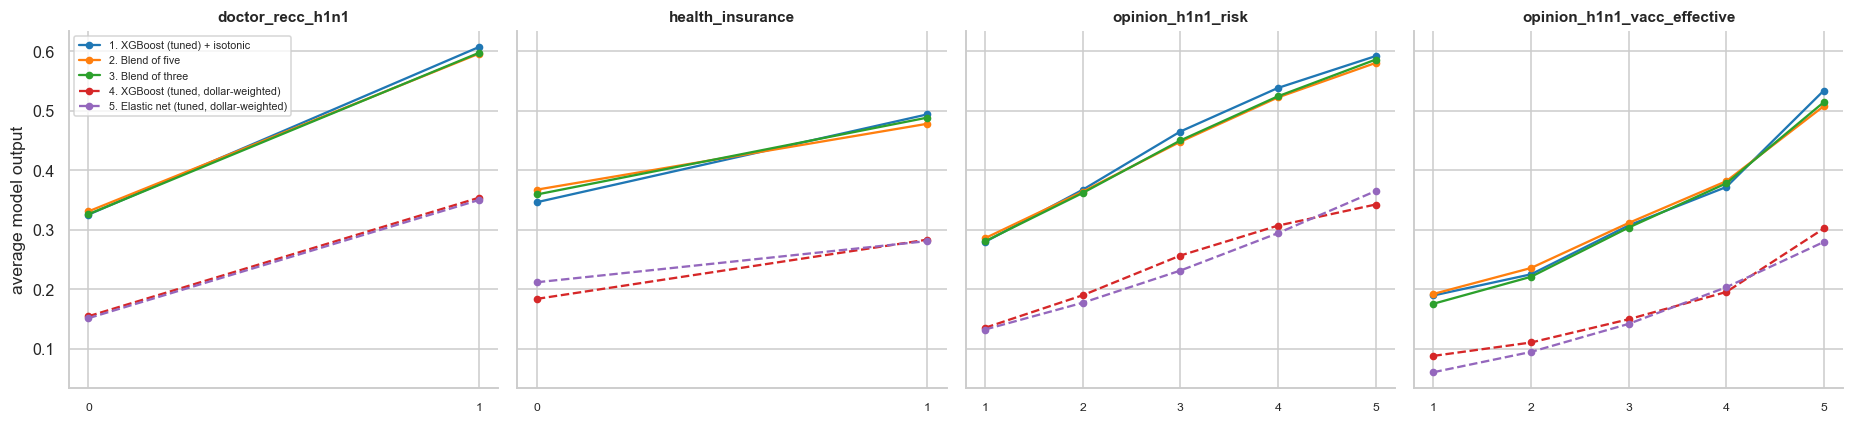

In [ ]:
def partial_dependence_curve(name, fitted, column):
    """Average predicted acceptance when every hold-out resident is given the same answer to one question."""
    levels = ORDERED.get(column, sorted(X_hold[column].dropna().unique()))
    means = []
    for level in levels:
        changed = X_hold.copy()
        changed[column] = level
        means.append(candidate_probability(name, fitted, changed).mean())
    return levels, means

top4 = importance.mean(axis=1).sort_values(ascending=False).head(4).index.tolist()
fig, axes = plt.subplots(1, 4, figsize=(17, 4), sharey=True)
for ax, column in zip(axes, top4):
    for name, colour in zip(FINAL, sns.color_palette("tab10", 5)):
        levels, means = partial_dependence_curve(name, XAI_MODELS[name], column)
        # a dollar-weighted model outputs a weighted score (cut at 0.5), not a probability: drawn dashed
        ax.plot(range(len(levels)), means, "o--" if SPECS[name]["kind"] == "weighted" else "o-",
                color=colour, label=SHORT[name], ms=4)
    ax.set_xticks(range(len(levels)))
    ax.set_xticklabels([str(int(l)) if isinstance(l, (int, float, np.integer, np.floating)) else str(l)[:10] for l in levels],
                       rotation=45 if len(levels) > 6 else 0, fontsize=8)
    ax.set_title(column, fontsize=10)
axes[0].set_ylabel("average model output"); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

The three probability models (solid lines) are almost on top of each other, and the two dollar-weighted models (dashed) run parallel to them at a lower level, since their output is a money-weighted score rather than a probability. All five therefore learnt the same relationships:

* a doctor's recommendation raises the average predicted acceptance from about 0.33 to about 0.60, the largest single step;
* health insurance raises it from about 0.35 to about 0.49;
* both opinion scales rise steadily, with the steepest step between "somewhat" and "very" effective (4 to 5).

Partial dependence changes one answer while leaving the others as they are, which can create unrealistic residents (for example a doctor's recommendation for someone who believes the vaccine is useless), so the curves describe the model, not what would happen if the town persuaded doctors to recommend the vaccine to everyone.

### Q8.4 The decision as simple rules
A shallow decision tree (depth 3) is trained to imitate each submitted model's **final decision** on the hold-out residents, using the survey answers. *Fidelity* is how often the tree's rule agrees with the model on residents the tree did not see (5-fold). A high fidelity means the policy can be explained to a non-expert in a few sentences; a low one means the model is doing something that simple rules cannot capture.

,posted on hold-out %,fidelity (agreement) %,balanced fidelity %,first split
model,,,,
1. XGBoost (tuned) + isotonic,17.8,87.4,88.3,doctor_and_effective
2. Blend of five,15.2,86.0,88.1,doctor_and_effective
3. Blend of three,16.2,86.5,87.4,doctor_and_effective
"4. XGBoost (tuned, dollar-weighted)",16.9,84.7,88.0,doctor_and_effective
"5. Elastic net (tuned, dollar-weighted)",17.4,84.4,86.9,doctor_and_effective


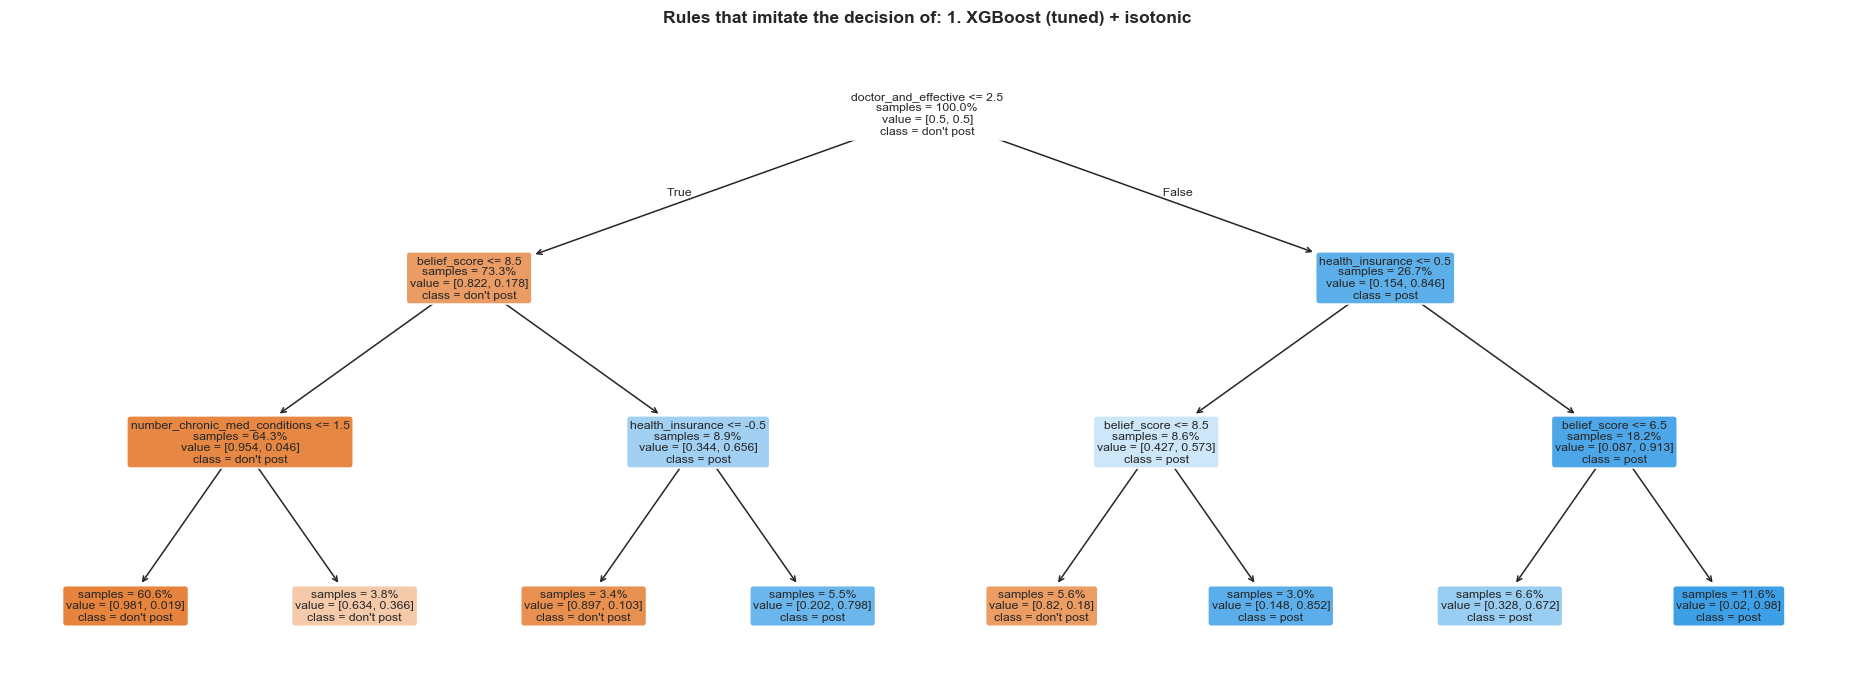

In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import balanced_accuracy_score

def tree_ready(frame):
    """Numbers only: engineered features added, text as ordered codes, gaps as -1."""
    d = add_features(frame)
    for c, levels in zip(CAT, CAT_LEVELS):
        d[c] = d[c].map({v: i for i, v in enumerate(levels)})
    return d.fillna(-1)

T_hold = tree_ready(X_hold)
rows, SURROGATES = [], {}
for name in FINAL:
    target = candidate_decision(name, XAI_MODELS[name], X_hold)
    tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=15, class_weight="balanced", random_state=SEED)
    guess = cross_val_predict(tree, T_hold, target, cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
    SURROGATES[name] = tree.fit(T_hold, target)
    rows.append({"model": SHORT[name], "posted on hold-out %": 100 * target.mean(),
                 "fidelity (agreement) %": 100 * (guess == target).mean(),
                 "balanced fidelity %": 100 * balanced_accuracy_score(target, guess),
                 "first split": T_hold.columns[SURROGATES[name].tree_.feature[0]]})
display(pd.DataFrame(rows).set_index("model").round(1))

fig, ax = plt.subplots(figsize=(17, 6.5))
plot_tree(SURROGATES[FINAL[0]], feature_names=T_hold.columns.tolist(), class_names=["don't post", "post"],
          filled=True, rounded=True, impurity=False, proportion=True, fontsize=8, ax=ax)
ax.set_title(f"Rules that imitate the decision of: {SHORT[FINAL[0]]}", fontweight="bold")
plt.tight_layout(); plt.show()

Three questions in a row reproduce each model's post / don't post decision for about 84 to 87% of unseen residents (balanced over both outcomes: 87 to 88%). All five surrogate trees start with the same split, on `doctor_and_effective`.

Reading the tree for file 1 from the top: a resident **without** a doctor's recommendation combined with a good opinion of the vaccine is almost never posted a vaccine, unless their belief score is very high and they answered the health-insurance question. A resident **with** that combination is usually posted one if they have health insurance, and otherwise only if their belief score is high. Chronic conditions appear lower down, where they tip borderline cases.

The remaining 13 to 16% of decisions are not captured by these rules. Those are the borderline residents, where the exact probability and the personal cut-off matter, and they are the reason a full model is still worth having. The tree is an explanation aid, not a replacement: used as the policy itself it would give up part of the saving.

### Q8.5 Three residents, explained
A local view for the best-ranked single model: one resident who is posted a vaccine, one who is likely to accept but is **not** posted one (because their hospital saving is too small), and one who is clearly not posted one.

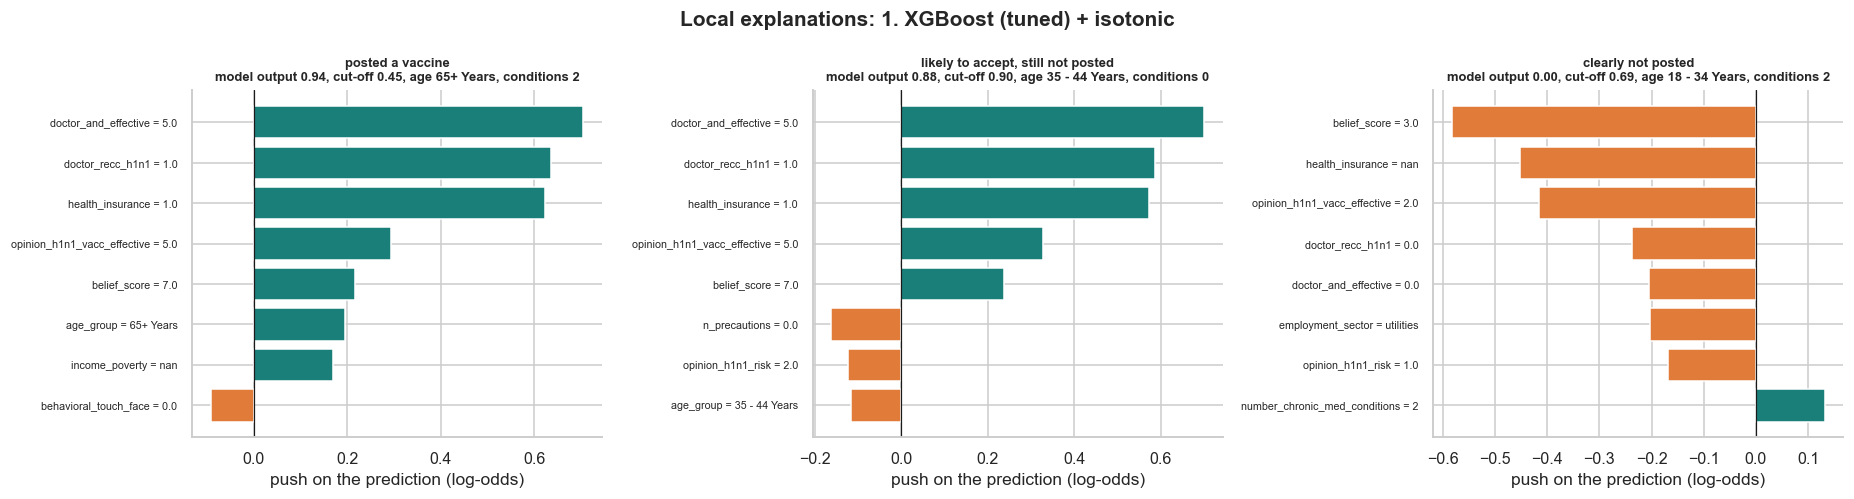

In [ ]:
q_hold = candidate_probability(shap_name, XAI_MODELS[shap_name], EXPLAIN)
cut_hold = personal_cutoff(ru_h[:len(EXPLAIN)], rv_h[:len(EXPLAIN)])
if SPECS[shap_name]["kind"] == "weighted":
    cut_hold = np.full_like(cut_hold, 0.5)
posted = q_hold > cut_hold
picks = {"posted a vaccine": int(np.argmax(np.where(posted, q_hold - cut_hold, -9))),
         "likely to accept, still not posted": int(np.argmax(np.where(~posted, q_hold, -9))),
         "clearly not posted": int(np.argmin(q_hold))}

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, (label, i) in zip(axes, picks.items()):
    contrib = SHAP_VALUES[shap_name].iloc[i].sort_values(key=abs, ascending=False).head(8)[::-1]
    answers = add_features(EXPLAIN.iloc[[i]]).iloc[0]
    ax.barh([f"{c} = {answers[c]}" for c in contrib.index], contrib.values,
            color=[TEAL if v > 0 else ORANGE for v in contrib.values])
    ax.axvline(0, color="k", lw=0.8); ax.tick_params(axis="y", labelsize=7)
    ax.set_title(f"{label}\nmodel output {q_hold[i]:.2f}, cut-off {cut_hold[i]:.2f}, "
                 f"age {EXPLAIN.iloc[i]['age_group']}, conditions {int(EXPLAIN.iloc[i]['number_chronic_med_conditions'])}",
                 fontsize=8.5)
    ax.set_xlabel("push on the prediction (log-odds)")
plt.suptitle(f"Local explanations: {SHORT[shap_name]}", fontweight="bold")
plt.tight_layout(); plt.show()